# 19 · Optimiseurs — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookIA/blob/main/chapitres/ch19_optimiseurs/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wb.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | 19.Q1 à 19.Q12, 19.R1 à 19.R3, 19.1 à 19.6, 19.9 | vérifier tes réponses courtes | 🧠 🔁 ✏️ 🧮 | ★ à ★★ | |
| A | 19.14 | Pas constant sur une vallée : combien de pas pour le fond ? | 🔮 | ★ | 15 |
|  | 19.15 | Plannings : exponential_decay_lr, step_decay_lr, bold_driver_lr | 🔨 | ★ | 15 |
|  | 19.16 | SGD, Momentum et Nesterov à la manière de torch.optim | 🔨 | ★★ | 30 |
|  | 19.17 | Adagrad, RMSprop et Adadelta | 🔨 | ★★ | 30 |
|  | 19.18 | Adam et AdamW | 🔨 | ★★ | 30 |
|  | 19.19 | Warmup + cosinus et gradient clipping | 🔨 | ★★ | 25 |
| B | 19.20 | Trop de momentum : la bille quitte-t-elle la vallée ? | 🔮 | ★★ | 15 |
|  | 19.21 | Reproduire les figures du chapitre : pas constant, décroissant, momentum, Nesterov | 🎨 | ★★ | 30 |
|  | 19.22 | Chasse au bug : un Adam qui diverge | 🐛 | ★★ | 25 |
| C | 19.23 | Diagnostiquer des courbes de loss d'optimiseurs | 📈 | ★★ | 20 |
|  | 19.24 | Les solveurs de MLPClassifier : sgd, momentum, adaptive, adam | 📦 | ★★ | 25 |
|  | 19.25 | Batch, stochastique, mini-batch sur les lunes | 🔬 | ★★★ | 45 |
| D | 19.26 | Course d'optimiseurs sur la fonction de Rosenbrock | 🔬 | ★★★ | 45 |
|  | 19.27 | Huit optimiseurs sur MNIST, avec warmup, cosinus et clipping | 🔬 | ★★★ | 60 |
|  | 19.28 | Défi : 98 % sur MNIST en cinq epochs | 🏆 | ★★★ | 90 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (CPU, a few minutes); False = full version
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookIA.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookIA")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WB_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wb").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wb").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier du workbook.")

os.environ["WB_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wb  # noqa: E402

cfg = wb.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mylearn = wb.load_mylearn("ref")  # reference implementation

🧪 Deep Learning Workbook : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.13 | numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0 | scikit-learn 1.6.1 | scipy 1.16.3 | torch 2.11.0+cpu | torchvision 0.26.0+cpu
   Device : cpu | Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Calculer à la main les premiers pas d'un planning, du momentum, de Nesterov, d'Adagrad, de RMSprop et d'Adam.
- Écrire et vérifier contre `torch.optim` les optimiseurs et les plannings de `mylearn.optim`.
- Comparer des optimiseurs sur des vallées, sur la fonction de Rosenbrock et sur MNIST, et défendre un choix.

**Rappel express** (conventions de PyTorch, $g$ le gradient, $t$ compté à partir de 1). Momentum : $b = \mu b + g$ ($b_1 = g_1$), $w \leftarrow w - \eta b$ ; Nesterov : $w \leftarrow w - \eta(g + \mu b)$ ; Adagrad : $s \leftarrow s + g^2$, $w \leftarrow w - \eta g/(\sqrt{s} + \epsilon)$ ; RMSprop : $v \leftarrow \alpha v + (1 - \alpha) g^2$, $w \leftarrow w - \eta g/(\sqrt{v} + \epsilon)$ ; Adam : $m \leftarrow \beta_1 m + (1 - \beta_1) g$, $v \leftarrow \beta_2 v + (1 - \beta_2) g^2$, $w \leftarrow w - \eta\,\frac{m/(1 - \beta_1^t)}{\sqrt{v/(1 - \beta_2^t)} + \epsilon}$ ; AdamW : $w \leftarrow w(1 - \eta\lambda)$ puis le pas d'Adam. Plannings : $\eta_0\gamma^k$, $\eta_0\gamma^{\lfloor k/s \rfloor}$, warmup $\eta_{\max} t/T_w$ puis cosinus.

## Partie 0 · Vérifier tes réponses courtes (quiz, rappels, ✏️ 19.1 à 19.6 et 🧮 19.9)

Fais d'abord les quiz, les rappels et les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse courte ici : **la valeur** que tu as trouvée, pas l'expression Python, sinon tu ne vérifies rien. Un nombre : `42` ou `0.3` (en Python, le séparateur décimal est un **point** ; `0,3` sans guillemets serait un couple de deux nombres) ; un vrai ou faux : `True` ou `False` ; un choix : la lettre seule, entre guillemets (`"E"`) ; une forme : entre guillemets (`"(3, 5)"`). Arrondis comme l'énoncé le demande, et seulement à la fin du calcul. Les réponses pas encore remplies affichent ⏳. Les questions « dans ta copie », les preuves ∂ 19.7 et 19.8, la réflexion (🗣️ 19.10, ⚖️ 19.11, 📄 19.12, 🛠️ 19.13) et l'entretien se corrigent avec `05_solutions.md`.

In [2]:
# The short answers only use the numbers of their statements (02_exercices.md)
import math


def momentum_torch_192(lrs, mu=0.9, w=1.0):
    """PyTorch momentum on L(w) = w**2 (gradient 2w): b1 = g1, b = mu b + g, w -= lr * b."""
    b = None
    for lr in lrs:
        g = 2 * w
        b = g if b is None else mu * b + g
        w = w - lr * b
    return w


def momentum_book_192(lrs, gamma=0.9, w=1.0):
    """The book's momentum: delta = gamma * delta - lr * g, w += delta."""
    delta = 0.0
    for lr in lrs:
        delta = gamma * delta - lr * 2 * w
        w = w + delta
    return w


def nesterov_book_193(steps, lr=0.1, mu=0.9, w=1.0):
    """Look-ahead Nesterov (the book, Sutskever et al.): returns the list of (look-ahead, gradient, w, v)."""
    v, out = 0.0, []
    for _ in range(steps):
        look = w + mu * v
        g = 2 * look
        v = mu * v - lr * g
        w = w + v
        out.append((look, g, w, v))
    return out


def nesterov_torch_193(steps, lr=0.1, mu=0.9, p=1.0):
    """PyTorch's Nesterov: gradient at the current point, p -= lr * (g + mu * b)."""
    b, out = None, []
    for _ in range(steps):
        g = 2 * p
        b = g if b is None else mu * b + g
        p = p - lr * (g + mu * b)
        out.append(p)
    return out


GRADS_194 = [3.0, -1.0, 2.0]


def adagrad_194(lr=0.1):
    s, w, out = 0.0, 0.0, []
    for g in GRADS_194:
        s += g * g
        w -= lr * g / math.sqrt(s)
        out.append((s, w))
    return out


def rmsprop_194(lr=0.1, alpha=0.9):
    v, w, out = 0.0, 0.0, []
    for g in GRADS_194:
        v = alpha * v + (1 - alpha) * g * g
        w -= lr * g / math.sqrt(v)
        out.append((v, w))
    return out


def adam_195(grads, lr=0.01, b1=0.9, b2=0.999, w=1.0):
    """Adam with eps = 0: returns the list of (m, v, m_hat, v_hat, w) after each step."""
    m = v = 0.0
    out = []
    for t, g in enumerate(grads, start=1):
        m = b1 * m + (1 - b1) * g
        v = b2 * v + (1 - b2) * g * g
        m_hat, v_hat = m / (1 - b1**t), v / (1 - b2**t)
        w -= lr * m_hat / math.sqrt(v_hat)
        out.append((m, v, m_hat, v_hat, w))
    return out


SIZES_199 = [3072, 512, 256, 10]
P_199 = sum(a * b + b for a, b in zip(SIZES_199[:-1], SIZES_199[1:]))
W_199 = sum(a * b for a, b in zip(SIZES_199[:-1], SIZES_199[1:]))      # weights only, without the biases

**19.Q1 — Qu'appelle-t-on un optimiseur ?**

In [3]:
wb.record("19.Q1a", False, mistakes={"relis le chapeau de la fiche : qui calcule les gradients ?": True})
wb.record("19.Q1b", "B", mistakes={"les données ont déjà servi à la passe avant et à la passe arrière": "A",
          "les labels servent à calculer la loss, avant la passe arrière": "C",
          "l'architecture ne change pas d'un pas à l'autre : que faut-il à une règle comme w ← w − η g ?": "D"})
wb.record("19.Q1c", True, mistakes={"au même point, de quoi dépend le gradient : du réseau, des données et des poids, ou de l'optimiseur ?": False})
wb.record("19.Q1d", "B", mistakes={"backward() calcule les gradients, il ne touche pas aux poids": "A",
          "zero_grad() remet les gradients à zéro avant la passe arrière suivante": "C",
          "eval() change le mode du modèle (dropout, batchnorm), pas ses poids": "D"})

WB_ANSWER {"hash": "8e4e3e8b3023524cc7069beb0ba575f7bb1838c3a42e4e606eb7574663e415f6", "id": "19.Q1a", "kind": "bool", "mistakes": {"47158cae042a430056aa8b14d934052355b69e8e9876132bf85f49ce2acedf59": "relis le chapeau de la fiche : qui calcule les gradients ?"}}
📝 Ex 19.Q1a : réponse enregistrée (bool).
WB_ANSWER {"hash": "270ec520b8bbcb4b205360b39a373cb9578e5ba58c5e859c33f05f921d93758a", "id": "19.Q1b", "kind": "str", "mistakes": {"2a7b83deac4658b2b0abee5775afe123e5c2149d07068b6581347331983f6a07": "les labels servent à calculer la loss, avant la passe arrière", "4e3c944de5cad2dc11ad52696f516201b1dda62ae9b4a0b7fb85d3bc7062aefb": "les données ont déjà servi à la passe avant et à la passe arrière", "898aea6d49fc2aac716852711aa233525adbe79d1a4b82a11ce99154c520e966": "l'architecture ne change pas d'un pas à l'autre : que faut-il à une règle comme w ← w − η g ?"}}
📝 Ex 19.Q1b : réponse enregistrée (str).
WB_ANSWER {"hash": "0070ef33cdd0eedfbbf665dc345642911c622f03c57ea507a149304ec120f9b2", 

**19.Q2 — Minimum, maximum, plateau, selle : où le gradient s'annule-t-il ?**

In [4]:
wb.record("19.Q2a", "A", mistakes={"x² + 3y² : monte-t-il ou descend-il quand on s'éloigne de 0 ?": "B",
          "les deux coefficients ont-ils des signes contraires ?": "C",
          "la fonction n'est pas constante autour de 0": "D"})
wb.record("19.Q2b", "C", mistakes={"regarde le signe du coefficient de y²": "A", "regarde le signe du coefficient de x²": "B",
          "cette fonction n'est pas constante autour de 0": "D"})
wb.record("19.Q2c", "B", mistakes={"regarde le signe des deux coefficients": "A",
          "les deux coefficients ont-ils des signes contraires ?": "C",
          "cette fonction-là n'est pas constante autour de 0": "D"})
wb.record("19.Q2d", "D", mistakes={"une fonction constante monte-t-elle quand on s'éloigne du point ?": "A",
          "une fonction constante descend-elle quand on s'éloigne du point ?": "B",
          "une fonction constante a-t-elle des directions qui montent et d'autres qui descendent ?": "C"})
wb.record("19.Q2e", True, mistakes={"écris le pas η g avec g = 0 : les poids bougent-ils ?": False})

WB_ANSWER {"hash": "229609243f70928c22436772f8ee2fac8aed1272f2b083d5128f9a9479f9defd", "id": "19.Q2a", "kind": "str", "mistakes": {"4603f534a5e38423337b874e09b5b247a7f1aaf12a924bc928c547fbdcf7baee": "x² + 3y² : monte-t-il ou descend-il quand on s'éloigne de 0 ?", "5cff3b5c18074dabfcdb7301e1ba0be11cfb76d03a8f772e55dbb26342fb63f0": "les deux coefficients ont-ils des signes contraires ?", "7187c8d61b7c54c80a8464ab848900139b308bc69bc23a33639a3439b9ee18f4": "la fonction n'est pas constante autour de 0"}}
📝 Ex 19.Q2a : réponse enregistrée (str).
WB_ANSWER {"hash": "76bd42114ae6ca67f691cb26cd2a3d4a5cf0ffffc3f92c8b3d49485d66cebb6a", "id": "19.Q2b", "kind": "str", "mistakes": {"10f4d0c4c159a0c1f1d1b2e3ad2bfa5145c85384a876b6155ca54a58b6385dc4": "regarde le signe du coefficient de x²", "514d38566617ca53b9b0f8a11fad63e4c8bca812cc60200c8f637690c93add89": "cette fonction n'est pas constante autour de 0", "b271ff4e2eec7b6d82ec6abc4840afd518a933f025b49d418d2f88dedfe4e35f": "regarde le signe du coeffic

**19.Q3 — Minima locaux ou points selles : le vrai piège en grande dimension**

In [5]:
wb.record("19.Q3a", "B", mistakes={"relis la fin du §19.2.1 : la thèse de Dauphin et coll. porte sur un autre type de point": "A",
          "les maxima sont aussi rares que les minima dans ce raisonnement": "C",
          "rien à voir avec les arrondis : relis la fin du §19.2.1": "D"})
wb.record("19.Q3b", 2**10, fractional="« 1 sur combien » : un nombre entier (pas une probabilité)",
          mistakes={"une chance sur deux pour CHAQUE direction : on multiplie les probabilités": 10,
          "une chance sur deux pour chacune des 10 directions, toutes doivent monter": 512,
          "on multiplie les probabilités, on ne les additionne pas": 20,
          "une chance sur deux par direction, pas une sur dix": 100,
          "compte toutes les configurations de signes, celle du minimum comprise": 1023})
wb.record("19.Q3c", True, mistakes={"que devient la probabilité d'un minimum quand d grandit ? Et celle d'un maximum ?": False})
wb.record("19.Q3d", True, mistakes={"une selle a des directions qui descendent : une petite poussée au hasard peut-elle en trouver une ?": False})

WB_ANSWER {"hash": "430c4b1906680a39df84540e195b7b2886c178758d61b061ad51e85364e33399", "id": "19.Q3a", "kind": "str", "mistakes": {"1c513f5448c37a22de96565f001ed69789ca7332566b3c20bb7e7f4106b28a61": "les maxima sont aussi rares que les minima dans ce raisonnement", "202a7e18ead05ae6ac48c576613e93aaae08d8a4aed4accab6de9d90695b1ecc": "relis la fin du §19.2.1 : la thèse de Dauphin et coll. porte sur un autre type de point", "7edc7bf4981c99bccf3f5a51deb6461dab5e709a816e0c08d8dded73bde9a711": "rien à voir avec les arrondis : relis la fin du §19.2.1"}}
📝 Ex 19.Q3a : réponse enregistrée (str).
WB_ANSWER {"fractional": "« 1 sur combien » : un nombre entier (pas une probabilité)", "hash": "3e8ae81b869e52aa5d6dcf6443244f65d1662017da054d57ffba6155094c1afb", "id": "19.Q3b", "kind": "int", "magnitude": 3, "mistakes": {"004a9ec779fe2d84e21f5a411a0356ef36aa8b13aa644ee0725c5b5cbc7ed173": "une chance sur deux par direction, pas une sur dix", "0f2af57e906fd83d9c0235469733071a28f0cd647b003694700cf4024caf

**19.Q4 — Pourquoi lisser une erreur de comptage ?**

In [6]:
wb.record("19.Q4a", True, mistakes={"le nombre d'erreurs change-t-il quand le seuil se déplace entre deux points ?": False})
wb.record("19.Q4b", True, mistakes={"quelle est la pente d'une fonction constante ?": False})
wb.record("19.Q4c", "B", mistakes={"lisser ne rend pas le calcul plus rapide : que manque-t-il à la descente sur un escalier ?": "A",
          "un lissage ne supprime pas forcément les minima locaux": "C",
          "le problème n'est pas la valeur au minimum, c'est la pente ailleurs": "D"})
wb.record("19.Q4d", "B", mistakes={"l'accuracy compte des erreurs : elle est en escalier": "A",
          "un nombre de faux positifs est un comptage": "C",
          "le F1 se calcule à partir de comptages": "D"})

WB_ANSWER {"hash": "ff44dbd11cb1353098bd0c0eedbaa720d81b2ea6bd18b4c6e69d9981afd32af0", "id": "19.Q4a", "kind": "bool", "mistakes": {"125ca9b012abc38356acf50b0c252282d04b1b0bc2bec8c8ce2c39395d388107": "le nombre d'erreurs change-t-il quand le seuil se déplace entre deux points ?"}}
📝 Ex 19.Q4a : réponse enregistrée (bool).
WB_ANSWER {"hash": "b39a3fd3b69b0d6560868e5c0c6578c6391375d76b68fa7649e5f34507f5d1ba", "id": "19.Q4b", "kind": "bool", "mistakes": {"005d35873b32c8b3884d02b218661c1d7b9fde16347619d1ad769fec4a502df6": "quelle est la pente d'une fonction constante ?"}}
📝 Ex 19.Q4b : réponse enregistrée (bool).
WB_ANSWER {"hash": "1ebbc4435f15a2f521ef8c27782f049c4d98e0f065147840ae9f8759bb2e9a3c", "id": "19.Q4c", "kind": "str", "mistakes": {"7b18c996182249d902502f33b07714837c72ff8952084152a76fa2384ff4d20e": "lisser ne rend pas le calcul plus rapide : que manque-t-il à la descente sur un escalier ?", "9cd2ccff70a77093823a62b66b4fe7e5d3d63caa20d06251fdff4dbb574fae56": "un lissage ne supprim

**19.Q5 — Pas constant : pourquoi rebondit-on au fond de la vallée ?**

In [7]:
wb.record("19.Q5a", 1 - 10 * 0.15, decimals=2, mistakes={"regarde le signe de 1 − 10η": 0.5,
          "L(w) = 5w² : sa dérivée vaut 10w, la courbure est 10": 0.25,
          "le facteur dépend de la courbure, pas seulement de η": 0.85})
wb.record("19.Q5b", True, mistakes={"le facteur de a) est-il positif ou négatif ?": False})
wb.record("19.Q5c", "D", mistakes={"calcule 1 − 10 × 0,25 : est-il positif ?": "A",
          "compare la valeur absolue du facteur à 1": "B",
          "le facteur vaut-il exactement −1 ?": "C"})
wb.record("19.Q5d", "C", mistakes={"calcule 1 − 10 × 0,2 : est-il positif ?": "A",
          "un facteur de module exactement 1 rapproche-t-il du fond ?": "B",
          "un facteur de module exactement 1 fait-il grandir l'écart ?": "D"})
wb.record("19.Q5e", True, mistakes={"pour quels η le module du facteur est-il strictement inférieur à 1 ?": False})

WB_ANSWER {"decimals": 2, "hash": "79b60a1c291906bbe029821a6c19096fbad7a69f1f2b1097ff5aa5123fdcd66c", "hash_coarse": "ceb6d3556f2aacbdb0ce8c0220af1f0c88b5bc7070946195c094c10905fad0cf", "id": "19.Q5a", "kind": "float", "magnitude": -1, "mistakes": {"424b7a22d67843e53bea2d0bca2922f4c17ae524ab93e0c2d9804c8b73797e23": "regarde le signe de 1 − 10η", "53c9983ced13a5f1bbf772854231e40ac4eeb356af4ef621873ba08665eaee56": "le facteur dépend de la courbure, pas seulement de η", "c6515efc39cd38d67302d61d64612728ef14aca66b3d522a53a8e2834727932b": "L(w) = 5w² : sa dérivée vaut 10w, la courbure est 10"}, "sign": -1}
📝 Ex 19.Q5a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"hash": "c7bce4fd813ce5ac15250efc9284e7b90ffe897abfb24c8d2c2478f6aee4b42a", "id": "19.Q5b", "kind": "bool", "mistakes": {"3e3bb3ee3c4b99983f9a3db3f6469ab3683b2d17f8d162be5e1ac0344b96c24b": "le facteur de a) est-il positif ou négatif ?"}}
📝 Ex 19.Q5b : réponse enregistrée (bool).
WB_ANSWER {"hash": "44074624d7f3d40b4aec693

**19.Q6 — Décroissance exponentielle : que vaut η après 50 pas ?**

In [8]:
wb.record("19.Q6a", 0.1 * 0.99**50, decimals=4, mistakes={"50 multiplications : la puissance est 50": 0.1 * 0.99**49,
          "50 multiplications, pas 51": 0.1 * 0.99**51,
          "une décroissance exponentielle multiplie, elle ne soustrait pas": 0.05,
          "n'oublie pas η0 = 0,1": 0.99**50})
wb.record("19.Q6b", math.ceil(math.log(0.5) / math.log(0.99)), fractional="un nombre de multiplications : un entier, le premier qui convient",
          mistakes={"après ce nombre de multiplications, η est-il déjà sous la moitié de η0 ?": 68,
          "le PREMIER nombre de multiplications qui convient": 70,
          "relis a) : après 50 multiplications, est-on déjà sous la moitié ?": 50})
wb.record("19.Q6c", "B", mistakes={"calcule 0,8 puissance 10, puis son inverse": "A", "calcule 0,8 puissance 10 : est-ce si petit ?": "C",
          "0,8 puissance 10 n'est pas si petit : refais le calcul": "D"})
wb.record("19.Q6d", True, mistakes={"une série géométrique de raison strictement inférieure à 1 converge-t-elle ?": False})
wb.record("19.Q6e", 0.1 / (1 - 0.99), decimals=2, mistakes={"n'oublie pas η0 = 0,1": 100.0,
          "divise par 1 − γ, pas par γ": 0.1 / 0.99,
          "la somme d'une série géométrique divise par 1 − γ, elle ne multiplie pas": 0.001,
          "η0 = 0,1 multiplie la somme : n'oublie pas sa valeur": 1000.0})

WB_ANSWER {"decimals": 4, "hash": "475ac43e73c72595459e1e86587b2397c3c55d9c17d27dcdfafecf8953c5c9c2", "hash_coarse": "b990f544e2748f4cdf69d7f02eafd5470dff56d791eabbec1f72d9273cbc310b", "id": "19.Q6a", "kind": "float", "magnitude": -2, "mistakes": {"2b4ce648b148b5ea3cd750ce4d4f126e29763b5680b25e652c0d232c0e57eae9": "50 multiplications : la puissance est 50", "89278c974b7d04d474fe8f5b057db6094209b7315711dd55f2922aa2938980f7": "50 multiplications, pas 51", "b2a7a43b4346e780b7189f93e986b4ecbd545a1cafed1c7a7db6b55a5fcf6428": "une décroissance exponentielle multiplie, elle ne soustrait pas", "f1049c13ca7b5952221a930d125733312e53cf8746c03c088b62ca51e0f58a36": "n'oublie pas η0 = 0,1"}, "sign": 1}
📝 Ex 19.Q6a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"fractional": "un nombre de multiplications : un entier, le premier qui convient", "hash": "68dc8b8e0627da09f85716d01d7e37bd2737a4083d9d699261a2e47a2016ba0b", "id": "19.Q6b", "kind": "int", "magnitude": 1, "mistakes": {"0b143a6d23339

**19.Q7 — Plannings : exponentiel, retardé, par paliers, sur l'erreur, bold driver**

In [9]:
wb.record("19.Q7a", "C", mistakes={"η baisse-t-il à chaque epoch, ou toutes les 10 ?": "A", "y a-t-il un délai au départ ?": "B",
          "ici, c'est le calendrier qui décide, pas la loss": "D", "η ne monte jamais dans cette règle": "E"})
wb.record("19.Q7b", "B", mistakes={"que se passe-t-il pendant les 5 premières epochs ?": "A",
          "η baisse-t-il par marches, ou à chaque epoch une fois lancé ?": "C",
          "ici, c'est le calendrier qui décide : la loss n'intervient pas": "D",
          "η ne monte jamais dans cette règle-là": "E"})
wb.record("19.Q7c", "D", mistakes={"ici, c'est la loss qui décide, pas un calendrier": "A",
          "ici, c'est la loss qui décide, pas un délai": "B",
          "pas de calendrier fixe dans cette règle": "C",
          "η peut-il monter dans cette règle ?": "E"})
wb.record("19.Q7d", "E", mistakes={"η augmente parfois : un planning exponentiel le fait-il ?": "A",
          "η augmente parfois : un planning retardé le fait-il ?": "B",
          "η augmente parfois : un planning par paliers le fait-il ?": "C",
          "η augmente parfois : le planning sur l'erreur le fait-il ?": "D"})
wb.record("19.Q7e", "C", mistakes={"StepLR suit un calendrier fixe": "A", "ExponentialLR multiplie à chaque epoch, quoi qu'il arrive": "B",
          "CosineAnnealingLR suit une courbe fixée d'avance": "D"})
wb.record("19.Q7f", True, mistakes={"relis l'encadré 🕰️ du §19.3.3 : en quoi se comptent les plannings d'aujourd'hui ?": False})

WB_ANSWER {"hash": "5dc69c6bd37be5adcb6085ebe5a06bc5b65e3ac656d180c11ad04e61387e66fd", "id": "19.Q7a", "kind": "str", "mistakes": {"0e296e5a78c14870a336a121cee55664c6c1d2e845b89a7f30fe8c2fcf6c524b": "η baisse-t-il à chaque epoch, ou toutes les 10 ?", "1e21de552002911d0dfd7ed5d6b12e8c1bb25caa17105212e53e37be057faee4": "ici, c'est le calendrier qui décide, pas la loss", "8489c07a16b36aacb3bd4111f6b8440fcb30e9475a17a85ba553a1c43089e37c": "y a-t-il un délai au départ ?", "ac79b8eddc4eb22466f6c4199a44e1e5a6cbc4084ced7e4a521bf98b275e357a": "η ne monte jamais dans cette règle"}}
📝 Ex 19.Q7a : réponse enregistrée (str).
WB_ANSWER {"hash": "1c17fc1351203cbcd5be520d75ddb09e40d707735c3e068aacb829c92c625826", "id": "19.Q7b", "kind": "str", "mistakes": {"0fc5d64eec8345951b6a380fd53b60755d4799b284a3deaa9083c497606d9ed9": "η ne monte jamais dans cette règle-là", "549141b7e625ad29c86c05eb3da2a3f53fd04320716b754bcb17450d15cb6d57": "que se passe-t-il pendant les 5 premières epochs ?", "b8f64b522aa6f49d3

**19.Q8 — Batch, stochastique, mini-batch : compter les mises à jour**

In [10]:
wb.record("19.Q8a", 1, mistakes={"le batch, c'est tout le dataset : combien de mises à jour par epoch ?": 1200,
          "chaque epoch fait au moins une mise à jour": 0})
wb.record("19.Q8b", 1200, mistakes={"un exemple par mise à jour : combien de mises à jour pour 1 200 exemples ?": 1})
wb.record("19.Q8c", math.ceil(1200 / 64), fractional="un nombre de mises à jour : un entier (le dernier mini-batch, incomplet, compte aussi)",
          mistakes={"le dernier mini-batch, incomplet, compte aussi": 18,
          "combien de mini-batches de 64 dans 1 200 exemples ?": 64})
wb.record("19.Q8d", 50 * math.ceil(1200 / 64), mistakes={"le dernier mini-batch incomplet compte, à chaque epoch": 900,
          "ce sont des mini-batches de 64, pas des exemples isolés": 60000})
wb.record("19.Q8e", "B", mistakes={"la descente par batch a besoin de tous les exemples à chaque mise à jour": "A",
          "l'une des deux a besoin de garder tous les exemples": "C",
          "l'une des deux traite chaque exemple dès qu'il arrive": "D"})
wb.record("19.Q8f", False, mistakes={"une epoch de SGD et une epoch de batch font-elles le même nombre de mises à jour ?": True})

WB_ANSWER {"hash": "3cab1106ec13a9b7bb0c8f56556cd2abf5329ea7c72257b59f6521a5f58d4b00", "id": "19.Q8a", "kind": "int", "magnitude": 0, "mistakes": {"82a86437ac0d1c7252b4119d8c751fc1b431cca09140a706ee34546f373375f3": "chaque epoch fait au moins une mise à jour", "cdc9abd47f6279fc6dfa7b0688546d5f65d9b541ad260e5ab6a2ac609d9ae121": "le batch, c'est tout le dataset : combien de mises à jour par epoch ?"}, "sign": 1}
📝 Ex 19.Q8a : réponse enregistrée (int).
WB_ANSWER {"hash": "3973dcb411ccfac6c9ce736b427a8ee26079e14c2e3de0181207b4ee15fdf23e", "id": "19.Q8b", "kind": "int", "magnitude": 3, "mistakes": {"68ac15d6c951b2b342dc29ba1b573c9730ddf404baeebbecc5d88f6d6062d887": "un exemple par mise à jour : combien de mises à jour pour 1 200 exemples ?"}, "sign": 1}
📝 Ex 19.Q8b : réponse enregistrée (int).
WB_ANSWER {"fractional": "un nombre de mises à jour : un entier (le dernier mini-batch, incomplet, compte aussi)", "hash": "390e12ffa9d9791ce5880a57b141345765a377d934d7a50f070849e41a052ec5", "id": "1

**19.Q9 — Momentum : que se passe-t-il si γ = 0 ? si γ = 1 ?**

In [11]:
wb.record("19.Q9a", "A", mistakes={"avec μ = 0, b = g : le pas est-il nul ?": "B", "Adam a deux moyennes mobiles": "C",
          "μ = 0 ne change pas la stabilité de la descente ordinaire": "D"})
wb.record("19.Q9b", 1 / (1 - 0.9), decimals=1, mistakes={"b1 = 1, b2 = 1 + 0,9, b3 = 1 + 0,9 + 0,81… : la somme commence à 1": 9.0,
          "la vitesse s'accumule : déroule b2 et b3": 1.0,
          "c'est le coefficient μ, pas la limite de b": 0.9})
wb.record("19.Q9c", "B", mistakes={"avec μ = 1, b_t = b_(t−1) + 1 : s'approche-t-il d'une limite ?": "A",
          "on ajoute 1 à chaque pas : est-ce une croissance exponentielle ?": "C",
          "b change-t-il d'un pas à l'autre ?": "D"})
wb.record("19.Q9d", "B", mistakes={"b_t = b_(t−1) + 0 : la vitesse diminue-t-elle ?": "A",
          "rien ne change le signe de la vitesse quand le gradient est nul": "C"})
wb.record("19.Q9e", True, mistakes={"relis l'histoire de la bille sur le plateau (§19.5.1)": False})

WB_ANSWER {"hash": "28639036e3d88b09bb0bceb9882350cd3be040cc1a0c56dce30b16b7ab587924", "id": "19.Q9a", "kind": "str", "mistakes": {"1ddfaca57981eea2b3d6eb376624e2034ab831e9b66eb86c21b5b3c8bc6f45df": "Adam a deux moyennes mobiles", "344638fdf0cf4c31097344f18ec92a5bf1f781c7d78a4dbc38c0fa63ce3e3a37": "μ = 0 ne change pas la stabilité de la descente ordinaire", "af1435255bde62f8dbcb546516cc379ec14543e4ac42981938b5b43ef4ea3f03": "avec μ = 0, b = g : le pas est-il nul ?"}}
📝 Ex 19.Q9a : réponse enregistrée (str).
WB_ANSWER {"decimals": 1, "hash": "6cccd891ef3d37bc341581038571787cf33a710ae588239b45b1fae19912186f", "hash_coarse": "5fb32706bb6022062a3ac8fdd1fbad4e3644758a345f189665d8ad167b973bad", "id": "19.Q9b", "kind": "float", "magnitude": 1, "mistakes": {"22dce543125e26deea42e7aef07d1667897b3ef9a0fa4c7485f106504a686336": "b1 = 1, b2 = 1 + 0,9, b3 = 1 + 0,9 + 0,81… : la somme commence à 1", "bd69dddb7da2cb1867259c12811ff79b9d0077f4f5bc078634941826c7263c3f": "c'est le coefficient μ, pas la li

**19.Q10 — Nesterov : regarder là où l'on va**

In [12]:
wb.record("19.Q10a", "B", mistakes={"relis la formule du livre : où évalue-t-on ∇L ?": "A",
          "Nesterov regarde vers l'avant, pas en arrière": "C", "un seul gradient par pas": "D"})
wb.record("19.Q10b", False, mistakes={"compte les hyperparamètres de la formule de Nesterov": True})
wb.record("19.Q10c", True, mistakes={"relis la phrase sur le changement de variable (§19.5.2)": False})
wb.record("19.Q10d", "B", mistakes={"de l'autre côté du fond, dans quel sens pointe le gradient ?": "A",
          "le point anticipé a-t-il le même gradient que le point courant ?": "C",
          "le gradient s'ajoute à l'élan, il ne le remplace pas": "D"})

WB_ANSWER {"hash": "1fefac544a5de1273e0e4bb1f418e01d04761a947e61a3b48eb508ee309dca48", "id": "19.Q10a", "kind": "str", "mistakes": {"53477c9c9be65d8db819608df8bb29387eaabec237b9222f10509ab54b155d17": "relis la formule du livre : où évalue-t-on ∇L ?", "8a25c36299d474c34ec8a0a7b10157d8b1d0ed1d195c9ad8b452ea87f1f088c7": "un seul gradient par pas", "8c84652ad1cb59511ce9e2b53a86197450ecf36dc00123ddc43e63c13636c1e8": "Nesterov regarde vers l'avant, pas en arrière"}}
📝 Ex 19.Q10a : réponse enregistrée (str).
WB_ANSWER {"hash": "9be9da6af76a1f06fcd0387561523ac469995300f7de3adfab8a02dc17203280", "id": "19.Q10b", "kind": "bool", "mistakes": {"47966206ea5e20ab08e4743db69e67efcf8f48ab6a2754542b8e8f1dd4b7eaa5": "compte les hyperparamètres de la formule de Nesterov"}}
📝 Ex 19.Q10b : réponse enregistrée (bool).
WB_ANSWER {"hash": "181328715bfc9eb7a8ec51ac5159a1c70d0205bb2d3f189e65958d6ca6cef6c0", "id": "19.Q10c", "kind": "bool", "mistakes": {"2725ffba5cc433a016003b92cffdd305c53a6eebdfe894e15e9227a0cc

**19.Q11 — Adagrad, Adadelta, RMSprop : un learning rate par poids**

In [13]:
wb.record("19.Q11a", True, mistakes={"chaque poids a-t-il son propre accumulateur ?": False})
wb.record("19.Q11b", "A", mistakes={"relis la formule d'Adagrad : oublie-t-il ses anciens gradients ?": "B",
          "le learning rate d'Adagrad est fixe : d'où vient le rétrécissement ?": "C",
          "le carré efface le signe : relis ce qu'on ajoute à s": "D"})
wb.record("19.Q11c", 1 - 0.9, decimals=2, mistakes={"c'est le poids de l'ancienne moyenne": 0.9,
          "une part entre 0 et 1, sans pourcentage": 10.0})
wb.record("19.Q11d", "B", mistakes={"lr est le learning rate": "A", "momentum ajoute une vitesse au pas déjà normalisé": "C",
          "eps évite une division par zéro": "D"})
wb.record("19.Q11e", 0.99, decimals=2, mistakes={"c'est la valeur du cours de Hinton et du livre, pas le défaut de PyTorch": 0.9,
          "relis la valeur par défaut de alpha dans PyTorch": 0.999})
wb.record("19.Q11f", True, mistakes={"relis la phrase sur l'algorithme d'origine d'Adadelta (§19.5.4)": False})

WB_ANSWER {"hash": "946d7a19913671d68d2286a3def3d5783be313373987ca98eca17325571eddff", "id": "19.Q11a", "kind": "bool", "mistakes": {"2b7eb993c0c380784c22d96bf80412b55386229effd17802cd6e552b793f005b": "chaque poids a-t-il son propre accumulateur ?"}}
📝 Ex 19.Q11a : réponse enregistrée (bool).
WB_ANSWER {"hash": "c7f4e16762ffd674e2cb144b89c02b204f8bdd24c2487b138b98e6f9fc62f1fb", "id": "19.Q11b", "kind": "str", "mistakes": {"527fc2daa4ab8302e38e0c3186f6d000e8805d79885646540459d29f75b4beff": "le learning rate d'Adagrad est fixe : d'où vient le rétrécissement ?", "780a000b53e4fb04711282943be661e54719e7bb15a42af921ff1f5b3309240c": "le carré efface le signe : relis ce qu'on ajoute à s", "cae5a4d0c4bd18c62fb70fb45db9c763e431be53fdade47a749bc3271c34bd40": "relis la formule d'Adagrad : oublie-t-il ses anciens gradients ?"}}
📝 Ex 19.Q11b : réponse enregistrée (str).
WB_ANSWER {"decimals": 2, "hash": "2e65683065208145a885d3c53ec1b78913843951245b9ed04561b3603d16f53b", "hash_coarse": "044615e1fbb17

**19.Q12 — Adam, No Free Lunch et choix d'un optimiseur**

In [14]:
wb.record("19.Q12a", "A", mistakes={"relis les deux moyennes d'Adam et le rôle de chacune": "B",
          "le clipping et le warmup ne font pas partie d'Adam": "C",
          "ce sont des plannings, pas des parties d'Adam": "D"})
wb.record("19.Q12b", 0.9, decimals=3, mistakes={"relis les valeurs proposées par Kingma et Ba, et laquelle va avec β1": 0.999,
          "relis les valeurs proposées par Kingma et Ba": 0.99})
wb.record("19.Q12c", 0.999, decimals=3, mistakes={"relis les valeurs proposées par Kingma et Ba, et laquelle va avec β2": 0.9,
          "0,99 n'est pas le β2 de Kingma et Ba : relis leurs valeurs": 0.99})
wb.record("19.Q12d", False, mistakes={"relis l'encadré sur le No Free Lunch : en moyenne sur quoi ?": True})
wb.record("19.Q12e", "C", mistakes={"relis le bilan de la figure 19.49 : Adagrad met des milliers d'epochs": "A",
          "relis le bilan de la figure 19.49 : Adadelta n'est pas en tête": "B",
          "relis le bilan de la figure 19.49 : Adam arrive juste derrière": "D"})

WB_ANSWER {"hash": "37a5880baee67c4cefb21b4680854e8fe3957830e78740d5e565b01b96ce85f0", "id": "19.Q12a", "kind": "str", "mistakes": {"11087506becb3a7eb0061c263bf05db38870bec8b767f9005cb0f58a63a8fe83": "ce sont des plannings, pas des parties d'Adam", "172ab9f26a531b68ce8fd00641cac9c38c6c02e5a0bf99c2ff614879c3d4504c": "relis les deux moyennes d'Adam et le rôle de chacune", "802e3cd44e8bcb6e5d0b7fa136b8e0deae272a491a1cd519e71b893e6310f4c8": "le clipping et le warmup ne font pas partie d'Adam"}}
📝 Ex 19.Q12a : réponse enregistrée (str).
WB_ANSWER {"decimals": 3, "hash": "74ed4a1e8a7a348c6f24406511d93b0ee304e0c48bb5c38b30d0d639dd679680", "hash_coarse": "5ea0d04ba959b2b8ccbe94beb3b7b227574416940f1a4656888a30d56eda7146", "id": "19.Q12b", "kind": "float", "magnitude": -1, "mistakes": {"36750ee62e4383c38a947c7e35e9c175535eb11614a288b230de46029af16e9a": "relis les valeurs proposées par Kingma et Ba, et laquelle va avec β1", "b3e0714dcdbcb33b16d5459e436914e6e5ab09ba1a38f31dca8ab0f3a01519e1": "reli

**19.R1 — Du delta au gradient d'un poids**

In [15]:
wb.record("19.R1a", 0.4 * -2.5, decimals=2, mistakes={"multiplie a_i par δ_j, ne les additionne pas": 0.4 - 2.5,
          "a_i fois δ_j, pas δ_j divisé par a_i": -2.5 / 0.4})
wb.record("19.R1b", -0.05 * (0.4 * -2.5), decimals=3, mistakes={"w ← w − η ∂L/∂w : attention au double signe": -0.05,
          "η multiplie le gradient du poids, a_i δ_j, pas le delta seul": 0.125})
wb.record("19.R1c", "(64, 10)", mistakes={"le gradient a la forme du poids, (n_in, n_out) : relis la transposée": "(10, 64)",
          "on somme sur les exemples : le gradient a la forme du poids": "(32, 10)",
          "Aᵀ Δ : (64, 32) fois (32, 10)": "(32, 32)",
          "écris la forme entre parenthèses, comme dans l'exemple de format": "64, 10"})
wb.record("19.R1d", False, mistakes={"l'optimiseur reçoit le gradient : le calcule-t-il ?": True})

WB_ANSWER {"decimals": 2, "hash": "887c1efef57e1572c48884ba7047ae99074f4d36ac0a90eb9c8b653707188c00", "hash_coarse": "b94138e889c4d0228514fdd4dccf19901472a077c0e293679d19be73ebb3205b", "id": "19.R1a", "kind": "float", "magnitude": 0, "mistakes": {"1815bb136da04c359a1487d38f25c9416d0452e52d3c085d8e9da1a8645fb5c4": "multiplie a_i par δ_j, ne les additionne pas", "cae5b866119228a4db86ea8181a4d5b7c93d730deac22bd6e45423487573fc12": "a_i fois δ_j, pas δ_j divisé par a_i"}, "sign": -1}
📝 Ex 19.R1a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "6eb62b2c840391d1091af4809cd947d5274473430a2b8213ad7a649a387adef8", "hash_coarse": "d2e5719fff4cc56401340aa37a3d511da66e2bd7e98230e71cd7298494225838", "id": "19.R1b", "kind": "float", "magnitude": -2, "mistakes": {"0390e81f006975951e580d1db6a731b2279c035258e0201ec9584c61febcf2a6": "η multiplie le gradient du poids, a_i δ_j, pas le delta seul", "1b27589c787afd547224c3d44e146f18e03104062b143bdc145ac329922a7272": "w ← w − η

**19.R2 — Pourquoi l'initialisation He garde la variance stable**

In [16]:
wb.record("19.R2a", 2 / 200, decimals=3, mistakes={"He : 2 / n_in, pas 1 / n_in": 0.005, "relis ce qui est demandé : variance ou écart-type ?": 0.1,
          "c'est la formule de Glorot, avec n_out": 0.008})
wb.record("19.R2b", math.sqrt(2 / 200), decimals=3, mistakes={"relis ce qui est demandé ici : variance ou écart-type ?": 0.01,
          "He : variance 2 / n_in, puis la racine": math.sqrt(1 / 200)})
wb.record("19.R2c", 2 / (200 + 50), decimals=4, mistakes={"c'est He : Glorot fait intervenir n_out aussi": 0.01,
          "Glorot : 2 / (n_in + n_out), pas 1 / (n_in + n_out)": 0.004,
          "additionne n_in et n_out avant de diviser": 0.04})
wb.record("19.R2d", "A", mistakes={"la formule porte sur une seule couche": "B", "les biais partent de 0": "C",
          "la dérivée de ReLU vaut 0 ou 1": "D"})

WB_ANSWER {"decimals": 3, "hash": "dca6d79c86db056a4f5ee187ccf67461cc4a4465d4a11c52a6d01c5ecb9843e4", "hash_coarse": "37f544136302ac483bc326d4f1f20d826b4816736e57590df43b38e72038a450", "id": "19.R2a", "kind": "float", "magnitude": -2, "mistakes": {"273b3dbe9f84166d22e6a5a489c1a5574afd036fe9563b714048b26dd88a476d": "relis ce qui est demandé : variance ou écart-type ?", "6388652a90f9aca2cb5041e18fdc4ce93de05af0848b46c1024ea45415740b8e": "c'est la formule de Glorot, avec n_out", "77a0eb564c426d700b3205158cabc72acb81af4edbe89a79d9afda1cc78a4153": "He : 2 / n_in, pas 1 / n_in"}, "sign": 1}
📝 Ex 19.R2a : réponse enregistrée (float, 3 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "9a98d883b582f740fa08825868fc28dcd2376c090a26d3cd918a352d47ce2afa", "hash_coarse": "d42f35088a4fd16c8f6e4aa27d60645af5f85e601158a0716a2a8474a06085bd", "id": "19.R2b", "kind": "float", "magnitude": -1, "mistakes": {"1447fcd5869e382b8d14945f842f6946042942e4a6aed7112d0da23a5de2d56d": "relis ce qui est demandé ici : va

**19.R3 — Standardiser les features, et l'effet sur la descente**

In [17]:
wb.record("19.R3a", round(1e6 / 0.25), mistakes={"le rapport de la plus grande à la plus petite : divise, ne multiplie pas": 250000,
          "le rapport des valeurs propres, pas de leurs racines": 2000})
wb.record("19.R3b", 2 / 1e6 / 1e-6, decimals=1, mistakes={"quelle courbure limite le learning rate : la plus grande ou la plus petite ?": 8000000.0,
          "la limite de convergence est 2 / λ_max : relis l'énoncé": 1.0,
          "en millionièmes : écris le nombre de millionièmes, pas la valeur": 0.000002})
wb.record("19.R3c", 1, mistakes={"après standardisation, que vaut la moyenne des carrés de chaque feature ?": 4000000,
          "un rapport de deux courbures positives peut-il valoir 0 ?": 0})
wb.record("19.R3d", True, mistakes={"relis l'encadré : diviser chaque gradient par sa taille habituelle compense-t-il les échelles ?": False})

WB_ANSWER {"hash": "2cd7a35d08c051dd71dfab9bf499ad9c504699e7d03d38d57e16c39b4f756e16", "id": "19.R3a", "kind": "int", "magnitude": 6, "mistakes": {"249b2e3a27b1763d6571426965abf69282933b4b61cab524ddaab97aa0fc205f": "le rapport des valeurs propres, pas de leurs racines", "b64c3d0537817839c9d50ec0883e497684447df1a22283b9002f14332db6d27e": "le rapport de la plus grande à la plus petite : divise, ne multiplie pas"}, "sign": 1}
📝 Ex 19.R3a : réponse enregistrée (int).
WB_ANSWER {"decimals": 1, "hash": "1deb6f6673b56e77e0e38bbf332be98cabb7d46f33567455f24813e789b89c84", "hash_coarse": "12db52727cfe122c9582fe0f5a60f783dda855525909b02cbc72aedddc4ff8be", "id": "19.R3b", "kind": "float", "magnitude": 0, "mistakes": {"25f278c92617d87e8aa13ea966a8963ba113297c0043722f0795df62a5c3773d": "la limite de convergence est 2 / λ_max : relis l'énoncé", "b356974385f252646ee422fb79fc3ade83e209edf138c71afdbeed09e45dd69b": "en millionièmes : écris le nombre de millionièmes, pas la valeur", "fd4d1e6cfde0a9b053872

**Ex 19.1 — Plannings exponentiel et par paliers à la main**

In [18]:
wb.record("19.1a", 0.2 * 0.9**3, decimals=4, mistakes={"à l'epoch 0, η vaut η0 : combien de multiplications à l'epoch 3 ?": 0.2 * 0.9**4,
          "à l'epoch 3, η a été multiplié 3 fois": 0.2 * 0.9**2, "n'oublie pas η0 = 0,2": 0.9**3})
wb.record("19.1b", 0.2 * 0.9**10, decimals=4, mistakes={"à l'epoch 10, η a été multiplié 10 fois": 0.2 * 0.9**9,
          "10 multiplications, pas 11": 0.2 * 0.9**11})
wb.record("19.1c", 0.2 * 0.5**(3 // 4), decimals=3, mistakes={"⌊3/4⌋ vaut combien ?": 0.1})
wb.record("19.1d", 0.2 * 0.5**(4 // 4), decimals=3, mistakes={"que vaut ⌊4/4⌋ ?": 0.2,
          "⌊4/4⌋ vaut combien ?": 0.05})
wb.record("19.1e", 0.2 * 0.5**(11 // 4), decimals=3, mistakes={"⌊11/4⌋ vaut combien ?": 0.025, "compte les paliers déjà franchis à l'epoch 11": 0.1})
wb.record("19.1f", 0.5**(1 / 4), decimals=4, mistakes={"le planning multiplie : il faut γ⁴ = 0,5, pas une baisse de 12,5 % par epoch": 0.875,
          "une division par 2 toutes les 4 epochs, pas toutes les 2": 0.5**0.5,
          "γ s'applique à chaque epoch : sa puissance 4 doit valoir 0,5": 0.5})
wb.record("19.1g", 0.2 * 0.9**(8 - 4), decimals=4, mistakes={"l'exposant compte les epochs depuis la fin du palier": 0.2 * 0.9**8,
          "k − 4 pour k = 8 : combien d'epochs après le palier ?": 0.2 * 0.9**3,
          "l'exposant est k − 4, pas k − 3": 0.2 * 0.9**5})

WB_ANSWER {"decimals": 4, "hash": "024139939647df9997d73166a32d5f8454a68cdf1920656bbde1220511a6939b", "hash_coarse": "217165ba28d47d3494a60e987650c8e3c8efe47525069256d2cb4e9beee167cc", "id": "19.1a", "kind": "float", "magnitude": -1, "mistakes": {"6dfdc17e3c1e496ebd77081193c48cfd8e099e37c99f7625520e217637799098": "à l'epoch 0, η vaut η0 : combien de multiplications à l'epoch 3 ?", "c33338591c676ede4491e4d0571af8f85f217160ec343e3bf0d2e7a81f5ec001": "à l'epoch 3, η a été multiplié 3 fois", "e6daa56ab3ef36eac45f3b5f27c884c0d76b5a186a3e0f991f84a203a22f85b0": "n'oublie pas η0 = 0,2"}, "sign": 1}
📝 Ex 19.1a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "d657cd9242dfde2fa8dd9492e3a70662b2172420a6093f47ea9973010a681eec", "hash_coarse": "364be80a464b5ff30cc81f02090ea05f0b31e2931704bd68692e8687a97e1903", "id": "19.1b", "kind": "float", "magnitude": -2, "mistakes": {"185123999b6684864a90f9ae2909d914c034e0fb3207de08f51ecd4f80fe0fca": "10 multiplications, pas 11", 

**Ex 19.2 — Trois pas de momentum, deux conventions**

In [19]:
wb.record("19.2a", 2 * 1.0, decimals=2, mistakes={"b1 = g1 : ni η ni (1 − μ) n'y entrent": 0.2, "le gradient de L(w) = w² est 2w : où l'évalues-tu ?": 1.0})
wb.record("19.2b", momentum_torch_192([0.1]), decimals=2, mistakes={"w1 = w0 − η b1, avec b1 = g1": 0.98, "on descend : w − η b": 1.2})
wb.record("19.2c", 0.9 * 2 + 2 * momentum_torch_192([0.1]), decimals=2, mistakes={"g2 se calcule au point w1, pas en w0": 3.8, "b2 = μ b1 + g2 : n'oublie pas μ b1": 1.6})
wb.record("19.2d", momentum_torch_192([0.1, 0.1]), decimals=2, mistakes={"le pas utilise la vitesse b2, pas le gradient g2": 0.64,
          "g2 se calcule au point w1": 0.42,
          "w2 = w1 − η b2 : pars de w1": 0.54})
wb.record("19.2e", momentum_torch_192([0.1, 0.1, 0.1]), decimals=3, mistakes={"le pas utilise la vitesse b3, pas le gradient g3": 0.368})
wb.record("19.2f", abs(momentum_book_192([0.1, 0.1]) - momentum_torch_192([0.1, 0.1])) < 1e-12, mistakes={"déroule Δ1 = −η g1 et Δ2 = γ Δ1 − η g2, puis compare": False})
wb.record("19.2g", momentum_torch_192([0.1, 0.05]), decimals=2, mistakes={"relis où intervient η dans cette convention-ci": 0.54,
          "le learning rate a changé au deuxième pas": 0.46})
wb.record("19.2h", momentum_book_192([0.1, 0.05]), decimals=2, mistakes={"relis où intervient η dans cette convention-là : Δ1 garde le η de son pas": 0.63,
          "le learning rate a changé au deuxième pas, dans Δ2": 0.46})

WB_ANSWER {"decimals": 2, "hash": "0d94bacfaeabfa50a833f549c4de36786fb0bf6aa4686de21d6b8462b366148b", "hash_coarse": "7cb22dadaf16dcb61204a2fbb1bd8296a7ed81eebb150f3521d31c7858fa317b", "id": "19.2a", "kind": "float", "magnitude": 0, "mistakes": {"822b1019ad953445570610a8ac2392b29df19cab9a064e9ee5b620a1795026a7": "le gradient de L(w) = w² est 2w : où l'évalues-tu ?", "dd91a1e9270ff2903b749fd7912172e5bce997e46504b89f20110a76db640550": "b1 = g1 : ni η ni (1 − μ) n'y entrent"}, "sign": 1}
📝 Ex 19.2a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "3889b775f3ee6843b7c68b9316a127acc114448adeecef902015cf1029090513", "hash_coarse": "4cef8a20c06b5c90290224dadfaed7a8333660552ed8fbe980b5a93ea69baccc", "id": "19.2b", "kind": "float", "magnitude": -1, "mistakes": {"2015394f01550f7d3aa225fb8c6c4fdb6c0ab4fb83cbb7201387ac47e86f1ea5": "on descend : w − η b", "344c769d05290464c6a09cea14822c1d2de6be8dcb57e389599b80fea14a12b1": "w1 = w0 − η b1, avec b1 = g1"}, "sign": 1}
📝 

**Ex 19.3 — Nesterov : gradient anticipé et reformulation de PyTorch**

In [20]:
wb.record("19.3a", nesterov_book_193(2)[1][0], decimals=3, mistakes={"le point anticipé ajoute μ v1 à w1": 0.8, "v1 est négatif : attention au signe": 0.98})
wb.record("19.3b", nesterov_book_193(2)[1][1], decimals=3, mistakes={"le gradient se prend au point anticipé, pas en w1": 1.6,
          "v1 est négatif : refais le point anticipé": 1.96})
wb.record("19.3c", nesterov_book_193(2)[1][2], decimals=3, mistakes={"le gradient qui entre dans v2 se prend au point anticipé": 0.46,
          "v2 = μ v1 − η g : n'oublie pas μ v1": 0.676})
wb.record("19.3d", nesterov_book_193(3)[2][2], decimals=4, mistakes={"à chaque pas, le gradient se prend au point anticipé": 0.062})
wb.record("19.3e", nesterov_torch_193(1)[0], decimals=3, mistakes={"le pas de PyTorch est η (g + μ b), pas η b": 0.8,
          "p1 = p0 − η (g1 + μ b1) : pars de p0 = 1": 0.38})
wb.record("19.3f", nesterov_torch_193(2)[1], decimals=4, mistakes={"le pas de PyTorch combine g2 et μ b2": 0.496,
          "le pas utilise g + μ b, pas b seul": 0.316})
wb.record("19.3g", "B", mistakes={"compare p2 à w2 : sont-ils égaux ?": "A", "compare p2 à w3": "C",
          "v2 est une vitesse, p2 une position": "D"})

WB_ANSWER {"decimals": 3, "hash": "b13972248652595593005b3ab2789084d45c3f3db0d25b4a3ceead50a522489f", "hash_coarse": "659bd2781da9036a01406e33687b0bc6b75884a4085c52197a9c8a295f59320c", "id": "19.3a", "kind": "float", "magnitude": -1, "mistakes": {"0b44a64b9989d902c339b189cf30b31f16083288d94e93e2d14bc093d6e77001": "le point anticipé ajoute μ v1 à w1", "97c4f839f21b1c5f7d39ae224978b74dafdf547f855752b9c0faa16c768792b0": "v1 est négatif : attention au signe"}, "sign": 1}
📝 Ex 19.3a : réponse enregistrée (float, 3 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "c03badca167f83c7fec2e8f98022766ff8b25667e8dc4222e74f9dc5bd9648df", "hash_coarse": "f21050071136942493d5f9bfd351447e1873c53d27ba40f22a5161b7041a1e71", "id": "19.3b", "kind": "float", "magnitude": 0, "mistakes": {"3b7227c5c1109b77f986e5369cbf9d519d525fa01be07f0fe2109b7e4e6bf821": "le gradient se prend au point anticipé, pas en w1", "453bae0ece822ae19076eec854464efc389b163aa5d1d93d08284b720f7af44f": "v1 est négatif : refais le point an

**Ex 19.4 — Adagrad et RMSprop sur une suite de gradients**

In [21]:
wb.record("19.4a", adagrad_194()[1][0], decimals=1, mistakes={"s2 = s1 + g2² : le carré de −1 est positif": 8.0,
          "s accumule TOUS les carrés depuis le début": 1.0})
wb.record("19.4b", adagrad_194()[1][1], decimals=4, mistakes={"g2 est négatif : le pas fait monter w": -0.1 - 0.1 / math.sqrt(10),
          "divise g2 par la racine de s2, pas de s1": -0.1 + 0.1 / 3})
wb.record("19.4c", adagrad_194()[2][1], decimals=4, mistakes={"s3 = s2 + g3² : le carré de 2": adagrad_194()[1][1] - 0.2 / math.sqrt(12),
          "le troisième pas se divise par la racine de s3, pas de s2": adagrad_194()[1][1] - 0.2 / math.sqrt(10)})
wb.record("19.4d", rmsprop_194()[0][0], decimals=2, mistakes={"le coefficient du nouveau carré est 1 − α": 8.1, "c'est le CARRÉ du gradient qui entre dans v": 0.3})
wb.record("19.4e", rmsprop_194()[0][1], decimals=4, mistakes={"divise par la racine de v1, celle de d)": -0.1,
          "divise par la racine de v1, pas par v1": -0.1 * 3 / 0.9})
wb.record("19.4f", rmsprop_194()[2][0], decimals=3, mistakes={"continue jusqu'au troisième pas": 0.91,
          "v3 = α v2 + (1 − α) g3²": 0.91 + 0.4})
wb.record("19.4g", rmsprop_194()[2][1], decimals=4, mistakes={"continue jusqu'au troisième pas : w3": rmsprop_194()[1][1]})
wb.record("19.4h", 1 / math.sqrt(1 - 0.9), decimals=4, mistakes={"l'inverse : le premier pas de RMSprop est-il plus grand ou plus petit ?": math.sqrt(0.1),
          "il y a une racine : le rapport des racines": 10.0})
wb.record("19.4i", 1 / math.sqrt(100), decimals=4, mistakes={"Adagrad divise par la RACINE de la somme": 0.01, "l'inverse : le pas grandit-il ?": 10.0,
          "compte les carrés que contient la somme au 100ᵉ pas": 1 / math.sqrt(99),
          "au 100ᵉ pas, combien de carrés la somme contient-elle, exactement ?": 1 / math.sqrt(101)})

WB_ANSWER {"decimals": 1, "hash": "d245c3c91c627e3ea34428112512109a2d3b1a7832a1c0dc5a142b165290e085", "hash_coarse": "98288a78191fd57fe6f7a197f9c979c2ceda42c8c86b7aef2514c85f0561b435", "id": "19.4a", "kind": "float", "magnitude": 1, "mistakes": {"b18fcc2bec98bea34cc4b2bc7897a871c722178390771f2432340b64621387a4": "s accumule TOUS les carrés depuis le début", "f67bacd5dec1672c6e4dc81bea7b8474677a0b235a1708934b7e28d1970a20a2": "s2 = s1 + g2² : le carré de −1 est positif"}, "sign": 1}
📝 Ex 19.4a : réponse enregistrée (float, 1 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "fabe5a4ef5cbbe6eddf882b8668f8f6a23ee8ed29fc04b559c58a81a0a646d61", "hash_coarse": "81c1505a638a7afd88a742776611686cdea403db655e2cd11b7a4080383c23cd", "id": "19.4b", "kind": "float", "magnitude": -2, "mistakes": {"3f58970b151ce2b83d608530ea645327fecae7138c929cad5861d6a6c65405b0": "divise g2 par la racine de s2, pas de s1", "4830a09b2f6fff0f4ba9d705d764729bd393c46ed3c276ebdfbf8395745e5214": "g2 est négatif : le pas fait 

**Ex 19.5 — Un pas d'Adam et la correction de biais**

In [22]:
wb.record("19.5a", adam_195([0.5])[0][0], decimals=3, mistakes={"m1 = β1 m0 + (1 − β1) g1, avec m0 = 0": 0.45, "m1 ou m̂1 ? relis ce qui est demandé": 0.5})
wb.record("19.5b", adam_195([0.5])[0][1], decimals=6, mistakes={"c'est le CARRÉ du gradient qui entre dans v": 0.0005, "c'est v̂1 : on demande v1": 0.25})
wb.record("19.5c", adam_195([0.5])[0][2], decimals=3, mistakes={"m̂1 ou m1 ? relis ce qui est demandé, et la correction": 0.05, "divise par 1 − β1, pas par β1": 0.05 / 0.9})
wb.record("19.5d", adam_195([0.5])[0][4], decimals=3, mistakes={"on descend : w − η m̂ / √v̂": 1.01, "le pas d'Adam est η m̂ / √v̂, pas η g": 0.995})
wb.record("19.5e", 0.01 * 0.05 / math.sqrt(0.00025), decimals=4, mistakes={"ici, sans correction de biais : utilise m1 et v1 tels quels": 0.01,
          "divise par la RACINE de v1": 0.01 * 0.05 / 0.00025})
wb.record("19.5f", adam_195([0.5, -0.1])[1][0], decimals=3, mistakes={"g2 est négatif": 0.055, "m2 = β1 m1 + (1 − β1) g2 : n'oublie pas β1 devant m1": 0.04})
wb.record("19.5g", adam_195([0.5, -0.1])[1][2], decimals=4, mistakes={"corrige m2 avec 1 − β1²": 0.035, "au deuxième pas, t = 2 : 1 − β1², pas 1 − β1": 0.35})
wb.record("19.5h", adam_195([0.5, -0.1])[1][4], decimals=5, mistakes={"le deuxième pas d'Adam vaut-il encore η exactement ?": 0.98,
          "regarde le signe de m̂2 : w monte-t-il ou baisse-t-il ?": 0.99 + (0.99 - adam_195([0.5, -0.1])[1][4])})
wb.record("19.5i", adam_195([0.5, -0.1])[1][4] < adam_195([0.5])[0][4], mistakes={"regarde le signe de m̂2": False})
wb.record("19.5j", abs(adam_195([500.0, -100.0])[1][4] - adam_195([0.5, -0.1])[1][4]) < 1e-12, mistakes={"multiplie tous les g par 1 000 : que deviennent m et √v ?": False})

WB_ANSWER {"decimals": 3, "hash": "974f9a30efe8e49546307eee983cc8d01ec69b4b6f9f72771639ad92fc2e33bd", "hash_coarse": "1a299a198c7b4205161a8cbc1f39e62d814df2437b08956dbfd7fe5508aadcae", "id": "19.5a", "kind": "float", "magnitude": -2, "mistakes": {"b12625c8c4c1414e9ecb39c59b97506757afe532750e6b9055edb1aa598f8825": "m1 ou m̂1 ? relis ce qui est demandé", "fd1eb88c1bfdec57f9d13a600aa64990d540cf0e71d57b11bc8700431b528607": "m1 = β1 m0 + (1 − β1) g1, avec m0 = 0"}, "sign": 1}
📝 Ex 19.5a : réponse enregistrée (float, 3 décimale(s)).
WB_ANSWER {"decimals": 6, "hash": "6877625074e63120795013aea8ae079d20bca681b96f0f3b739e831ce1d7da4c", "hash_coarse": "a05c3d019938d03fd3c774c5ac0b978fc13d930d56658b42234843c2613df62c", "id": "19.5b", "kind": "float", "magnitude": -4, "mistakes": {"a9854c89a55e9e7130f1fccd26606c7c1e16695776b4edcd2fdff4f881484547": "c'est le CARRÉ du gradient qui entre dans v", "ea29fb574c251df9d7d7d9759b421e80faa1e8726ada562ea16ec66e4b9487ca": "c'est v̂1 : on demande v1"}, "sign":

**Ex 19.6 — Adam + L2 ou AdamW : la même pénalité ? Convertir alpha, lambda et weight_decay**

In [23]:
wb.record("19.6a", 0.01, decimals=3, mistakes={"dérive (λ/2)‖w‖² : le ½ disparaît": 0.02, "dérive (λ/2)‖w‖² : pas de ½ en plus": 0.005})
wb.record("19.6b", 2 * 0.01, decimals=3, mistakes={"sans le ½, la dérivée de λ‖w‖² fait apparaître un 2": 0.01,
          "sans le ½ : la dérivée multiplie, elle ne divise pas": 0.005})
wb.record("19.6c", 2 - 0.1 * 0.01 * 2, decimals=3, mistakes={"le weight decay est multiplié par le learning rate": 1.98,
          "le terme ajouté au gradient est wd × w, avec w = 2": 1.999})
wb.record("19.6d", 1 - 1e-3 * 1e-2, decimals=5, mistakes={"le facteur est 1 − lr × wd : multiplie wd par lr": 0.99,
          "le facteur est 1 − lr × wd, pas 1 − lr": 0.999})
wb.record("19.6e", (1 - 1e-3 * 1e-2) ** 10_000, decimals=4, mistakes={"c'est une puissance du facteur, pas une soustraction répétée": 0.9,
          "10 000 pas : la puissance est 10 000": (1 - 1e-5) ** 1000})
wb.record("19.6f", 2 - 1e-3, decimals=3, mistakes={"relis la convention de Adam(weight_decay=...) en tête de l'exercice": 2 * (1 - 1e-5),
          "le premier pas d'Adam a une taille fixe : laquelle ?": 1.98})
wb.record("19.6g", 2 * (1 - 1e-3 * 1e-2), decimals=5, mistakes={"relis la convention d'AdamW en tête de l'exercice": 1.999,
          "la décroissance est multipliée par le learning rate": 1.98})
wb.record("19.6h", 1e-4 / 1e-3, decimals=2, mistakes={"PyTorch multiplie le weight_decay par le learning rate : il faut compenser": 0.0001,
          "rapport inversé : il faut lr × weight_decay = λ": 10.0})
wb.record("19.6i", 1e-4 / 200 / 1e-7, decimals=1, mistakes={"divise alpha par la taille du mini-batch": 1000.0,
          "en multiple de 10⁻⁷ : compte bien les zéros": 0.5,
          "en multiple de 10⁻⁷ : écris le coefficient devant 10⁻⁷, pas la valeur": 5e-7,
          "divise alpha par la taille du mini-batch, ne multiplie pas": 0.05,
          "compte bien les puissances de 10 de alpha et de la taille du mini-batch": 500.0})
wb.record("19.6j", False, mistakes={"avec momentum, le terme wd × w couplé entre dans la vitesse b : écris les deux versions sur deux pas": True})

WB_ANSWER {"decimals": 3, "hash": "342d6de39e6dec69c0a1edaec49e9f0bad7afd23fdeea4d63472fe0e9accc045", "hash_coarse": "afb026432f2dda012debf8a82b4f53f566e64243550977be3993a3c71308c0e2", "id": "19.6a", "kind": "float", "magnitude": -2, "mistakes": {"5423a4ada1d6c845516a12a1fbd581cab9c99af6eb4e77ed774ff76c970b45b6": "dérive (λ/2)‖w‖² : pas de ½ en plus", "59becc0ad6318793e59091acc9ec1b158c4d9efefa84197e8bfcf3b3fdb6cc64": "dérive (λ/2)‖w‖² : le ½ disparaît"}, "sign": 1}
📝 Ex 19.6a : réponse enregistrée (float, 3 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "00b2069070fc24f811851650e74015c72397a8aa93ed981a985c38e58481c191", "hash_coarse": "5d2d30b0173dcb707658e6614da5894a45bce1ceebf4c963798d7f2753cc2ff6", "id": "19.6b", "kind": "float", "magnitude": -2, "mistakes": {"008856eba6d93027d015acb11316d00e47fd7571ef5fa02ace10ea02d2d3cb13": "sans le ½ : la dérivée multiplie, elle ne divise pas", "65c5d06eaacabc9177a9cf71e623c2b9116023b5624312526751c0b7a024bacb": "sans le ½, la dérivée de λ‖w‖² f

**Ex 19.9 — Fermi : la mémoire des optimiseurs, du MLP au LLM**

In [24]:
wb.record("19.9a", P_199, mistakes={"les biais sont des paramètres aussi": W_199, "compte aussi la dernière couche, 256 × 10 + 10": P_199 - 2570})
wb.record("19.9b", 4 * P_199 / 1e6, decimals=1, mistakes={"4 octets par nombre float32": P_199 / 1e6, "32 bits = 4 octets : compte en octets": 32 * P_199 / 1e6,
          "float32 = 4 octets, pas 2": 2 * P_199 / 1e6})
wb.record("19.9c", 2 * 4 * P_199 / 1e6, decimals=1, mistakes={"Adam garde deux nombres par paramètre": 4 * P_199 / 1e6,
          "les états seulement, sans les paramètres ni les gradients": 4 * 4 * P_199 / 1e6})
wb.record("19.9d", 4 * 4 * P_199 / 1e6, decimals=1, mistakes={"paramètres, gradients ET deux états": 3 * 4 * P_199 / 1e6,
          "il faut aussi les paramètres et les gradients": 2 * 4 * P_199 / 1e6})
wb.record("19.9e", round(7e9 * (2 + 2 + 4 + 4 + 4) / 1e9), fractional="un nombre de Go : un entier",
          mistakes={"compte bien chaque poste : la copie maîtresse float32 et les deux tampons d'Adam, m et v": 84,
          "additionne tous les octets par paramètre": 56})
wb.record("19.9f", round(7e9 * (2 + 2 + 4 + 4) / 1e9), fractional="un nombre de Go : un entier",
          mistakes={"SGD avec momentum garde UN tampon": 112, "n'oublie pas la copie maîtresse float32": 56})
wb.record("19.9g", math.ceil(112 / 80), fractional="un nombre de GPU : un entier, arrondi au-dessus",
          mistakes={"les états de e) tiennent-ils dans un seul GPU de 80 Go ?": 1})

WB_ANSWER {"hash": "b9949dbbf28ff3192a65834d7f0e7ee3b91b67f429ff39b54f1c3c2a711119a9", "id": "19.9a", "kind": "int", "magnitude": 6, "mistakes": {"bd4516eeef63f4ec83be2a3f362a09fdaac254c00eddd8ffa5cf1325fb63c0f4": "les biais sont des paramètres aussi", "d4cb4186f01098837ace88e958a921adc0e8d5dd28250df828d9a2d68d9ab568": "compte aussi la dernière couche, 256 × 10 + 10"}, "sign": 1}
📝 Ex 19.9a : réponse enregistrée (int).
WB_ANSWER {"decimals": 1, "hash": "c5774e0411d174b7e40e381513cc382aab9705183f775bd03d71fcebcab0a6f1", "hash_coarse": "302e1c9965014a639346bb042bd5a24d4ea6fcf5a897a3f3f96acc81fb820c49", "id": "19.9b", "kind": "float", "magnitude": 0, "mistakes": {"3b163f11ac8e089a42aedda51ebddac0ac485f805eea2b3358aa321d9e6dad61": "float32 = 4 octets, pas 2", "4970d2a1d5c9afaddb0059ae4bbf76e27a8fc0d6898b7f1d9db354425f57753c": "32 bits = 4 octets : compte en octets", "533649918a4e4741f5fc6a719cd5972ed31f7f566fc30585d2923753510a4a66": "4 octets par nombre float32"}, "sign": 1}
📝 Ex 19.9b : r

## Partie A · Un pas constant sur une vallée, puis ta librairie optim.py

Prédire ce que fait un pas constant sur la vallée du livre (19.14), puis écrire toute ta librairie `optim.py` : les plannings (19.15), SGD, Momentum et Nesterov (19.16), Adagrad, RMSprop et Adadelta (19.17), Adam et AdamW (19.18), le warmup avec le cosinus et le clipping (19.19). Fais d'abord les exercices papier ✏️ 19.1 à 19.5 : les tests comparent tes optimiseurs à ceux de PyTorch au dix-milliardième près. La cellule suivante définit les outils des parties A à D (la vallée, la fonction de Rosenbrock, `flat` pour aplatir les `(W, b)` d'un réseau). Ne recopie jamais un nombre à la main : chaque réponse est calculée par ton code, et pas arrondie.

In [25]:
# Tools for the notebook exercises (parts A to D)
import contextlib
import math
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
from sklearn.exceptions import ConvergenceWarning
from sklearn.neural_network import MLPClassifier
from wb.errors import MylearnMissingError

try:
    import torch
except ImportError:                       # the comparisons with PyTorch are then left to the tests
    torch = None


def verdict(ex_id, ok, success, failure):
    """Print ✅ with the success message, or ❌ with the failure message."""
    print(f"✅ Ex {ex_id} : {success}" if ok else f"❌ Ex {ex_id} : {failure}")


def filled(*values):
    """True when none of the values is still `...` (or None): the answer has been written."""
    return all(value is not ... and value is not None for value in values)


def print_answer(ex_id, value, **_):
    """Solutions notebook: show the value that the exercise notebook checks with wb.check."""
    try:
        shown = np.round(np.asarray(value, dtype=float), 4).tolist() if isinstance(value, (np.ndarray, list, tuple)) else value
    except (TypeError, ValueError):
        shown = value
    print(f"{ex_id}:", shown)


@contextlib.contextmanager
def checked(ex_id):
    """Like wb.attempt (⏳ while the code is not written yet), but any other error raised by YOUR code becomes one ❌
    line instead of stopping the cell, so that the tests run after it can say more."""
    with wb.attempt(ex_id):
        try:
            yield
        except (NotImplementedError, ImportError, MylearnMissingError):
            raise
        except Exception as exc:                              # a bug in the learner's code: report it, go on
            if isinstance(exc, TypeError) and "NoneType" in str(exc):
                raise                                         # wb.attempt explains the forgotten return
            print(f"❌ Ex {ex_id} : ton code lève {type(exc).__name__} : {str(exc)[:300]}")


def written(probe):
    """False while probe() stops on code not written yet (NotImplementedError, or no mylearn at all); True otherwise,
    even when it raises another error (the tests then say which)."""
    try:
        probe()
    except (NotImplementedError, ImportError, MylearnMissingError):
        return False
    except Exception:
        return True
    return True


def same(ex_id, label, got, want, rtol=1e-9, atol=1e-12):
    """✅ if `got` is an array equal to `want` up to rounding, ❌ with both values otherwise; returns the verdict."""
    if got is None:
        print(f"❌ Ex {ex_id} : {label} renvoie None : as-tu oublié le return ?")
        return False
    try:
        arr = np.asarray(got, dtype=float)
    except (TypeError, ValueError):
        print(f"❌ Ex {ex_id} : {label} : attendu un tableau de nombres, reçu un objet {type(got).__name__}.")
        return False
    want = np.asarray(want, dtype=float)
    if arr.shape != want.shape:
        print(f"❌ Ex {ex_id} : {label} : attendu la forme {want.shape}, reçu la forme {arr.shape}.")
        return False
    ok = bool(np.allclose(arr, want, rtol=rtol, atol=atol, equal_nan=True))
    shown = np.round(arr, 8).tolist() if arr.size <= 6 else f"un tableau {arr.shape}"
    verdict(ex_id, ok, f"{label} : {shown}, comme attendu.",
            f"{label} : attendu {np.round(want, 8).tolist() if want.size <= 6 else 'autre chose'}, reçu {shown}"
            + ("" if want.size <= 6 else f" (plus grand écart {np.nanmax(np.abs(arr - want)):.3g})") + ".")
    return ok


def refuses(ex_id, label, call, error=ValueError):
    """✅ if call() raises `error`, ❌ otherwise (the error raised, or nothing)."""
    try:
        call()
    except error as exc:
        print(f"✅ Ex {ex_id} : {label} : {error.__name__} levée ({str(exc)[:120]}).")
        return True
    except (NotImplementedError, MylearnMissingError):
        raise
    except Exception as exc:
        print(f"❌ Ex {ex_id} : {label} : attendu {error.__name__}, reçu {type(exc).__name__} : {str(exc)[:160]}")
        return False
    print(f"❌ Ex {ex_id} : {label} : attendu {error.__name__}, mais rien n'a été levé.")
    return False


def is_float(value):
    """True for a Python float (np.float64 is one too); False for an int, an array, None..."""
    return isinstance(value, float)


def valley(w):
    """The valley of the chapter, a negative Gaussian: L(w) = 1 - exp(-8 w**2), minimum 0 at w = 0, flat far away."""
    w = np.asarray(w, dtype=float)
    return 1.0 - np.exp(-8.0 * w ** 2)


def valley_grad(w):
    """L'(w) = 16 w exp(-8 w**2)."""
    w = np.asarray(w, dtype=float)
    return 16.0 * w * np.exp(-8.0 * w ** 2)


ROSEN_START = (-1.2, 1.0)                 # the classic starting point; the minimum is at (1, 1)


def rosen(w):
    """The Rosenbrock function of chapter 5 (a = 1, b = 100) at the point w = (x, y)."""
    return float(wb.synth.rosenbrock(w[0], w[1]))


def rosen_grad(w):
    """Its gradient, a NEW float array of shape (2,)."""
    return np.array(wb.synth.rosenbrock_grad(w[0], w[1]), dtype=float)


def flat(layers):
    """[(W1, b1), (W2, b2), ...] -> [W1, b1, W2, b2, ...]: the SAME arrays (no copy), in the order the optimizers use."""
    return [array for layer in layers for array in layer]


def torch_optimizer(name, tensors, kwargs):
    """The torch.optim optimizer equivalent to YOUR class `name`, with the same hyperparameters (PyTorch needed)."""
    kwargs = dict(kwargs)
    if name in ("SGD", "Momentum", "Nesterov"):
        return torch.optim.SGD(tensors, lr=kwargs.get("lr", 1e-3), momentum=0.0 if name == "SGD" else kwargs.get("momentum", 0.9),
                               dampening=0.0, nesterov=name == "Nesterov", weight_decay=kwargs.get("weight_decay", 0.0))
    return getattr(torch.optim, name)(tensors, **kwargs)


def torch_path(name, kwargs, w0, grad_fn, steps):
    """The point reached by torch.optim after `steps` steps from w0, with gradients grad_fn(w) (float64)."""
    w = torch.tensor(np.array(w0, dtype=float), dtype=torch.float64, requires_grad=True)
    opt = torch_optimizer(name, [w], kwargs)
    for _ in range(steps):
        opt.zero_grad()
        w.grad = torch.tensor(grad_fn(w.detach().numpy().copy()), dtype=torch.float64)
        opt.step()
    return w.detach().numpy().copy()


TEST_FILE = "tests/test_ch19_optim.py"


def run_optim_tests(keyword, impl="learner"):
    """Run the tests of mylearn/optim.py selected by `keyword` (on YOUR code by default)."""
    command = [sys.executable, "-m", "pytest", TEST_FILE, "-k", keyword, "-q", "-p", "no:cacheprovider",
               "--color=no", "-rf", "--tb=no"]
    if impl != "learner":
        command.append(f"--impl={impl}")
    result = subprocess.run(command, cwd=ROOT, capture_output=True, text=True,
                            env={**os.environ, "COLUMNS": "1000"})   # long lines: the reason of each failure
    lines = result.stdout.strip().splitlines()
    failed = [line for line in lines if line.startswith("FAILED ")]
    for line in failed[:8]:                                  # the test, then the reason of its failure
        name, _, reason = line.removeprefix(f"FAILED {TEST_FILE}::").partition(" - ")
        print(f"❌ {name}\n   {reason[:800]}")
    if len(failed) > 8:
        print(f"   ... and {len(failed) - 8} other failed test(s)")
    print("pytest:", lines[-1] if lines else result.stderr.strip()[-300:])


# The docstring example of each optimizer: (w0, gradients, hyperparameters, expected w), and the hyperparameters
# of the checks (weight decay included) on two parameters and on the Rosenbrock function.
EXAMPLES = {
    "SGD": ([1.0, -2.0], [[0.5, -1.0]], {"lr": 0.1}, [0.95, -1.9]),
    "Momentum": ([1.0], [[1.0], [1.0]], {"lr": 0.1, "momentum": 0.9}, [1.0 - 0.1 * 1.0 - 0.1 * 1.9]),
    "Nesterov": ([1.0], [[1.0], [1.0]], {"lr": 0.1, "momentum": 0.9}, [1.0 - 0.1 * 1.9 - 0.1 * (1.0 + 0.9 * 1.9)]),
    "Adagrad": ([1.0], [[2.0]], {"lr": 0.1}, [1.0 - 0.1 * 2.0 / (2.0 + 1e-10)]),
    "RMSprop": ([1.0], [[1.0]], {"lr": 0.01}, [1.0 - 0.01 / (0.1 + 1e-8)]),
    "Adadelta": ([1.0], [[1.0]], {}, [1.0 - math.sqrt(1e-6) / math.sqrt(0.1 + 1e-6)]),
    "Adam": ([1.0], [[0.5]], {"lr": 0.1}, [1.0 - 0.1 * 0.5 / (0.5 + 1e-8)]),
    "AdamW": ([1.0], [[0.0]], {"lr": 0.1, "weight_decay": 0.01}, [0.999]),
}
SETTINGS = {
    "SGD": {"lr": 1e-3, "weight_decay": 0.01},
    "Momentum": {"lr": 1e-4, "momentum": 0.9, "weight_decay": 0.01},
    "Nesterov": {"lr": 1e-4, "momentum": 0.8, "weight_decay": 0.01},
    "Adagrad": {"lr": 0.1, "eps": 1e-10, "initial_accumulator_value": 0.1, "weight_decay": 0.01},
    "RMSprop": {"lr": 1e-2, "alpha": 0.9, "eps": 1e-8, "weight_decay": 0.01},
    "Adadelta": {"lr": 1.0, "rho": 0.95, "eps": 1e-6, "weight_decay": 0.01},
    "Adam": {"lr": 0.01, "betas": (0.8, 0.99), "eps": 1e-8, "weight_decay": 0.01},
    "AdamW": {"lr": 0.01, "betas": (0.9, 0.999), "eps": 1e-8, "weight_decay": 0.1},
}


def check_optimizer(ex_id, name):
    """The checks of one optimizer of YOUR optim.py (19.16 to 19.18): its docstring example, the update in place of
    two parameters (one of them 0-d), the refusals, then 100 steps on the Rosenbrock function against torch.optim."""
    cls = getattr(mylearn.optim, name)
    w0, grads, kw, want = EXAMPLES[name]
    w = np.array(w0, dtype=float)
    opt = cls([w], **kw)
    for g in grads:
        opt.step([np.array(g, dtype=float)])
    same(ex_id, f"{name} : l'exemple de la docstring", w, want, rtol=1e-10, atol=1e-12)
    verdict(ex_id, opt.t == len(grads), f"{name} : t = {opt.t} après {len(grads)} pas.",
            f"{name} : t vaut {opt.t!r} après {len(grads)} pas, attendu {len(grads)} (incrémente self.t une fois par pas).")
    W, s = np.array([[1.0, -2.0], [0.5, 3.0]]), np.array(0.7)            # a matrix and a 0-d parameter
    params = [W, s]
    gW, gs = np.array([[0.2, -0.1], [0.4, 0.3]]), np.array(-0.5)
    saved = (gW.copy(), gs.copy())
    opt = cls(params, **SETTINGS[name])
    for _ in range(3):
        opt.step([gW, gs])                                               # the SAME gradient arrays at every step
    moved = params[0] is W and params[1] is s and not np.array_equal(W, [[1.0, -2.0], [0.5, 3.0]]) and float(s) != 0.7
    verdict(ex_id, moved, f"{name} : les deux paramètres (dont un 0-D) sont modifiés en place.",
            f"{name} : les paramètres n'ont pas bougé en place (écris p -= ..., jamais p = p - ... ; sur un 0-D, "
            "p[:] = ... échoue et g + wd * p rend un scalaire NumPy : np.asarray(...)).")
    verdict(ex_id, np.array_equal(gW, saved[0]) and np.array_equal(gs, saved[1]), f"{name} : les gradients sont intacts.",
            f"{name} : un gradient a changé (un tampon doit être une copie, b = g.copy() ; le weight decay s'ajoute à une copie).")
    W2, b2 = np.zeros((2, 3)), np.zeros(3)
    opt = cls([W2, b2], **SETTINGS[name])
    refuses(ex_id, f"{name} : un gradient de moins", lambda: opt.step([np.ones((2, 3))]))
    refuses(ex_id, f"{name} : un gradient (1, 3) pour un paramètre (2, 3)", lambda: opt.step([np.ones((1, 3)), np.ones(3)]))
    refuses(ex_id, f"{name} : le 2ᵉ gradient de forme (4,)", lambda: opt.step([np.ones((2, 3)), np.ones(4)]))
    verdict(ex_id, opt.t == 0 and not W2.any() and not b2.any(), f"{name} : après les refus, rien n'a bougé et t vaut 0.",
            f"{name} : après un refus, t vaut {opt.t!r} et W bouge : vérifie TOUS les gradients avant de modifier quoi que ce soit.")
    w = np.array(ROSEN_START, dtype=float)
    opt = cls([w], **SETTINGS[name])
    for _ in range(100):
        opt.step([rosen_grad(w)])
    if torch is None:
        print(f"ℹ️ Ex {ex_id} : {name} sur la fonction de Rosenbrock, 100 pas : {np.round(w, 8).tolist()} (PyTorch absent : "
              "la comparaison est laissée aux tests).")
    else:
        same(ex_id, f"{name}, 100 pas sur la fonction de Rosenbrock, contre torch.optim", w,
             torch_path(name, SETTINGS[name], ROSEN_START, rosen_grad, 100), rtol=1e-10, atol=1e-12)


print("tools ready · PyTorch", "available" if torch is not None else "absent (the tests will compare with their NumPy oracle)")

tools ready · PyTorch available


### Ex 19.14 — Pas constant sur une vallée : combien de pas pour le fond ? 🔮 ★ ⏱️ 15 min
**Objectif :** prédire, chiffres à l'appui, ce que fait un pas constant sur une vallée en forme de gaussienne renversée.  
**Prérequis :** ch. 5 (descente de gradient) · ✏️ 19.1 · fiche §19.2.2, §19.3.1 · **Fil rouge :** synth · **Parcours :** R, C

La vallée du livre (§19.3, figure 19.9) est une gaussienne renversée ; la nôtre s'écrit $L(w) = 1 - e^{-8w^2}$ : son fond est en $w = 0$ ($L = 0$), et elle devient presque plate loin du fond ($L \approx 1$ pour $|w| > 1$). On part de $w_0 = -0{,}6$, haut sur le flanc gauche ($L \approx 0{,}94$), et l'on fait des pas constants $w \leftarrow w - \eta\,L'(w)$ (`descend_14`, fournie). Le livre prend $\eta = 1/8$.

Prédis, **avant** d'exécuter l'expérience (calcule d'abord la courbure du fond, $a = L''(0)$, et compare chaque $\eta$ à $1/a$ et $2/a$ : c'est la règle de la parabole de la fiche) :
a) `steps_14` : avec $\eta = 1/8$, combien de pas avant que $|w| < 0{,}01$ pour la première fois ? (A) moins de 10 ; (B) de 10 à 50 ; (C) de 50 à 500 ; (D) jamais en 1 000 pas ;
b) `sides_14` : avec $\eta = 0{,}1$, la bille change-t-elle de côté (le signe de $w$) au moins une fois pendant les 15 premiers pas ? (`True` ou `False`) ;
c) `cycle_14` : avec $\eta = 0{,}25$, que devient la bille ? (A) elle se pose au fond ($|w| < 0{,}01$) ; (B) elle part à l'infini ($|w|$ grandit sans limite) ; (C) elle rebondit sans fin dans le creux, sans se poser ; (D) elle quitte le creux et s'arrête sur la partie plate ($|w| > 1$) ;
d) `escape_14` : avec $\eta = 1$, mêmes choix qu'en c).

Puis exécute l'expérience : elle affiche, pour sept learning rates, le premier pas où $|w| < 0{,}01$, la position après 15 pas, le nombre de changements de côté pendant ces 15 pas et la position après 1 000 pas, trace 15 pas pour trois d'entre eux, et vérifie tes prédictions.

In [26]:
def descend_14(eta, steps, w0=-0.6):
    """Gradient descent with a constant step on the valley L(w) = 1 - exp(-8 w**2): the positions w_0, ..., w_steps."""
    ws = [float(w0)]
    for _ in range(steps):
        ws.append(ws[-1] - eta * float(valley_grad(ws[-1])))
    return np.array(ws)


grid_14 = np.linspace(-2, 2, 401)
print("L(-0.6) =", round(float(valley(-0.6)), 4), "· L(0) =", float(valley(0.0)), "· L(±2) =", round(float(valley(2.0)), 6))

L(-0.6) = 0.9439 · L(0) = 0.0 · L(±2) = 1.0


In [27]:
steps_14, sides_14, cycle_14, escape_14 = "C", True, "C", "D"   # the answers, for the record

In [28]:
wb.record("19.14a", "C", mistakes={"compare η = 1/8 à 1/a et 2/a, avec a = L''(0) : relis aussi la ligne η = 0,125 du tableau": "A",
                                   "la première étape où |w| < 0,01 est dans la ligne η = 0,125 du tableau : est-elle sous 50 ?": "B",
                                   "relis la ligne η = 0,125 : la bille finit-elle par passer sous 0,01 ?": "D"})
wb.record("19.14b", True, mistakes={"calcule a = L''(0), puis le facteur 1 − ηa pour η = 0,1 : quel est son signe ? Relis aussi la colonne des changements de côté": False})
wb.record("19.14c", "C", mistakes={"relis la ligne de ce learning rate dans le tableau : la première étape où |w| < 0,01, et w après 1 000 pas": "A", "relis la ligne de ce learning rate : |w| grandit-il sans limite ? Regarde w après 1 000 pas": "B", "relis la ligne de ce learning rate : |w| dépasse-t-il 1 après 1 000 pas ?": "D"})
wb.record("19.14d", "D", mistakes={"relis la ligne de ce learning rate dans le tableau : la première étape où |w| < 0,01, et w après 1 000 pas": "A", "relis la ligne de ce learning rate : |w| grandit-il sans limite ? Regarde w après 1 000 pas": "B", "relis la ligne de ce learning rate et le graphique : la bille reste-t-elle dans le creux ?": "C"})

WB_ANSWER {"hash": "12f5774f816f171b05a3d65df9769dadc39d3b56e1385b4b865723c267afe763", "id": "19.14a", "kind": "str", "mistakes": {"0f0f6e406cd7bb12067a6479b0f23ea3c8eda8edf7bcfcb31b416bc10f12a0a9": "compare η = 1/8 à 1/a et 2/a, avec a = L''(0) : relis aussi la ligne η = 0,125 du tableau", "9066ad7b66a21f17007165f43a59a51be324a24044443dbbd3870dd4f5d6c342": "relis la ligne η = 0,125 : la bille finit-elle par passer sous 0,01 ?", "956a0d92f11382b7ac43f675681fb563da80904a811c2619118a1ce28dfedfe7": "la première étape où |w| < 0,01 est dans la ligne η = 0,125 du tableau : est-elle sous 50 ?"}}
📝 Ex 19.14a : réponse enregistrée (str).
WB_ANSWER {"hash": "2401bf7c0266c164e6eae06a33182251a7922afe57c4c16bebb87238ca69a9c6", "id": "19.14b", "kind": "bool", "mistakes": {"ab2a9f259203b834349350cdb53f758c3f92a9d4b284d70bad5046ce3fec50e6": "calcule a = L''(0), puis le facteur 1 − ηa pour η = 0,1 : quel est son signe ? Relis aussi la colonne des changements de côté"}}
📝 Ex 19.14b : réponse enregistré

    η   first step with |w| < 0.01   w after 15 steps   side changes (15 steps)   w after 1000 steps
 0.025             19            -0.0728              0                -0.0000
  0.05             10            -0.0000              0                +0.0000
   0.1              9            +0.0003             11                -0.0000
 0.125            309            -0.0431             12                +0.0056
  0.25          never            +0.3382             13                -0.2623
   0.5          never            -0.8974              6                +0.9415
   1.0          never            -1.8201              2                -1.8201


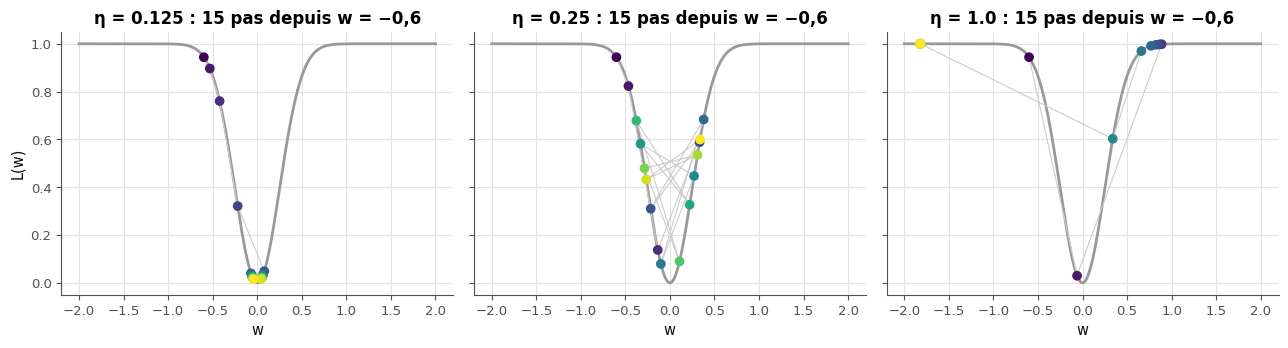

✅ Ex 19.14a : Bravo !
✅ Ex 19.14b : Exact !
✅ Ex 19.14c : Bien joué !
✅ Ex 19.14d : C'est ça !


In [29]:
if any(answer is ... or answer is None for answer in [steps_14, sides_14, cycle_14, escape_14]):
    print("⏳ Ex 19.14 : écris d'abord tes quatre prédictions, puis relance cette cellule.")
else:
    ETAS_14 = [0.025, 0.05, 0.1, 0.125, 0.25, 0.5, 1.0]
    print("    η   first step with |w| < 0.01   w after 15 steps   side changes (15 steps)   w after 1000 steps")
    for eta in ETAS_14:
        ws_14 = descend_14(eta, 1000)
        hits_14 = np.flatnonzero(np.abs(ws_14) < 0.01)
        changes_14 = int(np.sum(np.sign(ws_14[1:16]) != np.sign(ws_14[:15])))
        print(f"{eta:6}   {str(hits_14[0]) if hits_14.size else 'never':>12}   {ws_14[15]:+16.4f}   {changes_14:12d}   {ws_14[-1]:+20.4f}")
    fig_14, axes_14 = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
    for ax, eta in zip(axes_14, (0.125, 0.25, 1.0)):
        ws_14 = descend_14(eta, 15)
        ax.plot(grid_14, valley(grid_14), color="0.6")
        ax.plot(ws_14, valley(ws_14), color="0.8", lw=0.8)
        ax.scatter(ws_14, valley(ws_14), c=np.arange(16), cmap="viridis", zorder=3)
        ax.set_title(f"η = {eta} : 15 pas depuis w = −0,6")
        ax.set_xlabel("w")
    axes_14[0].set_ylabel("L(w)")
    plt.tight_layout()
    plt.show()
    wb.check("19.14a", steps_14)
    wb.check("19.14b", sides_14)
    wb.check("19.14c", cycle_14)
    wb.check("19.14d", escape_14)

Dans tes notes : pour chaque ligne du tableau, place $\eta$ par rapport à $1/a$ et $2/a$, et compare ce que prédit la règle de la parabole à ce qu'affiche le tableau. Explique chaque accord et chaque désaccord. Que dit l'expérience sur la façon de choisir $\eta$ quand on ne connaît pas la courbure ?

💡 La courbure du fond vaut $a = L''(0) = 16$ : la règle de la parabole donne $1/a = 0{,}0625$ et $2/a = 0{,}125$. a) $\eta = 1/8 = 2/a$ tombe **pile** sur la limite : au fond, le facteur $1 - \eta a$ vaut $-1$, et la bille rebondit d'un côté à l'autre presque sans se rapprocher ; elle ne passe sous 0,01 qu'au pas 309, parce que le gradient de la gaussienne est un peu plus faible que celui de la parabole dès qu'on s'écarte du fond. b) $\eta = 0{,}1$ est entre $1/a$ et $2/a$ : le facteur $-0{,}6$ fait changer la bille de côté à chaque pas, en se rapprochant (11 changements en 15 pas ; fond atteint au pas 9). c) Avec $\eta = 0{,}25 = 4/a$, la parabole prédit une divergence (facteur $-3$) ; mais la gaussienne n'est pas une parabole : loin du fond, sa pente faiblit, et la bille, renvoyée vers le haut, retombe : elle rebondit sans fin entre $-0{,}38$ et $0{,}38$, sans jamais repasser sous 0,09 ni partir. d) Avec $\eta = 1$, le premier grand pas la jette sur la partie plate ($w \approx -1{,}8$ après 1 000 pas) : la pente y est si faible que plus rien ne la ramène. Leçon : la règle $\eta < 2/a$ vaut **près** d'un minimum ; ailleurs, la forme de la surface décide. Comme on ne connaît pas la courbure d'un vrai réseau, on balaie $\eta$ sur une échelle logarithmique (ch. 18).

### Ex 19.15 — Plannings : exponential_decay_lr, step_decay_lr, bold_driver_lr 🔨 ★ ⏱️ 15 min
**Objectif :** écrire trois plannings de learning rate du livre, en fonctions pures.  
**Prérequis :** ✏️ 19.1 · fiche §19.3.2, §19.3.3 · **mylearn :** `optim.py` · **Parcours :** C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/optim.py` (créé par `python tools/start_chapter.py 19`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy et la bibliothèque standard seulement ; PyTorch est l'**oracle** des tests (sans PyTorch, ils comparent à une transcription NumPy du pseudo-code de `torch.optim`, et aucun n'est ignoré). La cellule de vérification recharge ta librairie, essaie les exemples des docstrings, quelques cas choisis et 100 pas sur la fonction de Rosenbrock (comparés à `torch.optim` si PyTorch est là), puis lance les tests de l'exercice ; `python -m pytest tests/test_ch19_optim.py -q` les lance tous dans un terminal.

Écris `exponential_decay_lr(step, base_lr, gamma)`, `step_decay_lr(step, base_lr, step_size, gamma=0.1)` et `bold_driver_lr(lr, loss, prev_loss, increase=1.05, decrease=0.5, tolerance=0.0)`. **Contrat** (les docstrings, plus ces précisions que vérifient les tests) :
- les trois rendent un `float` Python, même pour des arguments entiers (`float(...)`) ;
- `exponential_decay_lr` vaut $\eta_0\,\gamma^{k}$ et `step_decay_lr` $\eta_0\,\gamma^{\lfloor k/s \rfloor}$ (la division **entière**, `step // step_size`) ; elles suivent `ExponentialLR` et `StepLR` de PyTorch sur 50 pas ;
- `bold_driver_lr` a trois cas, dans cet ordre : une loss plus basse que la précédente fait `lr * increase` ; une loss plus haute que `prev_loss * (1 + tolerance)` fait `lr * decrease` ; sinon (une loss égale, ou une hausse dans la tolérance), `lr` ne change pas ;
- les arguments invalides lèvent `ValueError` : un pas négatif, `base_lr < 0`, `step_size < 1`, un `gamma` hors de $]0, 1]$, `increase <= 1`, `decrease` hors de $]0, 1[$, `tolerance < 0`.

La vérification essaie les exemples des docstrings, quelques pas choisis, le type des valeurs rendues et cinq arguments invalides, puis lance les tests (`-k "test_exponential_decay_lr_ or test_step_decay_lr_ or test_bold_driver_lr_"`).

Dans tes notes : avec $\gamma = 0{,}9$ appliqué à chaque **mise à jour** (pas à chaque epoch), au bout de combien de mises à jour $\eta$ passe-t-il sous 1 % de $\eta_0$ ? Et si tu l'appliques à chaque epoch de 1 000 mises à jour ?

In [30]:
if True:
    O = mylearn.optim
    got_15 = [O.exponential_decay_lr(s, 0.1, 0.5) for s in range(4)]
    same("19.15", "exponential_decay_lr pour s = 0 à 3 (l'exemple de la docstring)", got_15, [0.1, 0.05, 0.025, 0.0125], rtol=1e-12, atol=0)
    same("19.15", "exponential_decay_lr(30, 0.4, 0.9)", O.exponential_decay_lr(30, 0.4, 0.9), 0.4 * 0.9 ** 30, rtol=1e-12, atol=0)
    got_15 = [O.step_decay_lr(s, 0.1, step_size=10, gamma=0.5) for s in (0, 9, 10, 25, 49)]
    same("19.15", "step_decay_lr aux pas 0, 9, 10, 25 et 49 (paliers de 10, γ = 0,5)", got_15, [0.1, 0.1, 0.05, 0.025, 0.00625], rtol=1e-12, atol=0)
    got_15 = [O.bold_driver_lr(1.0, loss=0.8, prev_loss=1.0), O.bold_driver_lr(1.0, loss=1.2, prev_loss=1.0),
              O.bold_driver_lr(1.0, loss=1.05, prev_loss=1.0, tolerance=0.1), O.bold_driver_lr(0.2, loss=1.0, prev_loss=1.0)]
    same("19.15", "bold_driver_lr : baisse, hausse, hausse dans la tolérance, loss égale", got_15, [1.05, 0.5, 1.0, 0.2], rtol=1e-12, atol=0)
    values_15 = [O.exponential_decay_lr(3, 1, 0.5), O.step_decay_lr(3, 1, 2), O.bold_driver_lr(1, 0.5, 1.0)]
    verdict("19.15", all(is_float(v) for v in values_15), "les trois plannings rendent des float Python, même pour des arguments entiers.",
            f"attendu des float Python, reçu {[type(v).__name__ for v in values_15]} (convertis avec float(...)).")
    refuses("19.15", "exponential_decay_lr avec γ = 0", lambda: O.exponential_decay_lr(1, 0.1, 0.0))
    refuses("19.15", "exponential_decay_lr avec un pas négatif", lambda: O.exponential_decay_lr(-1, 0.1, 0.5))
    refuses("19.15", "step_decay_lr avec step_size = 0", lambda: O.step_decay_lr(5, 0.1, step_size=0))
    refuses("19.15", "bold_driver_lr avec increase = 1", lambda: O.bold_driver_lr(1.0, 0.5, 1.0, increase=1.0))
    refuses("19.15", "bold_driver_lr avec decrease = 1", lambda: O.bold_driver_lr(1.0, 0.5, 1.0, decrease=1.0))
if written(lambda: mylearn.optim.exponential_decay_lr(0, 0.1, 0.5)):
    run_optim_tests(impl="ref", keyword="test_exponential_decay_lr_ or test_step_decay_lr_ or test_bold_driver_lr_")
else:
    print("⏳ Ex 19.15 : les tests attendent tes fonctions.")

✅ Ex 19.15 : exponential_decay_lr pour s = 0 à 3 (l'exemple de la docstring) : [0.1, 0.05, 0.025, 0.0125], comme attendu.
✅ Ex 19.15 : exponential_decay_lr(30, 0.4, 0.9) : 0.01695646, comme attendu.
✅ Ex 19.15 : step_decay_lr aux pas 0, 9, 10, 25 et 49 (paliers de 10, γ = 0,5) : [0.1, 0.1, 0.05, 0.025, 0.00625], comme attendu.
✅ Ex 19.15 : bold_driver_lr : baisse, hausse, hausse dans la tolérance, loss égale : [1.05, 0.5, 1.0, 0.2], comme attendu.
✅ Ex 19.15 : les trois plannings rendent des float Python, même pour des arguments entiers.
✅ Ex 19.15 : exponential_decay_lr avec γ = 0 : ValueError levée (need step >= 0, base_lr >= 0 and gamma in (0, 1]; got step=1, base_lr=0.1, gamma=0.0).
✅ Ex 19.15 : exponential_decay_lr avec un pas négatif : ValueError levée (need step >= 0, base_lr >= 0 and gamma in (0, 1]; got step=-1, base_lr=0.1, gamma=0.5).
✅ Ex 19.15 : step_decay_lr avec step_size = 0 : ValueError levée (need step >= 0, base_lr >= 0, step_size >= 1 and gamma in (0, 1]; got step=5

pytest: 30 passed, 177 deselected in 4.51s


💡 Il faut $0{,}9^k < 0{,}01$, soit $k > \ln 0{,}01 / \ln 0{,}9 \approx 43{,}7$ : **44 mises à jour**. Avec 1 000 mises à jour par epoch, 44 mises à jour ne font même pas une epoch : le learning rate est presque nul avant la fin de la première, et l'entraînement s'arrête net (le piège « un planning trop rapide » de la fiche). Appliqué à chaque epoch, le même $\gamma$ met 44 epochs, soit 44 000 mises à jour, à faire le même chemin. D'où l'habitude de compter un planning en epochs, ou de prendre, par mise à jour, un $\gamma$ très proche de 1 ($0{,}9^{1/1000} \approx 0{,}999895$).

### Ex 19.16 — SGD, Momentum et Nesterov à la manière de torch.optim 🔨 ★★ ⏱️ 30 min
**Objectif :** écrire la méthode step de trois optimiseurs avec les conventions exactes de PyTorch.  
**Prérequis :** ✏️ 19.2 et 19.3 · ch. 18 (`mlp_backward`, la boucle d'entraînement) · fiche §19.5, §19.5.1, §19.5.2 · **Fil rouge :** Rosenbrock · **mylearn :** `optim.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/optim.py` (créé par `python tools/start_chapter.py 19`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy et la bibliothèque standard seulement ; PyTorch est l'**oracle** des tests (sans PyTorch, ils comparent à une transcription NumPy du pseudo-code de `torch.optim`, et aucun n'est ignoré). La cellule de vérification recharge ta librairie, essaie les exemples des docstrings, quelques cas choisis et 100 pas sur la fonction de Rosenbrock (comparés à `torch.optim` si PyTorch est là), puis lance les tests de l'exercice ; `python -m pytest tests/test_ch19_optim.py -q` les lance tous dans un terminal.

**Contrat commun des optimiseurs** (les docstrings, plus ces précisions que vérifient les tests) : `__init__` est fourni : il vérifie ses arguments et crée `params`, `lr`, `t = 0` et `state`, une liste d'un dictionnaire vide par paramètre. Tu écris `step(grads)` :
- il vérifie **tous** les gradients **avant** toute mise à jour : leur nombre, puis la forme de chacun, sans diffusion (un gradient `(1, 3)` pour un paramètre `(2, 3)` lève `ValueError`) ; sur un refus, aucun paramètre ne change et `t` reste le même ;
- il incrémente `self.t` une fois par pas (quel que soit le nombre de paramètres) et modifie chaque paramètre **en place** (`p -= ...` ; jamais `p = p - ...`, qui crée un nouveau tableau que le réseau ne voit pas, ni une nouvelle liste) ; un paramètre peut être un tableau 0-D, de forme `()` : `p[:] = ...` y échoue, et `g + wd * p` y rend un scalaire NumPy, qu'`np.asarray(...)` remet en tableau ;
- il ne modifie jamais les gradients reçus, même quand les **mêmes** tableaux reviennent à chaque pas : un tampon est une **copie** (`g.copy()`), et le weight decay s'ajoute à une copie (`g = g + wd * p`, jamais `g += wd * p`) ;
- ses tampons (vitesse, moyennes) vivent dans `self.state[i]`, le dictionnaire du paramètre `i`, vide avant le premier pas ; jamais dans un attribut de classe, pour que deux optimiseurs ne partagent rien ;
- il relit `self.lr` à chaque pas : un planning le change entre deux pas ;
- tout se calcule en `float64`, et les résultats doivent coïncider avec `torch.optim` à $10^{-10}$ près (en relatif) après 20 pas : une formule « presque » juste ne passe pas.

Écris `step` pour `SGD`, `Momentum` et `Nesterov`. **Contrat** propre à ces trois classes (avec $g$ le gradient, plus `weight_decay * p` s'il y a un weight decay) :
- `SGD` : $p \leftarrow p - \eta\,g$ ;
- `Momentum` : au **premier** pas, la vitesse vaut $b = g$ (une copie) ; ensuite $b \leftarrow \mu\,b + g$ ; puis $p \leftarrow p - \eta\,b$ ($\eta$ appliqué **après** la vitesse, la convention de PyTorch, pas celle du livre) ;
- `Nesterov` : la même vitesse, puis $p \leftarrow p - \eta\,(g + \mu\,b)$, avec la vitesse **déjà mise à jour** ;
- chacune est comparée à `torch.optim.SGD(lr, momentum, dampening=0, nesterov=..., weight_decay)`.

La vérification essaie, pour chaque classe, l'exemple de sa docstring, trois pas sur deux paramètres dont un 0-D (en place, gradients intacts), trois gradients refusés (rien ne doit bouger) et 100 pas sur la fonction de Rosenbrock comparés à `torch.optim`, puis lance les tests (`-k "test_sgd_ or test_momentum_ or test_nesterov_"`).

Dans tes notes : pourquoi la vitesse doit-elle être une **copie** du gradient au premier pas ? Écris un exemple de deux lignes où `b = g` (sans copie) donne un faux résultat.

In [31]:
for name in ("SGD", "Momentum", "Nesterov"):
    if True:
        check_optimizer("19.16", name)
if written(lambda: mylearn.optim.SGD([np.zeros(1)], lr=0.1).step([np.ones(1)])):
    run_optim_tests(impl="ref", keyword="test_sgd_ or test_momentum_ or test_nesterov_")
else:
    print("⏳ Ex 19.16 : les tests attendent tes classes.")

✅ Ex 19.16 : SGD : l'exemple de la docstring : [0.95, -1.9], comme attendu.
✅ Ex 19.16 : SGD : t = 1 après 1 pas.
✅ Ex 19.16 : SGD : les deux paramètres (dont un 0-D) sont modifiés en place.
✅ Ex 19.16 : SGD : les gradients sont intacts.
✅ Ex 19.16 : SGD : un gradient de moins : ValueError levée (got 1 gradient(s) for 2 parameter(s): pass one gradient per parameter, in the same order).
✅ Ex 19.16 : SGD : un gradient (1, 3) pour un paramètre (2, 3) : ValueError levée (gradient 0 has shape (1, 3), but parameter 0 has shape (2, 3)).
✅ Ex 19.16 : SGD : le 2ᵉ gradient de forme (4,) : ValueError levée (gradient 1 has shape (4,), but parameter 1 has shape (3,)).
✅ Ex 19.16 : SGD : après les refus, rien n'a bougé et t vaut 0.


✅ Ex 19.16 : SGD, 100 pas sur la fonction de Rosenbrock, contre torch.optim : [-0.94755447, 0.90590627], comme attendu.
✅ Ex 19.16 : Momentum : l'exemple de la docstring : [0.71], comme attendu.
✅ Ex 19.16 : Momentum : t = 2 après 2 pas.
✅ Ex 19.16 : Momentum : les deux paramètres (dont un 0-D) sont modifiés en place.
✅ Ex 19.16 : Momentum : les gradients sont intacts.
✅ Ex 19.16 : Momentum : un gradient de moins : ValueError levée (got 1 gradient(s) for 2 parameter(s): pass one gradient per parameter, in the same order).
✅ Ex 19.16 : Momentum : un gradient (1, 3) pour un paramètre (2, 3) : ValueError levée (gradient 0 has shape (1, 3), but parameter 0 has shape (2, 3)).
✅ Ex 19.16 : Momentum : le 2ᵉ gradient de forme (4,) : ValueError levée (gradient 1 has shape (4,), but parameter 1 has shape (3,)).
✅ Ex 19.16 : Momentum : après les refus, rien n'a bougé et t vaut 0.
✅ Ex 19.16 : Momentum, 100 pas sur la fonction de Rosenbrock, contre torch.optim : [-0.92818438, 0.86735899], comme at

pytest: 53 passed, 154 deselected in 4.88s


💡 Avec `b = g`, la vitesse **est** le tableau du gradient : au pas suivant, `b *= mu; b += g` modifie le gradient reçu, et si l'appelant repasse le même tableau (une boucle qui réutilise son tampon de gradients, comme le font les tests), le gradient lu vaut déjà autre chose. Exemple : `g = np.ones(1)`, deux pas avec ce même `g` et $\mu = 0{,}9$ : au second pas, `b *= 0.9` met aussi `g` à 0,9, puis `b += g` double : $b = 1{,}8$ au lieu de $1{,}9$, et le gradient de l'appelant est détruit. `b = g.copy()` sépare les deux.

### Ex 19.17 — Adagrad, RMSprop et Adadelta 🔨 ★★ ⏱️ 30 min
**Objectif :** écrire trois optimiseurs adaptatifs, avec leurs epsilons au bon endroit.  
**Prérequis :** Ex 19.16 · ✏️ 19.4 · fiche §19.5.3, §19.5.4 (encadré sur la moyenne mobile exponentielle) · **Fil rouge :** Rosenbrock · **mylearn :** `optim.py` · **Parcours :** M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/optim.py` (créé par `python tools/start_chapter.py 19`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy et la bibliothèque standard seulement ; PyTorch est l'**oracle** des tests (sans PyTorch, ils comparent à une transcription NumPy du pseudo-code de `torch.optim`, et aucun n'est ignoré). La cellule de vérification recharge ta librairie, essaie les exemples des docstrings, quelques cas choisis et 100 pas sur la fonction de Rosenbrock (comparés à `torch.optim` si PyTorch est là), puis lance les tests de l'exercice ; `python -m pytest tests/test_ch19_optim.py -q` les lance tous dans un terminal.

Le **contrat commun des optimiseurs** est celui de 19.16 (vérification de tous les gradients avant toute mise à jour, en place, gradients intacts, tampons copiés dans `self.state`, `self.lr` relu, 0-D, `float64`).

Écris `step` pour `Adagrad`, `RMSprop` et `Adadelta`. **Contrat** propre à ces trois classes :
- `Adagrad` : l'accumulateur $s$ part de `initial_accumulator_value` (pas forcément de 0), $s \leftarrow s + g^2$, puis $p \leftarrow p - \eta\,g/(\sqrt{s} + \epsilon)$, `eps` **après** la racine ;
- `RMSprop` : $v$ part de 0, $v \leftarrow \alpha v + (1 - \alpha)\,g^2$, puis $p \leftarrow p - \eta\,g/(\sqrt{v} + \epsilon)$, `eps` après la racine (`alpha` vaut 0,99 par défaut) ;
- `Adadelta` : $v$ et $u$ partent de 0 ; $v \leftarrow \rho v + (1 - \rho)\,g^2$, $d = \frac{\sqrt{u + \epsilon}}{\sqrt{v + \epsilon}}\,g$ (avec le $u$ **d'avant**), $u \leftarrow \rho u + (1 - \rho)\,d^2$, puis $p \leftarrow p - \eta\,d$ : `eps` **sous** les deux racines, et `lr` est un multiplicateur (1,0 par défaut) ;
- chacune est comparée à son équivalent de `torch.optim` (`Adagrad` avec `lr_decay=0`, `RMSprop` avec `momentum=0, centered=False`, `Adadelta`).

La vérification fait les mêmes essais qu'en 19.16, puis lance les tests (`-k "test_adagrad_ or test_rmsprop_ or test_adadelta_"`).

Dans tes notes : au tout premier pas, de combien bouge chaque coordonnée avec Adagrad (et `initial_accumulator_value = 0`) ? Et avec Adadelta, si le gradient vaut 1 ? Qu'est-ce qui fixe la taille des premiers pas d'Adadelta ?

In [32]:
for name in ("Adagrad", "RMSprop", "Adadelta"):
    if True:
        check_optimizer("19.17", name)
if written(lambda: mylearn.optim.Adagrad([np.zeros(1)], lr=0.1).step([np.ones(1)])):
    run_optim_tests(impl="ref", keyword="test_adagrad_ or test_rmsprop_ or test_adadelta_")
else:
    print("⏳ Ex 19.17 : les tests attendent tes classes.")

✅ Ex 19.17 : Adagrad : l'exemple de la docstring : [0.9], comme attendu.
✅ Ex 19.17 : Adagrad : t = 1 après 1 pas.
✅ Ex 19.17 : Adagrad : les deux paramètres (dont un 0-D) sont modifiés en place.
✅ Ex 19.17 : Adagrad : les gradients sont intacts.
✅ Ex 19.17 : Adagrad : un gradient de moins : ValueError levée (got 1 gradient(s) for 2 parameter(s): pass one gradient per parameter, in the same order).
✅ Ex 19.17 : Adagrad : un gradient (1, 3) pour un paramètre (2, 3) : ValueError levée (gradient 0 has shape (1, 3), but parameter 0 has shape (2, 3)).
✅ Ex 19.17 : Adagrad : le 2ᵉ gradient de forme (4,) : ValueError levée (gradient 1 has shape (4,), but parameter 1 has shape (3,)).
✅ Ex 19.17 : Adagrad : après les refus, rien n'a bougé et t vaut 0.
✅ Ex 19.17 : Adagrad, 100 pas sur la fonction de Rosenbrock, contre torch.optim : [-0.99840582, 1.00302625], comme attendu.
✅ Ex 19.17 : RMSprop : l'exemple de la docstring : [0.90000001], comme attendu.
✅ Ex 19.17 : RMSprop : t = 1 après 1 pas.
✅

pytest: 55 passed, 152 deselected in 4.99s


💡 Au premier pas d'Adagrad (accumulateur nul), $s = g^2$ et le pas vaut $\eta\,g/(|g| + \epsilon) \approx \eta\,\mathrm{signe}(g)$ : chaque coordonnée bouge d'environ $\eta$, quelle que soit la taille de son gradient (comme Adam, ✏️ 19.5). Pour Adadelta, avec $g = 1$, $\rho = 0{,}9$ et $\epsilon = 10^{-6}$ : $v = 0{,}1$, $d = \sqrt{10^{-6}}/\sqrt{0{,}1 + 10^{-6}} \approx 0{,}00316$ (l'exemple de la docstring) : le premier pas est fixé par $\sqrt{\epsilon}$, puisque $u$ part de 0. C'est pourquoi l'`eps` d'Adadelta n'est pas un détail : il joue, au départ, le rôle du learning rate.

### Ex 19.18 — Adam et AdamW 🔨 ★★ ⏱️ 30 min
**Objectif :** écrire Adam, avec sa correction de biais, puis AdamW et son weight decay découplé.  
**Prérequis :** Ex 19.16 · ✏️ 19.5 et 19.6 · ∂ 19.8 · fiche §19.5.5, section sur AdamW · **Fil rouge :** Rosenbrock · **mylearn :** `optim.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/optim.py` (créé par `python tools/start_chapter.py 19`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy et la bibliothèque standard seulement ; PyTorch est l'**oracle** des tests (sans PyTorch, ils comparent à une transcription NumPy du pseudo-code de `torch.optim`, et aucun n'est ignoré). La cellule de vérification recharge ta librairie, essaie les exemples des docstrings, quelques cas choisis et 100 pas sur la fonction de Rosenbrock (comparés à `torch.optim` si PyTorch est là), puis lance les tests de l'exercice ; `python -m pytest tests/test_ch19_optim.py -q` les lance tous dans un terminal.

Le **contrat commun des optimiseurs** est celui de 19.16.

Écris `step` pour `Adam` et `AdamW`. **Contrat** propre à ces deux classes :
- `Adam` : $m$ et $v$ partent de 0 ; avec $t$ le **nouveau** numéro de pas (1 au premier pas), $m \leftarrow \beta_1 m + (1 - \beta_1)\,g$, $v \leftarrow \beta_2 v + (1 - \beta_2)\,g^2$, $\hat m = m/(1 - \beta_1^t)$, $\hat v = v/(1 - \beta_2^t)$, puis $p \leftarrow p - \eta\,\hat m/(\sqrt{\hat v} + \epsilon)$ ; le `weight_decay` d'Adam est **couplé** : il s'ajoute au gradient et passe par les deux moyennes ;
- `AdamW` : d'abord $p \leftarrow p\,(1 - \eta\lambda)$ (en place), puis le pas d'Adam calculé sur le gradient **brut** (le weight decay ne passe pas par les moyennes) ; `weight_decay` vaut 0,01 par défaut ;
- la forme « efficace » de l'article (§2 : $\eta_t = \eta\sqrt{1 - \beta_2^t}/(1 - \beta_1^t)$, puis $p \leftarrow p - \eta_t\,m/(\sqrt{v} + \hat\epsilon)$) ne donne les mêmes nombres que PyTorch qu'avec $\hat\epsilon = \epsilon\sqrt{1 - \beta_2^t}$ ;
- chacune est comparée à `torch.optim.Adam` et `torch.optim.AdamW` (`amsgrad=False`).

La vérification fait les mêmes essais qu'en 19.16, puis lance les tests (`-k "test_adam_ or test_adamw_"`).

Dans tes notes : avec un gradient nul et un weight decay de 0,01, de combien bouge un poids de valeur 1 au premier pas avec AdamW ($\eta = 0{,}1$) ? Et avec Adam et le même `weight_decay` ? D'où vient la différence ?

In [33]:
for name in ("Adam", "AdamW"):
    if True:
        check_optimizer("19.18", name)
if written(lambda: mylearn.optim.Adam([np.zeros(1)], lr=0.1).step([np.ones(1)])):
    run_optim_tests(impl="ref", keyword="test_adam_ or test_adamw_")
else:
    print("⏳ Ex 19.18 : les tests attendent tes classes.")

✅ Ex 19.18 : Adam : l'exemple de la docstring : [0.9], comme attendu.
✅ Ex 19.18 : Adam : t = 1 après 1 pas.
✅ Ex 19.18 : Adam : les deux paramètres (dont un 0-D) sont modifiés en place.
✅ Ex 19.18 : Adam : les gradients sont intacts.
✅ Ex 19.18 : Adam : un gradient de moins : ValueError levée (got 1 gradient(s) for 2 parameter(s): pass one gradient per parameter, in the same order).
✅ Ex 19.18 : Adam : un gradient (1, 3) pour un paramètre (2, 3) : ValueError levée (gradient 0 has shape (1, 3), but parameter 0 has shape (2, 3)).
✅ Ex 19.18 : Adam : le 2ᵉ gradient de forme (4,) : ValueError levée (gradient 1 has shape (4,), but parameter 1 has shape (3,)).
✅ Ex 19.18 : Adam : après les refus, rien n'a bougé et t vaut 0.
✅ Ex 19.18 : Adam, 100 pas sur la fonction de Rosenbrock, contre torch.optim : [-1.04138335, 1.09077816], comme attendu.
✅ Ex 19.18 : AdamW : l'exemple de la docstring : [0.999], comme attendu.
✅ Ex 19.18 : AdamW : t = 1 après 1 pas.
✅ Ex 19.18 : AdamW : les deux paramèt

pytest: 40 passed, 167 deselected in 4.79s


💡 Avec AdamW, seul le rétrécissement agit : $w = 1 \times (1 - 0{,}1 \times 0{,}01) = 0{,}999$, un pas de 0,001 (l'exemple de la docstring). Avec Adam, le weight decay **devient** le gradient : $g = 0{,}01 \times 1 = 0{,}01$, et le premier pas d'Adam vaut $\eta\,\mathrm{signe}(g)$ (✏️ 19.5) : $w = 0{,}9$, cent fois plus. Adam normalise le terme de weight decay comme un gradient ordinaire : sa force ne dépend plus de $\lambda$ seul, mais de l'échelle des autres gradients du même poids. AdamW le sort de la normalisation (✏️ 19.6).

### Ex 19.19 — Warmup + cosinus et gradient clipping 🔨 ★★ ⏱️ 25 min
**Objectif :** écrire le planning le plus répandu aujourd'hui et le clipping de la norme globale du gradient.  
**Prérequis :** ✏️ 19.1 · 0B (cosinus, norme d'un vecteur) · fiche, sections sur le warmup et le cosinus, et sur le gradient clipping · **mylearn :** `optim.py` · **Parcours :** R, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/optim.py` (créé par `python tools/start_chapter.py 19`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy et la bibliothèque standard seulement ; PyTorch est l'**oracle** des tests (sans PyTorch, ils comparent à une transcription NumPy du pseudo-code de `torch.optim`, et aucun n'est ignoré). La cellule de vérification recharge ta librairie, essaie les exemples des docstrings, quelques cas choisis et 100 pas sur la fonction de Rosenbrock (comparés à `torch.optim` si PyTorch est là), puis lance les tests de l'exercice ; `python -m pytest tests/test_ch19_optim.py -q` les lance tous dans un terminal.

Écris `cosine_lr(step, total_steps, base_lr, warmup_steps=0, min_lr=0.0)` et `clip_grad_norm(grads, max_norm, eps=1e-6)`. **Contrat** (les docstrings, plus ces précisions que vérifient les tests) :
- `cosine_lr` a trois branches, dans cet ordre : `step < warmup_steps` donne `base_lr * step / warmup_steps` (0 au pas 0, la convention de Hugging Face) ; jusqu'à `total_steps` exclu, la demi-arche de cosinus de `base_lr` à `min_lr` ; à partir de `total_steps`, `min_lr` (sans redémarrage) ; elle rend un `float` Python sur **chaque** branche ; `total_steps <= warmup_steps`, un pas ou un warmup négatif et `min_lr > base_lr` lèvent `ValueError` ; elle suit `get_cosine_schedule_with_warmup` de Hugging Face et `CosineAnnealingLR` de PyTorch ;
- `clip_grad_norm` calcule **une seule** norme, celle de tous les gradients mis bout à bout (des tableaux de formes quelconques, 0-D compris), et la rend en `float` Python ; si elle dépasse `max_norm`, il multiplie **chaque** gradient, en place, par le même facteur `max_norm / (norm + eps)`, comme `torch.nn.utils.clip_grad_norm_` ; sinon, il ne touche à rien ; `max_norm <= 0` lève `ValueError`. Les tests évitent la bande de largeur `eps` juste au-dessus de `max_norm`, où PyTorch et ta fonction peuvent différer d'un facteur $1 - 10^{-6}$.

La vérification essaie l'exemple de la docstring, une décroissance sans warmup vers `min_lr`, l'après-fin, le type des valeurs rendues, un clipping sur deux tableaux, un gradient sous le seuil et des arguments invalides, puis lance les tests (`-k "test_cosine_lr_ or test_clip_grad_norm_"`).

Dans tes notes : pourquoi le clipping par la norme garde-t-il la direction du gradient, alors que le clipping par valeur (chaque composante bornée à $[-c, c]$) la change ? Donne un exemple chiffré en deux dimensions.

In [34]:
if True:
    O = mylearn.optim
    got_19 = [O.cosine_lr(s, 100, 0.1, warmup_steps=10) for s in (0, 5, 10, 55, 100)]
    same("19.19", "cosine_lr aux pas 0, 5, 10, 55 et 100 (l'exemple de la docstring)", got_19, [0.0, 0.05, 0.1, 0.05, 0.0], rtol=1e-12, atol=1e-15)
    got_19 = [O.cosine_lr(s, 50, 0.1, min_lr=0.01) for s in range(0, 50, 7)]
    same("19.19", "cosine_lr sans warmup, de 0,1 à 0,01 en 50 pas (pas 0, 7, ..., 49)", got_19,
         [0.01 + 0.09 * 0.5 * (1 + math.cos(math.pi * s / 50)) for s in range(0, 50, 7)], rtol=1e-12, atol=1e-15)
    after_19 = [O.cosine_lr(s, 50, 0.1, warmup_steps=5, min_lr=0.01) for s in (50, 80)]
    same("19.19", "cosine_lr après total_steps (pas 50 et 80)", after_19, [0.01, 0.01], rtol=1e-12, atol=0)
    values_19 = [O.cosine_lr(s, 10, 1, warmup_steps=3) for s in (0, 2, 3, 10, 12)]
    verdict("19.19", all(is_float(v) for v in values_19), "cosine_lr rend un float Python sur chaque branche (warmup, cosinus, après la fin).",
            f"attendu des float Python, reçu {[type(v).__name__ for v in values_19]} (convertis avec float(...)).")
    refuses("19.19", "cosine_lr avec total_steps = warmup_steps", lambda: O.cosine_lr(0, 10, 0.1, warmup_steps=10))
    refuses("19.19", "cosine_lr avec min_lr > base_lr", lambda: O.cosine_lr(0, 10, 0.1, min_lr=0.2))
if True:
    O = mylearn.optim
    big_19 = [np.array([3.0]), np.array([[4.0]])]                 # two arrays: ONE global norm, sqrt(3² + 4²) = 5
    keep_19 = list(big_19)
    norm_19 = O.clip_grad_norm(big_19, max_norm=1.0)
    verdict("19.19", is_float(norm_19) and abs(norm_19 - 5.0) < 1e-12, "clip_grad_norm rend la norme globale d'avant : 5.0.",
            f"clip_grad_norm rend {norm_19!r} : attendu 5.0, un float Python, la norme de TOUS les gradients mis bout à bout.")
    same("19.19", "les deux gradients après clipping, multipliés par 1/(5 + 1e-6)", [float(big_19[0][0]), float(big_19[1][0, 0])],
         [3.0 / (5.0 + 1e-6), 4.0 / (5.0 + 1e-6)], rtol=1e-12, atol=0)
    verdict("19.19", big_19[0] is keep_19[0] and big_19[1] is keep_19[1], "les gradients sont modifiés en place (mêmes tableaux).",
            "la liste contient d'autres tableaux qu'avant : modifie chaque gradient en place (g *= facteur).")
    small_19 = [np.array([0.3, -0.4]), np.array(0.0)]
    norm_19 = O.clip_grad_norm(small_19, max_norm=1.0)
    verdict("19.19", abs(float(norm_19) - 0.5) < 1e-12 and np.array_equal(small_19[0], [0.3, -0.4]),
            "un gradient de norme 0,5 < 1 ne change pas (et la norme rendue vaut 0,5).",
            f"un gradient de norme 0,5 < max_norm = 1 a changé, ou la norme rendue vaut {norm_19!r} : on ne touche à rien sous le seuil.")
    refuses("19.19", "clip_grad_norm avec max_norm = 0", lambda: O.clip_grad_norm([np.ones(2)], max_norm=0.0))
if written(lambda: mylearn.optim.cosine_lr(0, 10, 0.1)):
    run_optim_tests(impl="ref", keyword="test_cosine_lr_ or test_clip_grad_norm_")
else:
    print("⏳ Ex 19.19 : les tests attendent tes fonctions.")

✅ Ex 19.19 : cosine_lr aux pas 0, 5, 10, 55 et 100 (l'exemple de la docstring) : [0.0, 0.05, 0.1, 0.05, 0.0], comme attendu.
✅ Ex 19.19 : cosine_lr sans warmup, de 0,1 à 0,01 en 50 pas (pas 0, 7, ..., 49) : un tableau (8,), comme attendu.
✅ Ex 19.19 : cosine_lr après total_steps (pas 50 et 80) : [0.01, 0.01], comme attendu.
✅ Ex 19.19 : cosine_lr rend un float Python sur chaque branche (warmup, cosinus, après la fin).
✅ Ex 19.19 : cosine_lr avec total_steps = warmup_steps : ValueError levée (need step >= 0, 0 <= warmup_steps < total_steps and min_lr <= base_lr; got step=0, warmup_steps=10, total_steps=10, min_).
✅ Ex 19.19 : cosine_lr avec min_lr > base_lr : ValueError levée (need step >= 0, 0 <= warmup_steps < total_steps and min_lr <= base_lr; got step=0, warmup_steps=0, total_steps=10, min_l).
✅ Ex 19.19 : clip_grad_norm rend la norme globale d'avant : 5.0.
✅ Ex 19.19 : les deux gradients après clipping, multipliés par 1/(5 + 1e-6) : [0.59999988, 0.79999984], comme attendu.
✅ Ex 19.

pytest: 29 passed, 178 deselected in 4.66s


💡 Le clipping par la norme multiplie **tout** le vecteur par un même nombre positif : la direction ne change pas, seule la longueur. Le clipping par valeur rabote chaque composante séparément : $(6 ;\ 0{,}5)$ borné à $[-1, 1]$ devient $(1 ;\ 0{,}5)$, qui ne pointe plus dans la même direction (l'angle passe de 4,8° à 26,6° au-dessus de l'axe horizontal) ; par la norme avec $c = 1$, il devient $(0{,}997 ;\ 0{,}083)$, toujours à 4,8°. La descente garde ainsi le sens de la plus forte pente, avec un pas raccourci.

## Partie B · Trop de momentum, les figures du chapitre, un Adam qui diverge

Prédire quand le momentum fait quitter la vallée (19.20), refaire avec ta librairie quatre figures du livre (19.21), puis réparer un Adam écrit de mémoire (19.22).

### Ex 19.20 — Trop de momentum : la bille quitte-t-elle la vallée ? 🔮 ★★ ⏱️ 15 min
**Objectif :** prédire à partir de quel momentum la bille sort d'une vallée bornée, et comparer avec une parabole.  
**Prérequis :** Ex 19.16 · Ex 19.14 · ∂ 19.7 (question 6) · fiche §19.5.1 · **Fil rouge :** synth · **Parcours :** C

La vallée de 19.14, $L(w) = 1 - e^{-8w^2}$, le même départ $w_0 = -0{,}6$, et **ton** `Momentum` (19.16) avec $\eta = 0{,}1$ (`LR_20`), pendant 2 000 pas, pour les cinq valeurs de `MUS_20` : $\mu = 0{,}5$ ; $0{,}9$ ; $0{,}95$ ; $0{,}97$ ; $0{,}99$. La bille « quitte la vallée » si elle finit loin du creux, $|w| > 1$ sur les 200 derniers pas. Rappel : sans momentum, $\eta = 0{,}1$ fait rebondir la bille, mais elle se pose au fond (19.14).

Prédis, **avant** d'exécuter :
a) `escapes_20` : pour combien des cinq valeurs de $\mu$ la bille quitte-t-elle la vallée ? (un entier de 0 à 5) ;
b) `parabola_20_ok` : sur la **parabole** $L(w) = 8w^2$, qui a la même courbure au fond, avec $\mu = 0{,}99$ et le même $\eta$, la bille est-elle à moins de 0,01 du fond après 2 000 pas ? (`True` ou `False`) ;
c) `far_20` : avec $\mu = 0{,}99$ sur la vallée, à quelle distance du fond la bille finit-elle ? (A) entre 1 et 2 ; (B) entre 2 et 5 ; (C) entre 5 et 10 ; (D) plus de 10.

Puis exécute l'expérience : elle vérifie d'abord ton `Momentum` sur l'exemple de sa docstring, affiche pour chaque $\mu$ si la bille quitte la vallée, son point le plus éloigné et sa position finale, trace les 300 premiers pas et la parabole, et vérifie tes prédictions.

In [35]:
MUS_20 = [0.5, 0.9, 0.95, 0.97, 0.99]
LR_20, STEPS_20 = 0.1, 2000


def roll_20(mu, grad_fn=valley_grad, steps=STEPS_20, w0=-0.6):
    """YOUR Momentum (Ex 19.16) with lr = LR_20 and momentum mu, on the valley (or on grad_fn): the positions."""
    w = np.array([w0], dtype=float)
    opt = mylearn.optim.Momentum([w], lr=LR_20, momentum=mu)
    path = [w[0]]
    for _ in range(steps):
        opt.step([np.asarray(grad_fn(w), dtype=float)])
        path.append(w[0])
    return np.array(path)

In [36]:
escapes_20, parabola_20_ok, far_20 = 2, True, "D"   # the answers, for the record

In [37]:
wb.record("19.20a", 2, fractional="on compte des valeurs de μ : un entier de 0 à 5",
          mistakes={"relis la colonne « leaves the valley » du tableau : combien de True ?": 0,
                    "une seule ? Relis la colonne « leaves the valley » ligne par ligne": 1,
                    "trois ? Relis la ligne μ = 0,95 du tableau": 3,
                    "relis la colonne « leaves the valley » : toutes les lignes disent-elles la même chose ?": 4,
                    "relis la ligne μ = 0,5 du tableau : la bille reste-t-elle dans le creux ?": 5})
wb.record("19.20b", True, mistakes={"sur une parabole, ∂ 19.7 (question 6) donne la condition 0 < ηa < 2(1 + μ) : calcule ηa et 2(1 + μ)": False})
wb.record("19.20c", "D", mistakes={"relis la colonne « farthest point » à la ligne μ = 0,99": "A",
                                   "relis la colonne « w after 2 000 steps » à la ligne μ = 0,99 : quelle distance au fond ?": "B",
                                   "relis la dernière colonne à la ligne μ = 0,99 : la bille s'arrête-t-elle avant 10 ?": "C"})

WB_ANSWER {"fractional": "on compte des valeurs de μ : un entier de 0 à 5", "hash": "b5e592c3ba5e87b0e7a118974df6ac1c5aebb5856aace7d2b4540657d3e237cc", "id": "19.20a", "kind": "int", "magnitude": 0, "mistakes": {"1231e36bd650e9797f9e6afd9fea1a943a2878fc27ee356aaaaa07302fce20b7": "une seule ? Relis la colonne « leaves the valley » ligne par ligne", "8b00495070dde5c87d176b25347e303e96e4625ef5666b3d17655019a8bb7756": "relis la ligne μ = 0,5 du tableau : la bille reste-t-elle dans le creux ?", "9e661d66b0c03c381dd11f9601a02f0920652e7546eb792a772e06f868f41c19": "trois ? Relis la ligne μ = 0,95 du tableau", "cbac87181d8ac9ab823b56b017ef840b63381bb167a79690c4d016d0c38fa110": "relis la colonne « leaves the valley » : toutes les lignes disent-elles la même chose ?", "dbc5074794ca515eb5cfbc4209baa2b05c193eb67349566a940df1a26a7312a3": "relis la colonne « leaves the valley » du tableau : combien de True ?"}, "sign": 1}
📝 Ex 19.20a : réponse enregistrée (int).
WB_ANSWER {"hash": "ecfb5afe1ef3064f1a

    μ    leaves the valley (|w| > 1 at the end)   farthest point   w after 2 000 steps
   0.5          False            0.600            -0.0000
   0.9          False            0.600            -0.0000
  0.95          False            0.864            +0.0000
  0.97           True            4.620            +4.6204
  0.99           True           17.854           +17.8535
parabola 8 w², μ = 0.99: |w| after 2 000 steps = 1.41e-05


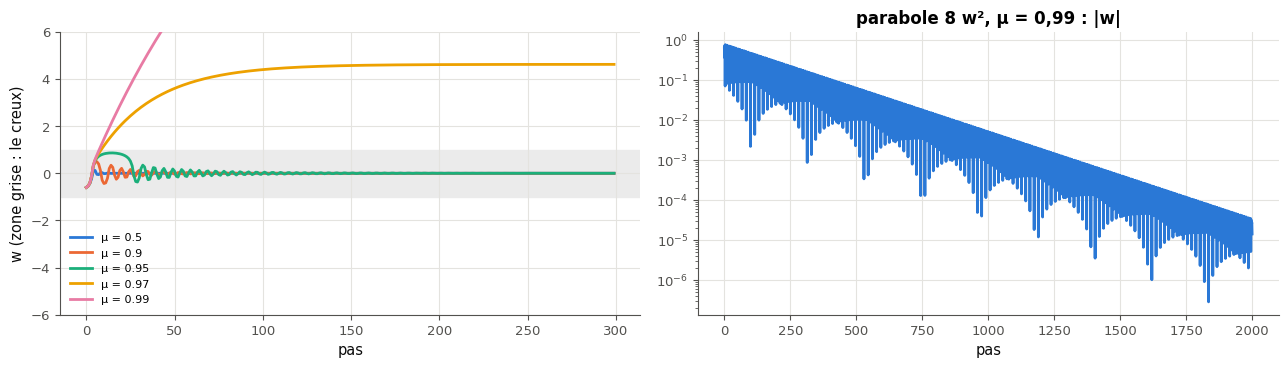

✅ Ex 19.20a : Bien joué !
✅ Ex 19.20b : C'est ça !
✅ Ex 19.20c : Parfait !


In [38]:
if any(answer is ... or answer is None for answer in [escapes_20, parabola_20_ok, far_20]):
    print("⏳ Ex 19.20 : écris d'abord tes trois prédictions, puis relance cette cellule.")
else:
    with checked("19.20"):
        probe_20 = np.array([1.0])
        control_20 = mylearn.optim.Momentum([probe_20], lr=0.1, momentum=0.9)
        for _ in range(2):
            control_20.step([np.array([1.0])])
        if not np.allclose(probe_20, [0.71], rtol=1e-12, atol=0):
            print(f"❌ Ex 19.20 : ton Momentum ne passe pas l'exemple de sa docstring (w = {probe_20[0]!r} au lieu de 0,71) : "
                  "corrige d'abord 19.16, puis relance cette cellule.")
        else:
            paths_20 = {mu: roll_20(mu) for mu in MUS_20}
            print("    μ    leaves the valley (|w| > 1 at the end)   farthest point   w after 2 000 steps")
            for mu, path in paths_20.items():
                print(f"{mu:6}   {str(bool(np.all(np.abs(path[-200:]) > 1))):>12}   {np.abs(path).max():14.3f}   {path[-1]:+16.4f}")
            parabola_20 = roll_20(0.99, grad_fn=lambda w: 16.0 * w)      # the parabola 8 w², same curvature at the bottom
            print(f"parabola 8 w², μ = 0.99: |w| after 2 000 steps = {abs(parabola_20[-1]):.2e}")
            fig_20, axes_20 = plt.subplots(1, 2, figsize=(13, 3.8))
            for mu, path in paths_20.items():
                axes_20[0].plot(path[:300], label=f"μ = {mu}")
            axes_20[0].axhspan(-1, 1, color="0.92", zorder=0)
            axes_20[0].set_ylim(-6, 6)
            axes_20[0].set_xlabel("pas")
            axes_20[0].set_ylabel("w (zone grise : le creux)")
            axes_20[0].legend(fontsize=8)
            axes_20[1].plot(np.abs(parabola_20) + 1e-300, color="#2a78d6")
            axes_20[1].set_yscale("log")
            axes_20[1].set_xlabel("pas")
            axes_20[1].set_title("parabole 8 w², μ = 0,99 : |w|")
            plt.tight_layout()
            plt.show()
            wb.check("19.20a", escapes_20)
            wb.check("19.20b", parabola_20_ok)
            wb.check("19.20c", far_20)

Dans tes notes : compare le pas effectif $\eta/(1 - \mu)$ de la fiche pour chaque ligne du tableau à la largeur du creux. Pourquoi la parabole et la vallée se comportent-elles comme elles le font avec $\mu = 0{,}99$ ? Une fois la bille sur la partie plate, que devient sa vitesse $b$, et jusqu'où peut-elle encore aller ?

💡 a) 2 : seules $\mu = 0{,}97$ et $0{,}99$ font sortir la bille (la sortie se joue entre 0,95 et 0,97 pour ce $\eta$). Le pas effectif $\eta/(1 - \mu)$ vaut 0,2 pour $\mu = 0{,}5$, mais 3,3 pour 0,97 et 10 pour 0,99 : la vitesse accumulée pendant la descente fait monter la bille si haut sur l'autre flanc qu'elle passe au-delà du point d'inflexion ($|w| = 0{,}25$), là où la pente faiblit : plus rien ne la ramène. b) Vrai : sur la parabole, la force de rappel grandit sans fin avec l'écart ; ∂ 19.7 (question 6) donne la convergence pour $0 < \eta a < 2(1 + \mu)$, ici $1{,}6 < 3{,}98$ : la bille oscille longtemps, mais l'amplitude est multipliée par $\sqrt{\mu}$ à chaque pas, et $|w| \approx 1{,}4 \times 10^{-5}$ après 2 000 pas. Le momentum élargit la plage stable d'une parabole ; il peut aussi faire sortir d'une vallée **bornée**, qui ne retient pas une bille trop rapide. c) D : la bille finit vers $w \approx 17{,}9$. Sur la partie plate, $g \approx 0$ : la vitesse est multipliée par $\mu$ à chaque pas, et la bille parcourt encore $\eta\,b\,\mu/(1 - \mu)$, une série géométrique : 99 fois son dernier pas.

### Ex 19.21 — Reproduire les figures du chapitre : pas constant, décroissant, momentum, Nesterov 🎨 ★★ ⏱️ 30 min
**Objectif :** refaire avec ta librairie quatre figures du livre sur la vallée, et comparer les trajectoires.  
**Prérequis :** Ex 19.15 · Ex 19.16 · fiche §19.3.1, §19.3.2, §19.5.1, §19.5.2 · **Fil rouge :** synth · **Parcours :** C

Refais, sur la vallée de 19.14 et depuis $w_0 = -0{,}6$, quatre figures du livre, avec 15 pas chacune :
a) un pas constant $\eta = 1/8$ (figure 19.14) ;
b) une décroissance exponentielle depuis $\eta_0 = 1/8$, $\gamma = 0{,}8$ (figure 19.24) ;
c) le momentum $\mu = 0{,}7$ avec la même décroissance (figure 19.39) ;
d) Nesterov $\mu = 0{,}7$ avec la même décroissance (figures 19.42 à 19.44).

Écris `trajectory_21(make_optimizer, steps, gamma=None, w0=-0.6)`, qui fait tourner **ton** optimiseur (créé par `make_optimizer([w])`, avec `w` un tableau de forme `(1,)`) et rend les `steps + 1` positions ; avec `gamma`, le learning rate du pas $k$ ($k = 0, 1, \dots$) vaut `exponential_decay_lr(k, base_lr, gamma)` (ta fonction de 19.15), `base_lr` étant le `lr` de l'optimiseur neuf. Puis écris `draw_21(ax_curve, ax_error, ws, title)`, qui dessine comme le livre : en haut, la vallée et les points $(w, L(w))$ colorés selon le pas et reliés par un trait fin ; en bas, l'erreur de chaque point en fonction de son numéro.

La vérification compare tes quatre trajectoires à un calcul indépendant, puis trace la figure avec ton `draw_21` (une colonne par cas). Attention : ton momentum suit PyTorch ($\eta$ appliqué après la vitesse), le livre applique $\eta$ dans le pas ; avec une décroissance, les deux ne coïncident plus (✏️ 19.2), et ta figure c) peut différer un peu de celle du livre.

Dans tes notes : quelle trajectoire se pose le plus près du fond en 15 pas ? Jusqu'où la bille dépasse-t-elle le fond en c) et en d), et combien de pas lui faut-il pour revenir à moins de 0,01 du fond ? Avec $\gamma = 0{,}8$, quelle est la somme de tous les learning rates de b), et que dit-elle de la distance que la bille peut encore parcourir ?

✅ Ex 19.21 : a) pas constant, η = 1/8 : les 16 positions : un tableau (16,), comme attendu.
✅ Ex 19.21 : b) décroissance, γ = 0,8 : les 16 positions : un tableau (16,), comme attendu.
✅ Ex 19.21 : c) momentum μ = 0,7 + décroissance : les 16 positions : un tableau (16,), comme attendu.
✅ Ex 19.21 : d) Nesterov μ = 0,7 + décroissance : les 16 positions : un tableau (16,), comme attendu.


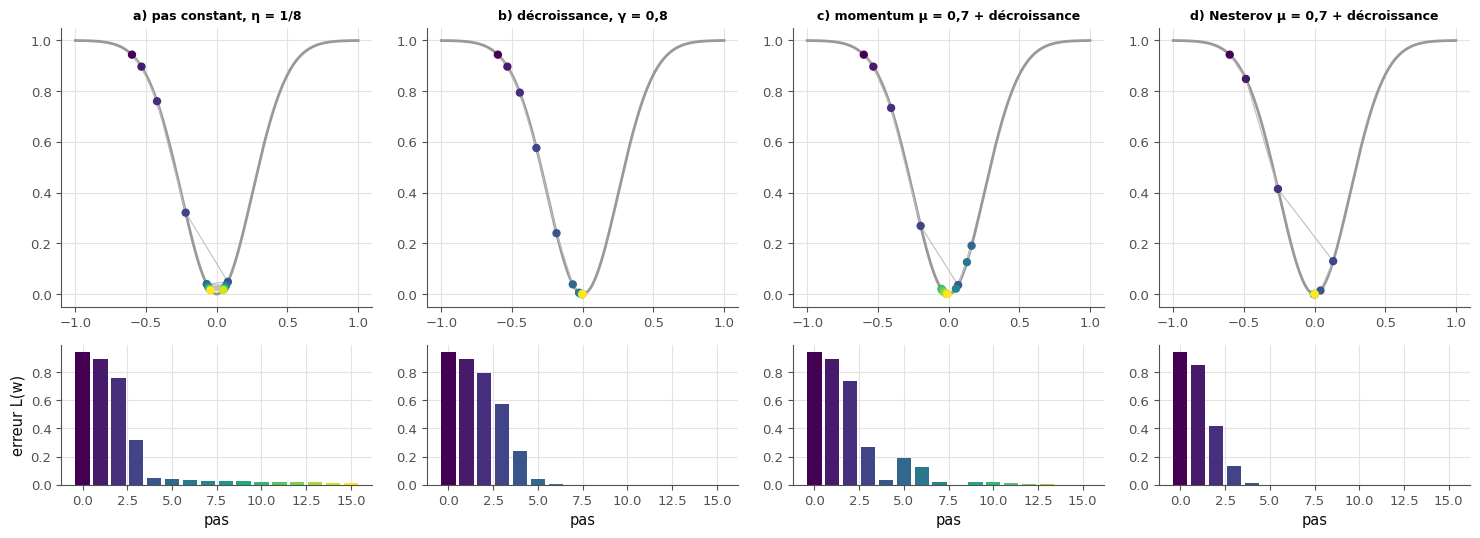

In [39]:
def trajectory_21(make_optimizer, steps, gamma=None, w0=-0.6):
    """Run YOUR optimizer on the valley and return the positions w_0, ..., w_steps (an array of shape (steps + 1,)).

    make_optimizer(params) builds the optimizer on params = [w], w a float array of shape (1,). With gamma, the learning
    rate of step k (k = 0, 1, ...) is exponential_decay_lr(k, base_lr, gamma) (YOUR function of 19.15), base_lr being
    the lr of the new optimizer; without gamma, the learning rate stays constant.
    """
    w = np.array([w0], dtype=float)
    opt = make_optimizer([w])
    base_lr = opt.lr
    positions = [w[0]]
    for k in range(steps):
        if gamma is not None:
            opt.lr = mylearn.optim.exponential_decay_lr(k, base_lr, gamma)
        opt.step([valley_grad(w)])
        positions.append(w[0])
    return np.array(positions)


def draw_21(ax_curve, ax_error, ws, title):
    """Draw like the book: on ax_curve, the valley and the points (w, L(w)) of ws colored by step, joined by thin lines;
    on ax_error, the error L(w) of each point against its step number. Give ax_curve the title."""
    grid = np.linspace(-1.0, 1.0, 401)
    steps = np.arange(len(ws))
    ax_curve.plot(grid, valley(grid), color="0.6")
    ax_curve.plot(ws, valley(ws), color="0.75", lw=0.8)
    ax_curve.scatter(ws, valley(ws), c=steps, cmap="viridis", zorder=3, s=25)
    ax_curve.set_title(title, fontsize=9)
    ax_error.bar(steps, valley(ws), color=plt.cm.viridis(steps / steps.max()))
    ax_error.set_xlabel("pas")

RUNS_21 = {"a) pas constant, η = 1/8": (lambda p: mylearn.optim.SGD(p, lr=0.125), None, "sgd"),
           "b) décroissance, γ = 0,8": (lambda p: mylearn.optim.SGD(p, lr=0.125), 0.8, "sgd"),
           "c) momentum μ = 0,7 + décroissance": (lambda p: mylearn.optim.Momentum(p, lr=0.125, momentum=0.7), 0.8, "momentum"),
           "d) Nesterov μ = 0,7 + décroissance": (lambda p: mylearn.optim.Nesterov(p, lr=0.125, momentum=0.7), 0.8, "nesterov")}


def expected_21(kind, gamma, steps=15, w=-0.6, lr=0.125, mu=0.7):
    """An independent computation of the same 15 steps (the formulas of the sheet)."""
    out, b = [w], None
    for k in range(steps):
        eta, g = lr * (gamma ** k if gamma else 1.0), 16.0 * w * math.exp(-8.0 * w * w)
        if kind == "sgd":
            w -= eta * g
        else:
            b = g if b is None else mu * b + g
            w -= eta * (b if kind == "momentum" else g + mu * b)
        out.append(w)
    return np.array(out)


PATHS_21 = {}
with checked("19.21"):
    for title_21, (make_21, gamma_21, kind_21) in RUNS_21.items():
        got_21 = trajectory_21(make_21, 15, gamma=gamma_21)
        if same("19.21", f"{title_21} : les 16 positions", got_21, expected_21(kind_21, gamma_21), rtol=1e-9, atol=1e-12):
            PATHS_21[title_21] = np.asarray(got_21, dtype=float)
if len(PATHS_21) == 4:
    with checked("19.21"):
        fig_21, axes_21 = plt.subplots(2, 4, figsize=(15, 5.5), gridspec_kw={"height_ratios": [2, 1]})
        for column_21, (title_21, ws_21) in enumerate(PATHS_21.items()):
            draw_21(axes_21[0, column_21], axes_21[1, column_21], ws_21, title_21)
        axes_21[1, 0].set_ylabel("erreur L(w)")
        plt.tight_layout()
        plt.show()

💡 Après 15 pas : a) rebondit toujours ($w_{15} \approx -0{,}043$, erreur 0,015) ; b) se pose sans dépasser ($w_{15} \approx -0{,}0016$) ; c) dépasse le fond jusqu'à $w \approx 0{,}16$, repart de l'autre côté (jusqu'à $-0{,}05$) et n'est qu'à $w \approx -0{,}007$ après 15 pas ; d) dépasse moins (jusqu'à $w \approx 0{,}13$) et se pose dès le 5ᵉ pas ($|w| < 0{,}005$ ensuite), comme le livre (« environ sept pas ») : Nesterov freine avant de dépasser. La somme des learning rates de b) vaut $\eta_0/(1 - \gamma) = 0{,}125/0{,}2 = 0{,}625$ : la bille ne peut plus parcourir qu'au plus $0{,}625 \times \max|L'| \approx 0{,}625 \times 2{,}43 \approx 1{,}5$, et bien moins en fait, car le gradient devient vite minuscule au fond ; une décroissance plus rapide l'aurait arrêtée en route (fiche §19.3.2).

### Ex 19.22 — Chasse au bug : un Adam qui diverge 🐛 ★★ ⏱️ 25 min
**Objectif :** trouver et corriger trois erreurs dans un Adam écrit de mémoire, en s'aidant de ce que doit faire son premier pas.  
**Prérequis :** Ex 19.18 · ✏️ 19.5 · ∂ 19.8 (question 6) · fiche §19.5.5 · **Fil rouge :** Rosenbrock · **Parcours :** C

Un collègue a écrit Adam de mémoire (`adam_22`, ci-dessous) pour minimiser la fonction de Rosenbrock depuis $(-1{,}2 ;\ 1)$. Son code tourne sans message d'erreur, mais dès le premier pas, la position vaut `nan`. Il contient **trois** erreurs.

Copie son code dans `adam_fixed_22`, puis corrige-le (même signature, même forme de résultat ; ce code est indépendant de ta librairie). Garde la convention de PyTorch : $\epsilon$ **après** la racine. Ce que tu sais d'Adam suffit à le tester sans rien comparer : son premier pas (✏️ 19.5 et ∂ 19.8, question 6).

La vérification teste trois propriétés du premier pas, dans l'ordre où les erreurs se masquent (une propriété fausse cache les suivantes), puis fait 2 000 pas, compare la position finale à `torch.optim.Adam` (si PyTorch est là), trace le chemin et vérifie ses deux coordonnées (`computed=True`) : a) `x` et b) `y` après 2 000 pas.

Dans tes notes : pour chacune des trois erreurs, ce qu'elle produirait **seule** (les deux autres corrigées), et pourquoi le point 2 de la vérification (multiplier la loss par 100) la démasque ou non.

In [40]:
def adam_22(grad, w0, lr=0.01, steps=2000, beta1=0.9, beta2=0.999, eps=1e-8):
    """A colleague's Adam, written from memory: the positions w_0, ..., w_steps (an array of shape (steps + 1, len(w0))).
    It runs without any error message, but the very first position it computes is already nan."""
    w = np.array(w0, dtype=float)
    m = np.zeros_like(w)
    v = np.zeros_like(w)
    path = [w.copy()]
    for t in range(steps):
        g = grad(w)
        m = beta1 * m + (1 - beta2) * g
        v = beta2 * v + (1 - beta2) * g ** 2
        m_hat = m / (1 - beta1 ** t)
        v_hat = v / (1 - beta2 ** t)
        w = w - lr * m_hat / (v_hat + eps)
        path.append(w.copy())
    return np.array(path)


with np.errstate(all="ignore"):
    print("the colleague's first steps on the Rosenbrock function:", adam_22(rosen_grad, ROSEN_START, steps=2).tolist())

the colleague's first steps on the Rosenbrock function: [[-1.2, 1.0], [nan, nan], [nan, nan]]


✅ Ex 19.22 : point 1) le premier pas donne une position finie (ni nan ni inf) : juste.
✅ Ex 19.22 : point 2) le premier pas ne change pas si l'on multiplie la loss par 100 : juste.
✅ Ex 19.22 : point 3) le premier pas vaut exactement lr dans chaque coordonnée, à l'opposé du gradient : juste.
after 2 000 steps: w = [0.785, 0.6155] · loss 0.0463


✅ Ex 19.22 : la position après 2 000 pas, contre torch.optim.Adam : [0.78498826, 0.61550353], comme attendu.


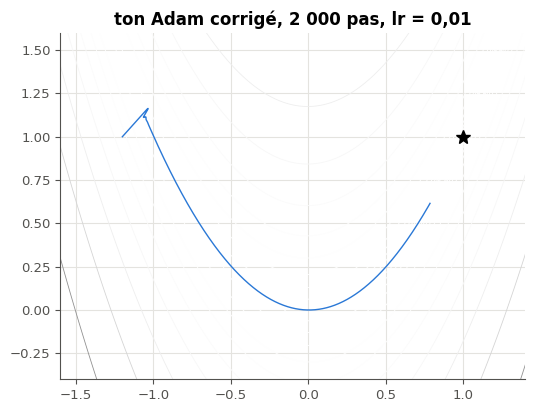

✅ Ex 19.22a : Parfait !
✅ Ex 19.22b : Bravo !


In [41]:
def adam_fixed_22(grad, w0, lr=0.01, steps=2000, beta1=0.9, beta2=0.999, eps=1e-8):
    """The corrected Adam: copy the code of adam_22 here, then fix it (same signature, same result shape).
    Do not call mylearn here: this function stands alone."""
    w = np.array(w0, dtype=float)
    m = np.zeros_like(w)
    v = np.zeros_like(w)
    path = [w.copy()]
    for t in range(1, steps + 1):                        # 1) the bias correction counts the steps from 1
        g = grad(w)
        m = beta1 * m + (1 - beta1) * g                  # 3) the first moment uses beta1, not beta2
        v = beta2 * v + (1 - beta2) * g ** 2
        m_hat = m / (1 - beta1 ** t)
        v_hat = v / (1 - beta2 ** t)
        w = w - lr * m_hat / (np.sqrt(v_hat) + eps)      # 2) divide by the square root of v_hat (eps after it)
        path.append(w.copy())
    return np.array(path)

def first_step_22(scale=1.0):
    """The first position of YOUR adam_fixed_22 on the Rosenbrock function (its loss multiplied by scale)."""
    with np.errstate(all="ignore"):
        path = np.asarray(adam_fixed_22(lambda w: scale * rosen_grad(w), ROSEN_START, lr=0.01, steps=1), dtype=float)
    if path.shape != (2, 2):
        raise ValueError(f"adam_fixed_22(..., steps=1) doit rendre un tableau de forme (2, 2), reçu {path.shape}")
    return path[1]


FINAL_22 = None
with checked("19.22"):
    G0_22 = rosen_grad(np.array(ROSEN_START))
    points_22 = [("1) le premier pas donne une position finie (ni nan ni inf)",
                  lambda: bool(np.all(np.isfinite(first_step_22())))),
                 ("2) le premier pas ne change pas si l'on multiplie la loss par 100",
                  lambda: bool(np.allclose(first_step_22(), first_step_22(100.0), rtol=0, atol=1e-9))),
                 ("3) le premier pas vaut exactement lr dans chaque coordonnée, à l'opposé du gradient",
                  lambda: bool(np.allclose(first_step_22() - np.array(ROSEN_START), -0.01 * np.sign(G0_22), rtol=1e-6, atol=0)))]
    for k_22, (label_22, test_22) in enumerate(points_22):
        if not test_22():
            print(f"❌ Ex 19.22 : point {label_22} : faux. Cherche la ligne qui le produit.")
            for later_22 in points_22[k_22 + 1:]:
                print(f"⏳ Ex 19.22 : point {later_22[0]} : corrige d'abord le point {label_22[:2]}")
            break
        print(f"✅ Ex 19.22 : point {label_22} : juste.")
    else:
        with np.errstate(all="ignore"):
            path_22 = np.asarray(adam_fixed_22(rosen_grad, ROSEN_START), dtype=float)
        if path_22.shape != (2001, 2) or not np.all(np.isfinite(path_22)):
            print(f"❌ Ex 19.22 : 2 000 pas doivent donner un tableau (2001, 2) fini ; reçu la forme {path_22.shape}.")
        else:
            FINAL_22 = path_22[-1]
            print(f"after 2 000 steps: w = {np.round(FINAL_22, 4).tolist()} · loss {rosen(FINAL_22):.3g}")
            if torch is not None:
                same("19.22", "la position après 2 000 pas, contre torch.optim.Adam", FINAL_22,
                     torch_path("Adam", {"lr": 0.01}, ROSEN_START, rosen_grad, 2000), rtol=1e-8, atol=1e-10)
            fig_22, ax_22 = plt.subplots(figsize=(6, 4.5))
            xs_22, ys_22 = np.meshgrid(np.linspace(-1.6, 1.4, 300), np.linspace(-0.4, 1.6, 300))
            ax_22.contour(xs_22, ys_22, wb.synth.rosenbrock(xs_22, ys_22), levels=np.logspace(-1, 3, 15), cmap="Greys", linewidths=0.6)
            ax_22.plot(path_22[:, 0], path_22[:, 1], color="#2a78d6", lw=1)
            ax_22.plot(1, 1, "k*", ms=10)
            ax_22.set_title("ton Adam corrigé, 2 000 pas, lr = 0,01")
            plt.show()
if FINAL_22 is not None:
    wb.check("19.22a", FINAL_22[0], computed=True)
    wb.check("19.22b", FINAL_22[1], computed=True)

In [42]:
wb.record("19.22a", FINAL_22[0], decimals=4)
wb.record("19.22b", FINAL_22[1], decimals=4)

WB_ANSWER {"decimals": 4, "hash": "5c4f59d9a1e7b8bf611d4a7ba9b4592d4bc549a6f80e74ce7bd466f9c90ff6bc", "hash_coarse": "e528c7d416d7b359babe8224bcdc554bdbdf3a6628127a9bf6ae886995c472dc", "id": "19.22a", "kind": "float", "magnitude": -1, "sign": 1}
📝 Ex 19.22a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "0627dd5a5bf6694ea2e14500a058f4cfe2bf91645d34d486b64b1c4bf73c8f23", "hash_coarse": "a7a4fe067ba954c7a9392088a99476e22af9ad9a461a0ed473ebeeef1ff18e4a", "id": "19.22b", "kind": "float", "magnitude": -1, "sign": 1}
📝 Ex 19.22b : réponse enregistrée (float, 4 décimale(s)).


💡 Les trois erreurs : 1) `for t in range(steps)` fait commencer $t$ à 0, et la correction de biais divise par $1 - \beta^0 = 0$ : `inf / inf`, d'où le `nan` dès le premier pas (il faut `range(1, steps + 1)`) ; 2) il manque la racine : `m_hat / (v_hat + eps)` vaut environ $1/g$, si bien que le pas **grandit** quand le gradient rapetisse, et explose au fond de la vallée (la loss × 100 divise le pas par 100 : le point 2 le voit) ; 3) `(1 - beta2) * g` dans le premier moment : $\hat m$ est dix fois trop petit au premier pas, et Adam rampe à $0{,}01\,\eta$ (le point 2 ne le voit pas : un facteur constant ne dépend pas de l'échelle ; le point 3, si). Corrigé, le chemin longe la vallée courbe de Rosenbrock et atteint $(0{,}785 ;\ 0{,}616)$ en 2 000 pas avec $\eta = 0{,}01$ : Adam avance d'environ $\eta$ par pas, et le fond de la vallée est long.

## Partie C · Lire des courbes, les solveurs de scikit-learn, et trois façons de grouper les exemples

Reconnaître des optimiseurs et des plannings sur des courbes de loss (19.23), régler les solveurs de `MLPClassifier` (19.24), puis refaire l'expérience du livre : batch, stochastique et mini-batch sur les lunes (19.25).

### Ex 19.23 — Diagnostiquer des courbes de loss d'optimiseurs 📈 ★★ ⏱️ 20 min
**Objectif :** reconnaître, sur des courbes de loss par mise à jour, un planning, un optimiseur adaptatif, une divergence et la taille du mini-batch.  
**Prérequis :** Ex 19.18 · 18.22 · fiche §19.3.3, §19.4.2, §19.5.3, sections sur le warmup et le cosinus · **Fil rouge :** MNIST · **Parcours :** R, M

Six entraînements d'un même MLP sur MNIST (10 classes ; la loss du mini-batch, en nats, à chaque mise à jour ; les courbes sont fabriquées, mais leurs formes sont celles qu'on rencontre). Chacun utilise un des réglages ci-dessous, sauf un, qui est un Adam bien réglé. Pour chaque question, la **lettre** de la courbe (sauf c), un entier) :
a) `warmup_23` : AdamW avec un **warmup** linéaire, puis une **décroissance en cosinus** jusqu'à 0 ;
b) `step_23` : SGD avec momentum et un planning **par paliers** ;
c) `drops_23` : combien de fois le learning rate de b) est-il diminué pendant l'entraînement ?
d) `adagrad_23` : **Adagrad**, avec un learning rate trop petit pour cette durée ;
e) `dead_23` : Adam avec un learning rate **beaucoup trop grand** (le réseau finit par répondre la même chose pour toutes les images) ;
f) `single_23` : SGD avec des mini-batches d'**un seul** exemple.

Dans tes notes : pour e), quelle valeur exacte attends-tu pour le palier, et pourquoi ? Pour a), pourquoi le bruit diminue-t-il à la fin ? Pour d), qu'est-ce qui, dans la formule d'Adagrad, explique la forme de la courbe, et que ferais-tu pour l'améliorer ?

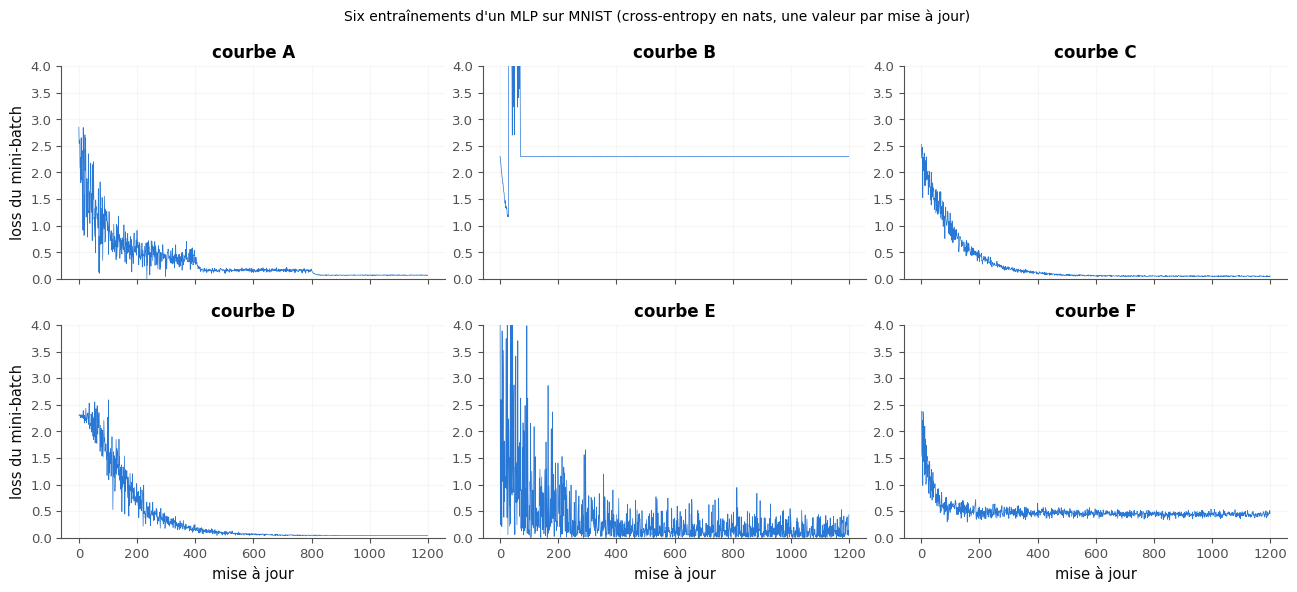

In [43]:
CURVES_23 = wb.synth.optimizer_curves()                # six curves, labelled A to F
fig_23, axes_23 = plt.subplots(2, 3, figsize=(13, 6), sharex=True)
for ax, (name, curve) in zip(axes_23.ravel(), CURVES_23.items()):
    ax.plot(curve, color="#2a78d6", lw=0.5)
    ax.set_title(f"courbe {name}")
    ax.set_ylim(0, 4)
    ax.grid(alpha=0.3)
for ax in axes_23[1]:
    ax.set_xlabel("mise à jour")
for ax in axes_23[:, 0]:
    ax.set_ylabel("loss du mini-batch")
fig_23.suptitle("Six entraînements d'un MLP sur MNIST (cross-entropy en nats, une valeur par mise à jour)", fontsize=10)
plt.tight_layout()
plt.show()

In [44]:
warmup_23, step_23, drops_23, adagrad_23, dead_23, single_23 = "D", "A", 2, "F", "B", "E"

In [45]:
wb.record("19.23a", "D", mistakes={"cette courbe descend par marches : relis la définition de chaque cas": "A", "cette courbe chute un instant, fait des pics, puis reste parfaitement plate : relis la définition de chaque cas": "B", "cette courbe baisse vite et régulièrement, avec un bruit modéré : relis la définition de chaque cas": "C", "cette courbe est la plus bruitée des six : relis la définition de chaque cas": "E", "cette courbe chute très vite, puis ne baisse presque plus : relis la définition de chaque cas": "F"})
wb.record("19.23b", "A", mistakes={"cette courbe chute un instant, fait des pics, puis reste parfaitement plate : relis la définition de chaque cas": "B", "cette courbe baisse vite et régulièrement, avec un bruit modéré : relis la définition de chaque cas": "C", "regarde le début et la fin de cette courbe : relis la définition de chaque cas": "D", "cette courbe est la plus bruitée des six : relis la définition de chaque cas": "E", "cette courbe chute très vite, puis ne baisse presque plus : relis la définition de chaque cas": "F"})
wb.record("19.23d", "F", mistakes={"cette courbe descend par marches : relis la définition de chaque cas": "A", "cette courbe chute un instant, fait des pics, puis reste parfaitement plate : relis la définition de chaque cas": "B", "cette courbe baisse vite et régulièrement, avec un bruit modéré : relis la définition de chaque cas": "C", "regarde le début et la fin de cette courbe : relis la définition de chaque cas": "D", "cette courbe est la plus bruitée des six : relis la définition de chaque cas": "E"})
wb.record("19.23e", "B", mistakes={"cette courbe descend par marches : relis la définition de chaque cas": "A", "cette courbe baisse vite et régulièrement, avec un bruit modéré : relis la définition de chaque cas": "C", "regarde le début et la fin de cette courbe : relis la définition de chaque cas": "D", "cette courbe est la plus bruitée des six : relis la définition de chaque cas": "E", "cette courbe chute très vite, puis ne baisse presque plus : relis la définition de chaque cas": "F"})
wb.record("19.23f", "E", mistakes={"cette courbe descend par marches : relis la définition de chaque cas": "A", "cette courbe chute un instant, fait des pics, puis reste parfaitement plate : relis la définition de chaque cas": "B", "cette courbe baisse vite et régulièrement, avec un bruit modéré : relis la définition de chaque cas": "C", "regarde le début et la fin de cette courbe : relis la définition de chaque cas": "D", "cette courbe chute très vite, puis ne baisse presque plus : relis la définition de chaque cas": "F"})
wb.record("19.23c", 2, fractional="on compte des baisses du learning rate : un entier",
          mistakes={"compte les marches de la courbe, pas ses paliers : une marche est une baisse": 3,
                    "une seule ? Regarde toute la longueur de la courbe": 1})

WB_ANSWER {"hash": "8aea1f8b78f13aeaa30b406d994c5b2ebea80d50b42211872d1d6af61dc214a8", "id": "19.23a", "kind": "str", "mistakes": {"2e11957a449382702edf7724aa9bd59cfbf4c1409356838d60dab97efbfcae25": "cette courbe chute très vite, puis ne baisse presque plus : relis la définition de chaque cas", "5b48e560ab6b947974ccbf8504cac7bfdd9f949118c86773a6c63636e357436e": "cette courbe est la plus bruitée des six : relis la définition de chaque cas", "bcc47384a3c4bd1d06002601ef6acae50f8cc4a39e5cc68400cc49da4d66b3fb": "cette courbe descend par marches : relis la définition de chaque cas", "de151d099d1deefbac5958124a5aa3a1e127c4886a1b27fe93124759a353605e": "cette courbe chute un instant, fait des pics, puis reste parfaitement plate : relis la définition de chaque cas", "ffaf6c13afc20dc801d114f783d3d0af37c78e7b5fe84a23ea276d0d9d55bb21": "cette courbe baisse vite et régulièrement, avec un bruit modéré : relis la définition de chaque cas"}}
📝 Ex 19.23a : réponse enregistrée (str).
WB_ANSWER {"hash": "

💡 D monte lentement en régime pendant le warmup (la loss reste vers 2,3 au début, le learning rate partant de 0), descend vite au milieu, et son bruit s'éteint à la fin, quand le cosinus ramène $\eta$ vers 0. A descend par **marches** : deux chutes brusques, au tiers et aux deux tiers, chaque fois que $\eta$ est divisé, avec un bruit plus faible après chacune. F chute très vite, puis rampe : la somme des carrés d'Adagrad ne fait que grandir, et ses pas rétrécissent sans fin (un $\eta$ plus grand, ou RMSprop). B chute un instant, fait des pics énormes, puis reste plate à $\ln 10 \approx 2{,}303$ : la loss d'un réseau qui répond $\frac{1}{10}$ à chaque classe (ch. 18), des poids ruinés par des pas trop grands. E est la plus bruitée : chaque point est la loss d'**un** exemple, qui varie de presque 0 à plusieurs nats. C, enfin, est l'Adam bien réglé.

### Ex 19.24 — Les solveurs de MLPClassifier : sgd, momentum, adaptive, adam 📦 ★★ ⏱️ 25 min
**Objectif :** régler les optimiseurs et les plannings de MLPClassifier, et comparer leurs courbes sur MNIST.  
**Prérequis :** ch. 15 (scikit-learn) · Ex 19.16 · fiche §19.3.3, §19.5.1, §19.5.5, encadré sur les valeurs par défaut · **Fil rouge :** MNIST · **Parcours :** R, C

Le `MLPClassifier` de scikit-learn (ch. 15 à 18) a ses optimiseurs à lui. Écris `make_24(name)`, qui rend un `MLPClassifier` **neuf** pour chacune des six configurations du tableau. Toutes ont `hidden_layer_sizes=(64,)`, `batch_size=64`, `max_iter=EPOCHS_24` (20 epochs) et `random_state=0`, et gardent les valeurs par défaut de tous les autres paramètres.

| `name` | `solver` | `learning_rate_init` | réglages en plus |
|---|---|---|---|
| `"sgd"` | `"sgd"` | 0,01 | `momentum=0.0` |
| `"momentum"` | `"sgd"` | 0,01 | `momentum=0.9`, `nesterovs_momentum=False` |
| `"nesterov"` | `"sgd"` | 0,01 | `momentum=0.9` (Nesterov est le défaut) |
| `"adaptive"` | `"sgd"` | 0,01 | `momentum=0.9`, `learning_rate="adaptive"` |
| `"invscaling"` | `"sgd"` | 0,01 | `momentum=0.9`, `learning_rate="invscaling"` |
| `"adam"` | `"adam"` | 0,001 | aucun |

Lis, dans la documentation de [`MLPClassifier`](https://scikit-learn.org/1.6/modules/generated/sklearn.neural_network.MLPClassifier.html), ce que font `learning_rate="adaptive"` et `learning_rate="invscaling"` (avec `power_t`).

La vérification contrôle les réglages de chaque configuration (`get_params()`), puis entraîne les six sur les premières images d'entraînement de MNIST (5 000 en mode rapide), affiche le nombre d'epochs, la loss finale, l'accuracy sur 2 000 images de test, le learning rate à la fin (`_optimizer.learning_rate`, un attribut interne) et le temps, et trace les courbes `loss_curve_`.

Dans tes notes : pourquoi `"adaptive"` donne-t-il ici exactement les mêmes nombres que `"nesterov"` ? Que vaut le learning rate de `"invscaling"` à la fin, et pourquoi si peu (la documentation dit ce que compte son $t$) ? Lequel choisirais-tu, et avec quel réglage changé, pour un entraînement plus long ?

In [46]:
N_24 = 5000 if FAST_MODE else 20000                  # training images (the first ones of the training set)
EPOCHS_24 = 20
X_24, Y_24 = wb.datasets.load_mnist("train", n=None, flatten=True, normalize=True)
X_24, Y_24 = X_24[:N_24], Y_24[:N_24]
X_TEST_24, Y_TEST_24 = wb.datasets.load_mnist("test", flatten=True, normalize=True)
X_TEST_24, Y_TEST_24 = X_TEST_24[:2000], Y_TEST_24[:2000]
NAMES_24 = ["sgd", "momentum", "nesterov", "adaptive", "invscaling", "adam"]
print("train:", X_24.shape, "· test:", X_TEST_24.shape)

train: (5000, 784) · test: (2000, 784)


✅ Ex 19.24 : sgd : réglages conformes au tableau.
✅ Ex 19.24 : momentum : réglages conformes au tableau.
✅ Ex 19.24 : nesterov : réglages conformes au tableau.
✅ Ex 19.24 : adaptive : réglages conformes au tableau.
✅ Ex 19.24 : invscaling : réglages conformes au tableau.
✅ Ex 19.24 : adam : réglages conformes au tableau.


solver       epochs   final loss   test accuracy   learning rate at the end   seconds
sgd              20       0.3535          0.8555                       0.01       1.2
momentum         20       0.1028          0.9010                       0.01       1.0
nesterov         20       0.1039          0.9000                       0.01       1.0
adaptive         20       0.1039          0.9000                       0.01       3.9
invscaling       20       0.4475          0.8385                   3.16e-05       1.0
adam             20       0.0454          0.9115                   0.000891       1.6


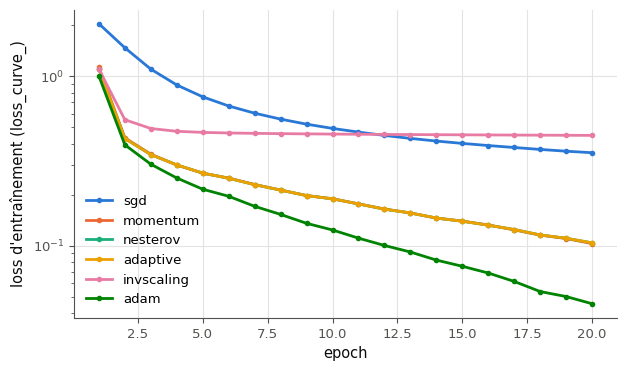

In [47]:
def make_24(name):
    """A NEW, unfitted MLPClassifier for the configuration `name` of the table of the statement."""
    common = dict(hidden_layer_sizes=(64,), batch_size=64, max_iter=EPOCHS_24, random_state=0)
    settings = {"sgd": dict(solver="sgd", learning_rate_init=0.01, momentum=0.0),
                "momentum": dict(solver="sgd", learning_rate_init=0.01, momentum=0.9, nesterovs_momentum=False),
                "nesterov": dict(solver="sgd", learning_rate_init=0.01, momentum=0.9, nesterovs_momentum=True),
                "adaptive": dict(solver="sgd", learning_rate_init=0.01, momentum=0.9, learning_rate="adaptive"),
                "invscaling": dict(solver="sgd", learning_rate_init=0.01, momentum=0.9, learning_rate="invscaling"),
                "adam": dict(solver="adam", learning_rate_init=0.001)}
    return MLPClassifier(**common, **settings[name])

EXPECTED_24 = {
    "sgd": {"solver": "sgd", "learning_rate_init": 0.01, "momentum": 0.0, "learning_rate": "constant"},
    "momentum": {"solver": "sgd", "learning_rate_init": 0.01, "momentum": 0.9, "nesterovs_momentum": False, "learning_rate": "constant"},
    "nesterov": {"solver": "sgd", "learning_rate_init": 0.01, "momentum": 0.9, "nesterovs_momentum": True, "learning_rate": "constant"},
    "adaptive": {"solver": "sgd", "learning_rate_init": 0.01, "momentum": 0.9, "nesterovs_momentum": True, "learning_rate": "adaptive"},
    "invscaling": {"solver": "sgd", "learning_rate_init": 0.01, "momentum": 0.9, "nesterovs_momentum": True,
                   "learning_rate": "invscaling", "power_t": 0.5},
    "adam": {"solver": "adam", "learning_rate_init": 0.001, "beta_1": 0.9, "beta_2": 0.999, "epsilon": 1e-8},
}
COMMON_24 = {"hidden_layer_sizes": (64,), "batch_size": 64, "max_iter": EPOCHS_24, "random_state": 0, "alpha": 0.0001,
             "tol": 0.0001, "n_iter_no_change": 10, "early_stopping": False, "shuffle": True}
MODELS_24 = {}
with checked("19.24"):
    for name_24 in NAMES_24:
        model_24 = make_24(name_24)
        if not isinstance(model_24, MLPClassifier) or hasattr(model_24, "coefs_"):
            print(f"❌ Ex 19.24 : make_24({name_24!r}) doit rendre un MLPClassifier NEUF (pas encore entraîné) ; reçu {type(model_24).__name__}.")
            continue
        params_24 = model_24.get_params()
        wrong_24 = {k: params_24.get(k) for k, v in {**COMMON_24, **EXPECTED_24[name_24]}.items()
                    if params_24.get(k) != v and not (isinstance(v, tuple) and tuple(np.atleast_1d(params_24.get(k))) == v)}
        verdict("19.24", not wrong_24, f"{name_24} : réglages conformes au tableau.",
                f"{name_24} : réglages à revoir : {wrong_24} (relis la ligne {name_24!r} du tableau ; ne change rien d'autre).")
        if not wrong_24:
            MODELS_24[name_24] = model_24
if len(MODELS_24) == len(NAMES_24):
    RESULTS_24 = {}
    for name_24, model_24 in MODELS_24.items():
        started_24 = time.perf_counter()
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            model_24.fit(X_24, Y_24)
        RESULTS_24[name_24] = (model_24.loss_curve_, model_24.score(X_TEST_24, Y_TEST_24), model_24.n_iter_,
                               model_24._optimizer.learning_rate, time.perf_counter() - started_24)
    print("solver       epochs   final loss   test accuracy   learning rate at the end   seconds")
    for name_24, (curve_24, acc_24, n_24, lr_24, s_24) in RESULTS_24.items():
        print(f"{name_24:11} {n_24:7d}   {curve_24[-1]:10.4f}   {acc_24:13.4f}   {lr_24:24.3g}   {s_24:7.1f}")
    fig_24, ax_24 = plt.subplots(figsize=(7, 4))
    for name_24, (curve_24, *_rest) in RESULTS_24.items():
        ax_24.plot(np.arange(1, len(curve_24) + 1), curve_24, marker=".", label=name_24)
    ax_24.set_yscale("log")
    ax_24.set_xlabel("epoch")
    ax_24.set_ylabel("loss d'entraînement (loss_curve_)")
    ax_24.legend()
    plt.show()

💡 `"adaptive"` ne divise le learning rate par 5 que lorsque deux epochs de suite ne font pas baisser la loss d'au moins `tol` ($10^{-4}$) ; ici, la loss baisse à chaque epoch, le planning ne se déclenche jamais, et l'entraînement est celui de `"nesterov"`, nombre pour nombre. `"invscaling"` divise par $t^{0{,}5}$, où $t$ compte les **exemples** vus (pas les epochs) : après 20 epochs de 5 000 images, $\eta$ vaut $0{,}01/\sqrt{10^5} \approx 3 \times 10^{-5}$, et il est déjà divisé par 100 après la première ; la loss s'arrête de baisser très tôt. Le momentum fait gagner beaucoup sur SGD seul, Nesterov à peine plus, et Adam, avec son $\eta$ de $10^{-3}$, va le plus vite ; pour un entraînement plus long, Adam ou Nesterov avec `"adaptive"` (qui baisse $\eta$ quand la loss plafonne), ou un `power_t` bien plus petit. Les nombres exacts sont dans `05_solutions.md`.

### Ex 19.25 — Batch, stochastique, mini-batch sur les lunes 🔬 ★★★ ⏱️ 45 min
**Objectif :** refaire l'expérience du livre et comparer trois façons de grouper les exemples, aux epochs, aux mises à jour et au temps.  
**Prérequis :** Ex 19.16 · Ex 18.19 · ch. 16 (`init_mlp`) · fiche §19.4, §19.4.1 à §19.4.3 · **Fil rouge :** synth · **Parcours :** C

Le banc d'essai du livre (§19.4) : 300 points de lunes (`X_25`, standardisés, 150 par classe), un réseau à trois couches cachées de 12, 13 et 13 neurones et deux sorties (`SIZES_25`), et un learning rate constant de 0,01. Écris `train_25(batch_size, max_epochs, lr=0.01, seed=0)`, qui suit **exactement** ce protocole :
1. `rng = np.random.default_rng(seed)`, puis `params = init_mlp(SIZES_25, "he_normal", rng)` (ta fonction du ch. 16) et un **seul** `SGD` (ta classe de 19.16) sur `flat(params)` ;
2. à chaque epoch, pour chaque `idx` de `iterate_minibatches(len(X_25), batch_size, rng=rng)` (`mylearn.utils`) : la passe avant (`mlp_forward`, ReLU cachées, sortie linéaire), la cross-entropy softmax sur les logits (`softmax_cross_entropy`, ch. 18), la passe arrière (`mlp_backward`), puis `opt.step(flat(grads))` ;
3. après chaque epoch, le nombre de points de `X_25` mal classés (l'argmax des deux logits) ; on s'arrête dès qu'il vaut 0, ou après `max_epochs`.

Elle rend un dictionnaire : `"errors"` (la liste des erreurs, une par epoch), `"updates"` (le nombre total d'appels à `step`) et `"seconds"` (le temps d'entraînement).

La vérification fait d'abord deux petits contrôles (trois epochs d'un batch de 300 : 3 mises à jour ; une epoch de mini-batches de 32 : 10 mises à jour), puis lance les trois stratégies : batch (300 exemples, au plus 20 000 epochs), mini-batch (32, au plus 3 000 epochs) et stochastique (1, au plus 300 epochs) ; elle affiche les epochs, les mises à jour et le temps de chacune, et trace les erreurs en fonction des epochs puis des mises à jour. Le tout prend quelques secondes.

Dans tes notes : classe les trois stratégies selon le nombre d'epochs, puis selon le nombre de mises à jour, puis selon le temps. Le classement change-t-il ? Compare tes nombres à ceux du livre (20 000, 400 et 5 000 epochs) : qu'est-ce qui se ressemble, qu'est-ce qui diffère, et pourquoi tes nombres exacts dépendent-ils de ton implémentation ?

In [48]:
X_25, y_25 = wb.synth.make_moons(n=300, noise=0.15, seed=1925)   # the book's banc d'essai: 300 points, 150 per class
X_25 = (X_25 - X_25.mean(axis=0)) / X_25.std(axis=0)
SIZES_25 = [2, 12, 13, 13, 2]                                           # the book's network: 12, 13 and 13 hidden neurons
print("moons:", X_25.shape, "· classes:", np.bincount(y_25).tolist(), "· parameters:",
      sum(a * b + b for a, b in zip(SIZES_25[:-1], SIZES_25[1:])))

moons: (300, 2) · classes: [150, 150] · parameters: 415


strategy               batch size   epochs to 0 errors   updates   seconds   final errors
batch                         300                 3333      3333       1.8              0
mini-batch                     32                  334      3340       0.6              0
stochastic (SGD)                1                   13      3900       0.5              0


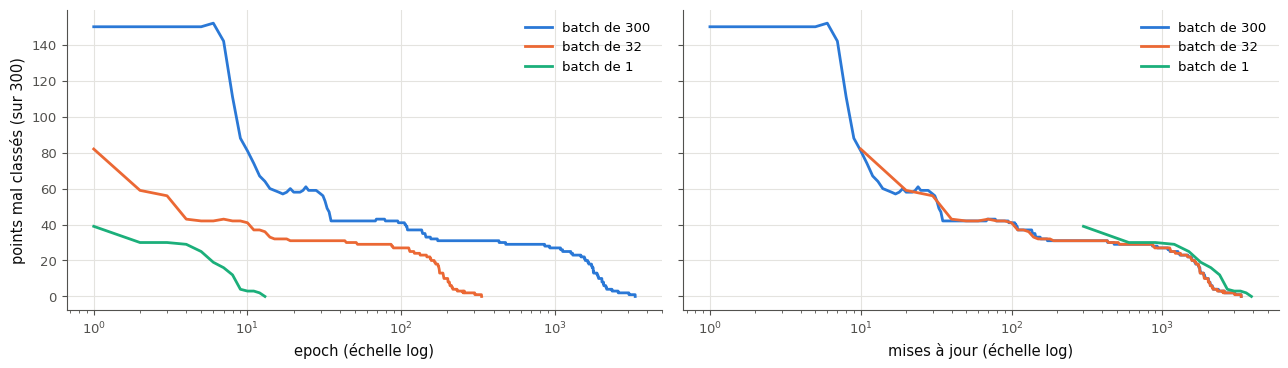

In [49]:
from mylearn.nn.activations import relu, relu_derivative
from mylearn.nn.backward import mlp_backward, softmax_cross_entropy
from mylearn.nn.layers import init_mlp, mlp_forward
from mylearn.utils import iterate_minibatches


def train_25(batch_size, max_epochs, lr=0.01, seed=0):
    """Train the network SIZES_25 (ReLU hidden layers, 2 logits, softmax cross-entropy) on (X_25, y_25) with YOUR SGD
    and mini-batches of batch_size, following the protocol of the statement; stop at 0 errors or after max_epochs.

    Returns a dict: "errors" (list of int: the number of misclassified points of X_25 after each epoch), "updates"
    (int: the total number of calls to opt.step) and "seconds" (float: the training time).
    """
    started = time.perf_counter()
    rng = np.random.default_rng(seed)
    params = init_mlp(SIZES_25, "he_normal", rng)
    opt = mylearn.optim.SGD(flat(params), lr=lr)
    errors, updates = [], 0
    for _ in range(max_epochs):
        for idx in iterate_minibatches(len(X_25), batch_size, rng=rng):
            logits, cache = mlp_forward(X_25[idx], params, relu, None, return_cache=True)
            _, dout = softmax_cross_entropy(logits, y_25[idx])
            opt.step(flat(mlp_backward(dout, cache, params, activation_derivative=relu_derivative)))
            updates += 1
        errors.append(int(np.sum(mlp_forward(X_25, params, relu).argmax(axis=1) != y_25)))
        if errors[-1] == 0:
            break
    return {"errors": errors, "updates": updates, "seconds": time.perf_counter() - started}

RUNS_25 = {}
with checked("19.25"):
    control_25 = train_25(300, 3)
    keys_ok_25 = isinstance(control_25, dict) and {"errors", "updates", "seconds"} <= set(control_25)
    if not keys_ok_25:
        print('❌ Ex 19.25 : train_25 doit rendre un dictionnaire avec les clés "errors", "updates" et "seconds".')
    elif len(control_25["errors"]) != 3 or control_25["updates"] != 3:
        print(f"❌ Ex 19.25 : 3 epochs d'un seul batch de 300 points : attendu 3 erreurs comptées et 3 mises à jour, reçu "
              f"{len(control_25['errors'])} et {control_25['updates']!r}.")
    elif len(train_25(32, 1)["errors"]) != 1 or train_25(32, 1)["updates"] != 10:
        print("❌ Ex 19.25 : une epoch de mini-batches de 32 sur 300 points doit faire 10 mises à jour (la dernière sur 12 points).")
    else:
        for batch_25, epochs_25 in ((300, 20000), (32, 3000), (1, 300)):
            RUNS_25[batch_25] = train_25(batch_25, epochs_25)
if len(RUNS_25) == 3:
    print("strategy               batch size   epochs to 0 errors   updates   seconds   final errors")
    for (batch_25, run_25), name_25 in zip(RUNS_25.items(), ("batch", "mini-batch", "stochastic (SGD)")):
        print(f"{name_25:22} {batch_25:10d}   {len(run_25['errors']):18d}   {run_25['updates']:7d}   {run_25['seconds']:7.1f}   "
              f"{run_25['errors'][-1]:12d}")
    fig_25, axes_25 = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
    for batch_25, run_25 in RUNS_25.items():
        per_epoch_25 = int(np.ceil(300 / batch_25))
        epochs_axis_25 = np.arange(1, len(run_25["errors"]) + 1)
        axes_25[0].plot(epochs_axis_25, run_25["errors"], label=f"batch de {batch_25}")
        axes_25[1].plot(epochs_axis_25 * per_epoch_25, run_25["errors"], label=f"batch de {batch_25}")
    axes_25[0].set_xlabel("epoch (échelle log)")
    axes_25[1].set_xlabel("mises à jour (échelle log)")
    for ax in axes_25:
        ax.set_xscale("log")
        ax.legend()
    axes_25[0].set_ylabel("points mal classés (sur 300)")
    plt.tight_layout()
    plt.show()

💡 Avec la référence : le batch atteint 0 erreur en 3 333 epochs (autant de mises à jour, 1,6 s), le mini-batch en 334 epochs (3 340 mises à jour, 0,6 s), le stochastique en 13 epochs (3 900 mises à jour, 0,5 s). Aux epochs, le stochastique écrase tout ; aux **mises à jour**, les trois se valent à peu près ; au temps, le mini-batch et le stochastique gagnent sur ce petit problème. La discussion est dans `05_solutions.md`.

## Partie D · Des courses d'optimiseurs, puis le défi

Faire courir tes huit optimiseurs sur la fonction de Rosenbrock, chacun avec son meilleur learning rate (19.26), puis sur MNIST, avec un warmup, un cosinus et du clipping (19.27), et relever le défi : 98 % sur MNIST en cinq epochs avec ta librairie (19.28).

### Ex 19.26 — Course d'optimiseurs sur la fonction de Rosenbrock 🔬 ★★★ ⏱️ 45 min
**Objectif :** comparer équitablement huit optimiseurs, chacun avec son meilleur learning rate, sur la vallée courbe de Rosenbrock.  
**Prérequis :** Ex 19.18 · ch. 5 (la fonction de Rosenbrock) · fiche §19.2.1, §19.5, §19.6 (encadré sur le No Free Lunch) · **Fil rouge :** Rosenbrock · **Parcours :** M, C

La fonction de Rosenbrock du ch. 5, $f(x, y) = (1 - x)^2 + 100\,(y - x^2)^2$, a son minimum en $(1, 1)$ au fond d'une vallée longue, étroite et courbe : un banc d'essai classique des optimiseurs. Écris `race_26(name, lr, steps=STEPS_26)`, qui fait tourner **ton** optimiseur `name` (le nom d'une classe de `mylearn.optim`, ses autres hyperparamètres par défaut, `getattr(mylearn.optim, name)`) depuis `ROSEN_START` $= (-1{,}2 ;\ 1)$, avec le gradient `rosen_grad`, et rend les `steps + 1` positions, un tableau de forme `(steps + 1, 2)`. Une course qui explose continue sans s'arrêter : ses positions deviennent `inf` ou `nan` (silence les avertissements de NumPy avec `np.errstate(all="ignore")`).

La vérification contrôle trois pas de SGD, puis lance la course : pour chacun des huit optimiseurs, les 13 learning rates de `LRS_26` (de $10^{-5}$ à 10, une grille logarithmique), 2 000 pas chacun (5 000 en mode complet) ; elle garde pour chaque optimiseur le learning rate qui finit le plus bas, affiche le tableau, puis trace les meilleurs chemins sur les courbes de niveau et leur loss au fil des pas. Une dizaine de secondes en tout.

Dans tes notes : quel optimiseur finit le plus bas, et lequel a la plage de learning rates la plus large ? Le meilleur learning rate d'un optimiseur est-il au bord de la grille, et que faudrait-il faire alors ? Pourquoi une course où chacun a **son** meilleur learning rate est-elle plus juste qu'une course au même learning rate pour tous (encadré sur le No Free Lunch) ? Que dit ce banc d'essai à deux paramètres d'un réseau à des millions de poids ?

In [50]:
STEPS_26 = 2000 if FAST_MODE else 5000
LRS_26 = [float(10.0 ** e) for e in np.arange(-5.0, 1.01, 0.5)]     # 1e-5, 3.2e-5, ..., 10: a log grid
NAMES_26 = ["SGD", "Momentum", "Nesterov", "Adagrad", "RMSprop", "Adadelta", "Adam", "AdamW"]
print(len(NAMES_26), "optimizers ×", len(LRS_26), "learning rates ×", STEPS_26, "steps")

8 optimizers × 13 learning rates × 2000 steps


✅ Ex 19.26 : race_26("SGD", 1e-3, steps=3) : un tableau (4, 2), comme attendu.


104 runs in 3.0 s
optimizer   best lr   final loss   lr of the grid that still converge (loss < 1e-2)
SGD           1e-03     7.82e-02   none
Momentum      3e-03     3.38e-27   3e-04, 1e-03, 3e-03
Nesterov      1e-03     8.52e-09   3e-04, 1e-03
Adagrad       1e+00     5.86e-03   1e+00
RMSprop       3e-03     8.06e-03   3e-03
Adadelta      3e-01     1.62e-01   none
Adam          1e-01     6.66e-17   3e-02, 1e-01, 3e-01, 3e+00
AdamW         1e-01     1.75e-03   3e-02, 1e-01


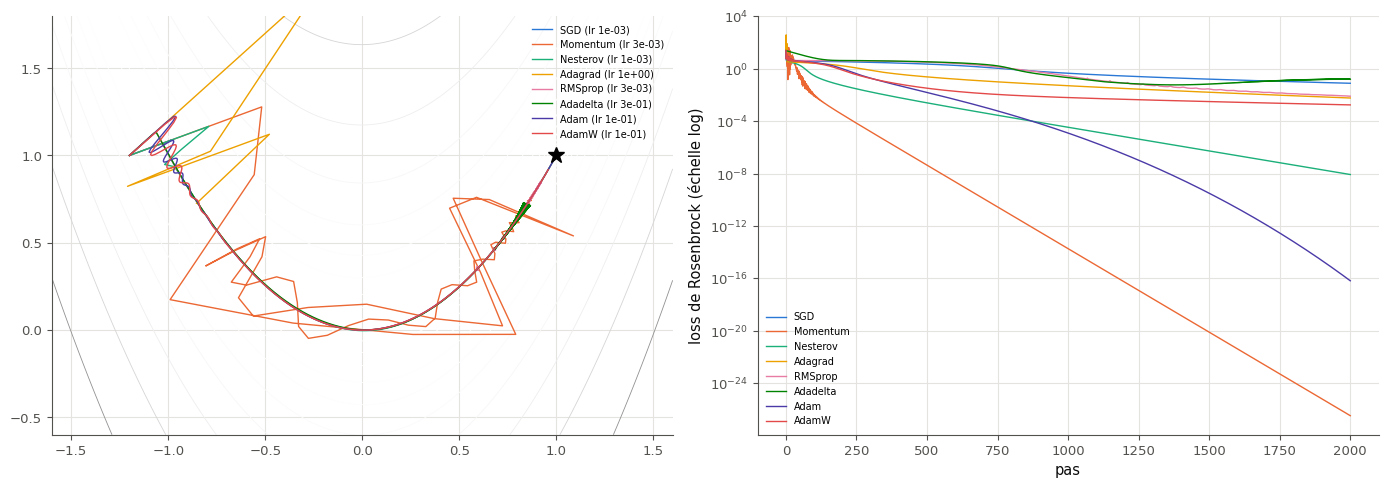

In [51]:
def race_26(name, lr, steps=STEPS_26):
    """Run YOUR optimizer `name` (a class name of mylearn.optim, other hyperparameters at their defaults) with learning
    rate lr on the Rosenbrock function from ROSEN_START; return the positions, an array of shape (steps + 1, 2).
    A run that blows up keeps going: its positions become inf or nan (NumPy warnings silenced)."""
    w = np.array(ROSEN_START, dtype=float)
    opt = getattr(mylearn.optim, name)([w], lr=lr)
    path = [w.copy()]
    with np.errstate(all="ignore"):
        for _ in range(steps):
            opt.step([rosen_grad(w)])
            path.append(w.copy())
    return np.array(path)

BEST_26 = {}
with checked("19.26"):
    probe_26 = np.asarray(race_26("SGD", 1e-3, steps=3), dtype=float)
    want_26 = [np.array(ROSEN_START)]
    for _ in range(3):
        want_26.append(want_26[-1] - 1e-3 * rosen_grad(want_26[-1]))
    if same("19.26", "race_26(\"SGD\", 1e-3, steps=3)", probe_26, np.array(want_26), rtol=1e-12, atol=1e-14):
        started_26 = time.perf_counter()
        table_26 = {}
        for name_26 in NAMES_26:
            finals_26 = []
            for lr_26 in LRS_26:
                path_26 = np.asarray(race_26(name_26, lr_26), dtype=float)
                with np.errstate(all="ignore"):
                    loss_26 = rosen(path_26[-1])
                finals_26.append(loss_26 if np.isfinite(loss_26) else np.inf)
            table_26[name_26] = finals_26
            k_26 = int(np.argmin(finals_26))
            BEST_26[name_26] = (LRS_26[k_26], finals_26[k_26], np.asarray(race_26(name_26, LRS_26[k_26]), dtype=float))
        print(f"{len(NAMES_26) * len(LRS_26)} runs in {time.perf_counter() - started_26:.1f} s")
if BEST_26:
    print("optimizer   best lr   final loss   lr of the grid that still converge (loss < 1e-2)")
    for name_26, (lr_26, loss_26, _) in BEST_26.items():
        ok_26 = [f"{lr:.0e}" for lr, l in zip(LRS_26, table_26[name_26]) if l < 1e-2]
        print(f"{name_26:10} {lr_26:8.0e}   {loss_26:10.2e}   {', '.join(ok_26) if ok_26 else 'none'}")
    fig_26, axes_26 = plt.subplots(1, 2, figsize=(14, 5))
    xs_26, ys_26 = np.meshgrid(np.linspace(-1.6, 1.6, 300), np.linspace(-0.6, 1.8, 300))
    axes_26[0].contour(xs_26, ys_26, wb.synth.rosenbrock(xs_26, ys_26), levels=np.logspace(-1, 3, 15), cmap="Greys", linewidths=0.6)
    for name_26, (lr_26, loss_26, path_26) in BEST_26.items():
        axes_26[0].plot(path_26[:, 0], path_26[:, 1], lw=1, label=f"{name_26} (lr {lr_26:.0e})")
        with np.errstate(all="ignore"):
            axes_26[1].plot([rosen(p) for p in path_26], lw=1, label=name_26)
    axes_26[0].plot(1, 1, "k*", ms=12)
    axes_26[0].set_xlim(-1.6, 1.6)
    axes_26[0].set_ylim(-0.6, 1.8)
    axes_26[0].legend(fontsize=7)
    axes_26[1].set_yscale("log")
    axes_26[1].set_xlabel("pas")
    axes_26[1].set_ylabel("loss de Rosenbrock (échelle log)")
    axes_26[1].legend(fontsize=7)
    plt.tight_layout()
    plt.show()

💡 Avec la référence (2 000 pas) : Momentum ($\eta = 3 \times 10^{-3}$) et Adam ($\eta = 0{,}1$) finissent pratiquement **au** minimum (des losses de $10^{-27}$ et $10^{-16}$), Nesterov presque ($10^{-8}$) ; Adam a la plage la plus large (quatre learning rates de la grille finissent sous $10^{-2}$, de 0,03 à 3) ; SGD et Adadelta n'y arrivent avec aucun learning rate en 2 000 pas, Adagrad et RMSprop avec un seul ; AdamW s'arrête à $1{,}7 \times 10^{-3}$, parce que son weight decay (0,01 par défaut) tire les poids vers 0 : le minimum de « la loss plus la décroissance » n'est pas $(1, 1)$. Au-delà de leur bande, SGD, Momentum et Nesterov explosent : la courbure du fond de la vallée, environ 1 000 au point $(1, 1)$, impose $\eta < 2/1\,000$ au SGD. Les nombres exacts et leur discussion sont dans `05_solutions.md`.

### Ex 19.27 — Huit optimiseurs sur MNIST, avec warmup, cosinus et clipping 🔬 ★★★ ⏱️ 60 min
**Objectif :** entraîner le même MLP sur MNIST avec tes huit optimiseurs, puis avec AdamW, un warmup, un cosinus et du clipping, et comparer.  
**Prérequis :** Ex 19.18 · Ex 19.19 · Ex 18.19 · fiche §19.5, §19.6, sections au-delà du livre · **Fil rouge :** MNIST · **Parcours :** C

Écris `train_27(make_optimizer, epochs=EPOCHS_27, schedule=None, clip=None, seed=0)`, qui entraîne le MLP `SIZES_27` (784-128-10, ReLU, sortie linéaire) sur `(X_27, Y_27)` (30 000 images et 3 epochs en mode rapide, 50 000 et 8 epochs en mode complet), en suivant **exactement** ce protocole :
1. `rng = np.random.default_rng(seed)`, `params = init_mlp(SIZES_27, "he_normal", rng)`, puis `opt = make_optimizer(flat(params))`, créé **une fois** ; `total` = le nombre de mises à jour de tout l'entraînement (`epochs` fois le nombre de mini-batches de `BATCH_27` = 64) ;
2. pour chaque mise à jour $k$ (de 0 à `total` − 1), dans l'ordre de `iterate_minibatches(len(X_27), BATCH_27, rng=rng)` : si `schedule` est donné, `opt.lr = schedule(k, total)` ; la passe avant, la cross-entropy softmax des logits, la passe arrière ; la norme globale des gradients (rendue par ta `clip_grad_norm` si `clip` est donné, qui les écrête au passage, calculée à la main sinon) ; puis `opt.step(...)` ;
3. après chaque epoch, l'accuracy sur `(X_VAL_27, Y_VAL_27)`, les 10 000 dernières images d'entraînement (jamais vues par l'entraînement).

Elle rend un dictionnaire de quatre listes : `"loss"` (la loss de chaque mini-batch), `"grad_norm"` (la norme de chaque mise à jour, **avant** clipping), `"lr"` (le learning rate de chaque mise à jour) et `"val_accuracy"` (une par epoch).

La vérification fait un petit contrôle (une epoch de SGD, avec un planning linéaire et du clipping), puis lance neuf configurations : les huit optimiseurs avec un learning rate habituel, et AdamW avec un warmup de 10 % des pas, un cosinus depuis $3 \times 10^{-3}$ et un clipping à 1 ; elle affiche l'accuracy de validation à chaque epoch, la norme médiane du gradient et le temps, puis trace la loss lissée, le learning rate et la norme du gradient. Moins d'une minute en mode rapide.

Dans tes notes : quels optimiseurs finissent en tête, et avec quel écart ? Adadelta et Adagrad sont-ils à leur avantage ici, et pourquoi ? Qu'a changé le planning de la dernière configuration, sur la courbe de loss et sur l'accuracy finale ? Le clipping à 1 a-t-il souvent agi (compare la norme médiane à 1) ? Peut-on conclure qu'un optimiseur est meilleur qu'un autre avec une seule graine et des learning rates non réglés ?

In [52]:
N_27, EPOCHS_27 = (30_000, 3) if FAST_MODE else (50_000, 8)
X_ALL_27, Y_ALL_27 = wb.datasets.load_mnist("train", flatten=True, normalize=True)
X_27, Y_27 = X_ALL_27[:N_27], Y_ALL_27[:N_27]
X_VAL_27, Y_VAL_27 = X_ALL_27[50_000:], Y_ALL_27[50_000:]           # the last 10 000 training images: validation
SIZES_27, BATCH_27 = [784, 128, 10], 64
print("train:", X_27.shape, "· validation:", X_VAL_27.shape, "·", EPOCHS_27, "epochs of",
      int(np.ceil(N_27 / BATCH_27)), "updates")

train: (30000, 784) · validation: (10000, 784) · 3 epochs of 469 updates


✅ Ex 19.27 : contrôle : une epoch de SGD, accuracy de validation 0.915.


configuration                                       val. accuracy by epoch        median grad norm   seconds
SGD, lr 0,1                                        [0.9224, 0.9388, 0.948]           0.823      5.2
Momentum 0,9, lr 0,01                              [0.9126, 0.9408, 0.9486]          0.811      2.6
Nesterov 0,9, lr 0,01                              [0.9182, 0.9406, 0.9489]          0.808      2.8
Adagrad, lr 0,01                                   [0.9429, 0.9515, 0.9547]          0.692      3.1
RMSprop, lr 1e-3                                   [0.9496, 0.96, 0.962]             0.654      3.1
Adadelta, lr 1                                     [0.9514, 0.9585, 0.9647]          0.644      4.0
Adam, lr 1e-3                                      [0.9321, 0.957, 0.9625]           0.714      4.0
AdamW, lr 1e-3                                     [0.9328, 0.9576, 0.9616]          0.716      3.9
AdamW, lr max 3e-3, warmup + cosinus, clipping 1   [0.9385, 0.9679, 0.9692]          0.572 

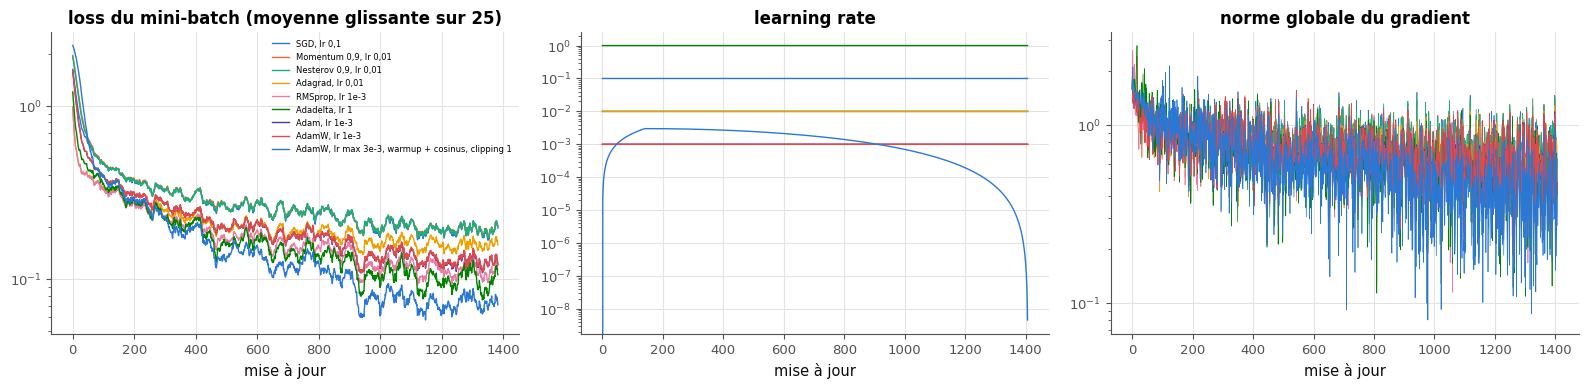

In [53]:
def train_27(make_optimizer, epochs=EPOCHS_27, schedule=None, clip=None, seed=0):
    """Train the MLP SIZES_27 (ReLU hidden layer, 10 logits, softmax cross-entropy) on (X_27, Y_27) with mini-batches of
    BATCH_27, with the optimizer make_optimizer(flat(params)), following the protocol of the statement.

    schedule(k, total) gives the learning rate of update k (k = 0, ..., total - 1; total = the number of updates of the
    whole training), or None for a constant learning rate; clip is a max_norm for YOUR clip_grad_norm, or None.
    Returns a dict of four lists: "loss" (the loss of each mini-batch, one per update), "grad_norm" (the global norm of
    the gradients of each update, before any clipping), "lr" (the learning rate used at each update) and
    "val_accuracy" (the accuracy on (X_VAL_27, Y_VAL_27) after each epoch).
    """
    A, L, B, O = mylearn.nn.activations, mylearn.nn.layers, mylearn.nn.backward, mylearn.optim
    rng = np.random.default_rng(seed)
    params = L.init_mlp(SIZES_27, "he_normal", rng)
    opt = make_optimizer(flat(params))
    total = epochs * int(np.ceil(len(X_27) / BATCH_27))
    history, k = {"loss": [], "grad_norm": [], "lr": [], "val_accuracy": []}, 0
    for _ in range(epochs):
        for idx in mylearn.utils.iterate_minibatches(len(X_27), BATCH_27, rng=rng):
            if schedule is not None:
                opt.lr = schedule(k, total)
            logits, cache = L.mlp_forward(X_27[idx], params, A.relu, None, return_cache=True)
            loss, dout = B.softmax_cross_entropy(logits, Y_27[idx])
            grads = flat(B.mlp_backward(dout, cache, params, activation_derivative=A.relu_derivative))
            norm = O.clip_grad_norm(grads, clip) if clip is not None else math.sqrt(sum(float(np.sum(g * g)) for g in grads))
            opt.step(grads)
            history["loss"].append(loss)
            history["grad_norm"].append(norm)
            history["lr"].append(opt.lr)
            k += 1
        predicted = L.mlp_forward(X_VAL_27, params, A.relu).argmax(axis=1)
        history["val_accuracy"].append(float(np.mean(predicted == Y_VAL_27)))
    return history

CONFIGS_27 = {
    "SGD, lr 0,1": (lambda p: mylearn.optim.SGD(p, lr=0.1), None, None),
    "Momentum 0,9, lr 0,01": (lambda p: mylearn.optim.Momentum(p, lr=0.01, momentum=0.9), None, None),
    "Nesterov 0,9, lr 0,01": (lambda p: mylearn.optim.Nesterov(p, lr=0.01, momentum=0.9), None, None),
    "Adagrad, lr 0,01": (lambda p: mylearn.optim.Adagrad(p, lr=0.01), None, None),
    "RMSprop, lr 1e-3": (lambda p: mylearn.optim.RMSprop(p, lr=1e-3), None, None),
    "Adadelta, lr 1": (lambda p: mylearn.optim.Adadelta(p, lr=1.0), None, None),
    "Adam, lr 1e-3": (lambda p: mylearn.optim.Adam(p, lr=1e-3), None, None),
    "AdamW, lr 1e-3": (lambda p: mylearn.optim.AdamW(p, lr=1e-3, weight_decay=1e-2), None, None),
    "AdamW, lr max 3e-3, warmup + cosinus, clipping 1": (
        lambda p: mylearn.optim.AdamW(p, lr=3e-3, weight_decay=1e-2),
        lambda k, total: mylearn.optim.cosine_lr(k, total, 3e-3, warmup_steps=total // 10), 1.0),
}
HISTORIES_27 = {}
with checked("19.27"):
    control_27 = train_27(lambda p: mylearn.optim.SGD(p, lr=0.1), epochs=1, schedule=lambda k, total: 0.1 * (1 - k / total), clip=1.0)
    n_updates_27 = int(np.ceil(N_27 / BATCH_27))
    keys_27 = isinstance(control_27, dict) and {"loss", "grad_norm", "lr", "val_accuracy"} <= set(control_27)
    if not keys_27:
        print('❌ Ex 19.27 : train_27 doit rendre un dictionnaire avec les clés "loss", "grad_norm", "lr" et "val_accuracy".')
    elif [len(control_27[k]) for k in ("loss", "grad_norm", "lr", "val_accuracy")] != [n_updates_27] * 3 + [1]:
        print(f"❌ Ex 19.27 : une epoch : attendu {n_updates_27} valeurs de loss, de norme et de lr, et 1 accuracy ; reçu "
              f"{[len(control_27[k]) for k in ('loss', 'grad_norm', 'lr', 'val_accuracy')]}.")
    elif not np.allclose(control_27["lr"][:3], [0.1, 0.1 * (1 - 1 / n_updates_27), 0.1 * (1 - 2 / n_updates_27)], rtol=1e-12):
        print(f"❌ Ex 19.27 : le learning rate de la mise à jour k doit valoir schedule(k, total), dès k = 0 ; reçu "
              f"{np.round(control_27['lr'][:3], 6).tolist()}.")
    elif not np.all(np.isfinite(control_27["grad_norm"])) or max(control_27["grad_norm"]) <= 1.0:
        print("❌ Ex 19.27 : grad_norm doit être la norme AVANT le clipping (rendue par clip_grad_norm) : aucune ne dépasse 1 ici.")
    else:
        verdict("19.27", control_27["val_accuracy"][0] > 0.8, f"contrôle : une epoch de SGD, accuracy de validation "
                f"{control_27['val_accuracy'][0]:.3f}.", f"contrôle : accuracy de validation {control_27['val_accuracy'][0]:.3f} "
                "après une epoch de SGD (attendu plus de 0,8) : vérifie la passe avant et la mise à jour.")
        for name_27, (make_27, schedule_27, clip_27) in CONFIGS_27.items():
            started_27 = time.perf_counter()
            HISTORIES_27[name_27] = (train_27(make_27, schedule=schedule_27, clip=clip_27), time.perf_counter() - started_27)
if len(HISTORIES_27) == len(CONFIGS_27):
    print("configuration                                       val. accuracy by epoch        median grad norm   seconds")
    for name_27, (history_27, seconds_27) in HISTORIES_27.items():
        print(f"{name_27:50} {str([round(a, 4) for a in history_27['val_accuracy']]):30} "
              f"{np.median(history_27['grad_norm']):8.3f}   {seconds_27:6.1f}")
    fig_27, axes_27 = plt.subplots(1, 3, figsize=(16, 4))
    for name_27, (history_27, _) in HISTORIES_27.items():
        smooth_27 = np.convolve(history_27["loss"], np.ones(25) / 25, mode="valid")
        axes_27[0].plot(smooth_27, lw=1, label=name_27)
        axes_27[1].plot(history_27["lr"], lw=1)
        axes_27[2].plot(history_27["grad_norm"], lw=0.5)
    axes_27[0].set_yscale("log")
    axes_27[0].set_title("loss du mini-batch (moyenne glissante sur 25)")
    axes_27[1].set_yscale("log")
    axes_27[1].set_title("learning rate")
    axes_27[2].set_yscale("log")
    axes_27[2].set_title("norme globale du gradient")
    for ax in axes_27:
        ax.set_xlabel("mise à jour")
    axes_27[0].legend(fontsize=6)
    plt.tight_layout()
    plt.show()

💡 Les chiffres de la référence sont dans `05_solutions.md`.

### Ex 19.28 — Défi : 98 % sur MNIST en cinq epochs 🏆 ★★★ ⏱️ 90 min
**Objectif :** atteindre 98 % sur le test de MNIST en cinq epochs au plus, avec ta librairie, en choisissant optimiseur et planning.  
**Prérequis :** Ex 19.27 · Ex 18.29 · fiche §19.6, sections au-delà du livre · **Fil rouge :** MNIST · **Parcours :** C

Les 60 000 images d'entraînement de MNIST (`X_TRAIN_28`, valeurs dans $[0, 1]$, et leurs labels), et un **test caché** de 10 000 images. Au ch. 18, ton MLP NumPy avait 3 minutes pour atteindre 97 %. Avec tes optimiseurs et tes plannings, vise plus haut, et plus court : écris `train_28(X, y)`, qui entraîne un MLP avec **ta** librairie (`init_mlp`, `mlp_forward`, une loss de 18.14, `mlp_backward`, et les optimiseurs et plannings de ton `optim.py` ; NumPy, aucune autre bibliothèque d'apprentissage) et rend le couple `(params, activation)` : la liste des `(W, b)` (784 entrées, 10 sorties, les logits) et la fonction d'activation cachée que `mlp_forward` doit utiliser. Tu choisis l'architecture, l'optimiseur, le planning, la taille des mini-batches, le clipping.

Règles : **au plus 5 epochs**, soit au plus 300 000 exemples passés dans `mlp_backward` (la vérification les compte : appelle-le par le module, `mylearn.nn.backward.mlp_backward(...)` ou `B = mylearn.nn.backward` puis `B.mlp_backward(...)`, et pas par un `from ... import` fait avant la cellule de vérification) ; au plus **3 minutes** d'entraînement sur ta machine ; le défi est réussi avec une accuracy d'au moins **98 %** sur le test caché ; palier 🌟 : au moins 98,5 %. Règle d'honneur : `train_28` entraîne vraiment le réseau (pas de poids préparés à l'avance dans une variable globale), ne lit jamais `X_HIDDEN_28`, et n'utilise pas le test caché pour régler ta méthode (garde, par exemple, les 10 000 dernières images d'entraînement comme validation pendant tes essais, comme en 19.27) ; la vérification ne le révèle qu'une fois par session et par architecture (et seulement si ton réseau dépasse 97 % sur des images d'entraînement), et fige le résultat.

Dans tes notes : ta démarche (ce que tu as essayé, dans quel ordre, avec quelle validation), et ce qui a le plus compté : l'optimiseur, le planning, le learning rate, la taille du réseau ou celle des mini-batches ?

In [54]:
X_TRAIN_28, Y_TRAIN_28 = wb.datasets.load_mnist("train", flatten=True, normalize=True)
X_HIDDEN_28, Y_HIDDEN_28 = wb.datasets.load_mnist("test", flatten=True, normalize=True)   # the hidden test: do not look at it
MAX_EPOCHS_28, TIME_LIMIT_28 = 5, 180.0
print("train:", X_TRAIN_28.shape, "· hidden test:", X_HIDDEN_28.shape)

train: (60000, 784) · hidden test: (10000, 784)


In [55]:
def train_28(X, y):
    """Train an MLP with YOUR library on the images X (shape (60000, 784), values in [0, 1]) and their labels y, in at
    most 5 epochs: init_mlp, mlp_forward, a loss of 18.14, mylearn.nn.backward.mlp_backward (called through the module,
    so that the check can count the examples) and YOUR optimizers and schedules of optim.py; NumPy only.

    Returns (params, activation): the trained [(W, b), ...] (784 inputs, 10 outputs: the logits) and the hidden
    activation function used by mlp_forward (for example mylearn.nn.activations.relu).
    """
    A, L, B, O = mylearn.nn.activations, mylearn.nn.layers, mylearn.nn.backward, mylearn.optim
    rng = np.random.default_rng(28)
    params = L.init_mlp([784, 256, 128, 10], "he_normal", rng)
    opt = O.Adam(flat(params), lr=2e-3)
    batch, epochs = 128, 5
    total, k = epochs * int(np.ceil(len(X) / batch)), 0
    for _ in range(epochs):
        for idx in mylearn.utils.iterate_minibatches(len(X), batch, rng=rng):
            opt.lr = O.cosine_lr(k, total, 2e-3, warmup_steps=200)        # warmup, then a cosine down to 0
            logits, cache = L.mlp_forward(X[idx], params, A.relu, None, return_cache=True)
            _, dout = B.softmax_cross_entropy(logits, y[idx])
            opt.step(flat(B.mlp_backward(dout, cache, params, activation_derivative=A.relu_derivative)))
            k += 1
    return params, A.relu

if True:
    original_28, seen_28 = mylearn.nn.backward.mlp_backward, [0]

    def counting_28(dout, *args, **kwargs):
        """mlp_backward, counting the examples that go through it (the number of rows of dout)."""
        seen_28[0] += len(dout)
        return original_28(dout, *args, **kwargs)

    mylearn.nn.backward.mlp_backward = counting_28
    try:
        started_28 = time.perf_counter()
        result_28 = train_28(X_TRAIN_28, Y_TRAIN_28)
        seconds_28 = time.perf_counter() - started_28
    finally:
        mylearn.nn.backward.mlp_backward = original_28
    epochs_28 = seen_28[0] / len(X_TRAIN_28)
    ok_28 = isinstance(result_28, tuple) and len(result_28) == 2 and callable(result_28[1])
    if not ok_28:
        print("❌ Ex 19.28 : train_28 doit rendre le tuple (params, activation), activation étant une fonction.")
    else:
        params_28, activation_28 = result_28
        pairs_28 = isinstance(params_28, (list, tuple)) and all(
            isinstance(p, (list, tuple)) and len(p) == 2 and np.ndim(p[0]) == 2 and np.ndim(p[1]) == 1 for p in params_28)
        shapes_28 = [np.shape(W) for W, _ in params_28] if pairs_28 else []
        ok_28 = (pairs_28 and len(shapes_28) >= 1 and shapes_28[0][0] == 784 and shapes_28[-1][1] == 10
                 and all(a[1] == b[0] for a, b in zip(shapes_28[:-1], shapes_28[1:])))
        if not pairs_28:
            print("❌ Ex 19.28 : chaque élément de params doit être un couple (W, b), W de forme (n_entrées, n_sorties) et b de forme (n_sorties,).")
        else:
            verdict("19.28", ok_28, f"un MLP {[784] + [s[1] for s in shapes_28]}, entraîné en {seconds_28:.0f} s.",
                    f"les couches doivent aller de 784 entrées à 10 sorties, chacune reliée à la suivante ; reçu les formes {shapes_28}.")
        verdict("19.28", 0 < epochs_28 <= MAX_EPOCHS_28 + 1e-9,
                f"{epochs_28:.2f} epochs comptées (au plus {MAX_EPOCHS_28}).",
                f"{epochs_28:.2f} epochs comptées : le défi en permet au plus {MAX_EPOCHS_28}" if epochs_28 > 0 else
                "aucun exemple compté : appelle mlp_backward par le module (mylearn.nn.backward.mlp_backward(...), ou "
                "B = mylearn.nn.backward puis B.mlp_backward(...)), pas par un import fait avant la vérification.")
        verdict("19.28", seconds_28 <= TIME_LIMIT_28, f"entraînement en moins de {TIME_LIMIT_28:.0f} s.",
                f"entraînement en {seconds_28:.0f} s : le défi demande moins de {TIME_LIMIT_28:.0f} s (un réseau plus petit, des batches plus grands).")
        ok_28 = ok_28 and 0 < epochs_28 <= MAX_EPOCHS_28 + 1e-9 and seconds_28 <= TIME_LIMIT_28
    if ok_28:
        train_acc_28 = float(np.mean(mylearn.nn.layers.mlp_forward(X_TRAIN_28[:10_000], params_28, activation_28).argmax(axis=1)
                                     == Y_TRAIN_28[:10_000]))
        print(f"accuracy on 10 000 training images: {train_acc_28:.4f}")
        ok_28 = train_acc_28 >= 0.97
        if not ok_28:
            print("❌ Ex 19.28 : moins de 97 % sur des images d'entraînement : le test caché n'est pas révélé ; améliore d'abord l'entraînement.")
    if ok_28:
        REVEALED_28 = globals().get("REVEALED_28") or {}
        sizes_28 = tuple([784] + [s[1] for s in shapes_28])
        if sizes_28 not in REVEALED_28:                       # revealed once per architecture and per session (an honour rule)
            REVEALED_28[sizes_28] = (float(np.mean(mylearn.nn.layers.mlp_forward(X_HIDDEN_28, params_28, activation_28).argmax(axis=1)
                                                 == Y_HIDDEN_28)), round(seconds_28), round(epochs_28, 2))
        test_28, time_28, n_epochs_28 = REVEALED_28[sizes_28]
        print(f"hidden test: {test_28:.4f} (revealed once per session for the network {list(sizes_28)}: {n_epochs_28} epochs, "
              f"{time_28} s; a second run of the same network shows the same frozen result)")
        verdict("19.28", test_28 >= 0.98,
                "défi réussi : au moins 98 % sur les 10 000 images du test caché, en 5 epochs au plus." + (" 🌟 Palier atteint : au moins 98,5 %." if test_28 >= 0.985 else ""),
                "pas encore : il faut au moins 98 % sur le test caché.")

✅ Ex 19.28 : un MLP [784, 256, 128, 10], entraîné en 43 s.
✅ Ex 19.28 : 5.00 epochs comptées (au plus 5).
✅ Ex 19.28 : entraînement en moins de 180 s.


accuracy on 10 000 training images: 0.9965


hidden test: 0.9831 (revealed once per session for the network [784, 256, 128, 10]: 5.0 epochs, 43 s; a second run of the same network shows the same frozen result)
✅ Ex 19.28 : défi réussi : au moins 98 % sur les 10 000 images du test caché, en 5 epochs au plus.


💡 La référence : un MLP 784-256-128-10 à ReLU, poids de He, Adam avec un learning rate maximal de $2 \times 10^{-3}$, un warmup de 200 mises à jour puis un cosinus jusqu'à 0, des mini-batches de 128, 5 epochs. Le détail des chiffres (temps, validation, test) et les essais de calibrage sont dans `05_solutions.md`.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu dérouler à la main deux pas de momentum, de RMSprop et d'Adam, correction de biais comprise ?
2. Sais-tu expliquer pourquoi la courbure limite le learning rate, et ce que change une vallée étroite ?
3. Sais-tu dire la différence entre Adam avec `weight_decay` et AdamW, et ce que font le warmup, le cosinus et le clipping ?

**Pour aller plus loin** : la synthèse de S. Ruder et l'article interactif de G. Goh sur le momentum, cités dans la fiche. La suite : le ch. 20, où PyTorch fera tout cela avec `torch.optim`.